# DL 2026 A2 - Multi-Label Text Classifier for Propaganda Technique Detection

# Part A - The detector

## Setup

- Mount Colab drive for GPU access. (Not run on AWS Sagemaker.)


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

- Data provided is already split so no need to worry about data splitting as a specific action to take.

In [ ]:
!cp /content/drive/'My Drive'/data.zip .
!unzip -q -o data.zip
!rm data.zip
!ls

- One fixed seed applied to throughout the notebook for shuffling, dropout masks and weight init, for reproducibility.
- Device set to CPU for final testing and Part C investigation.

In [5]:
import json
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import re
import pandas as pd
import os
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from collections import Counter
from itertools import combinations
import importlib.util
if importlib.util.find_spec("transformers") is None:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers"])
from transformers import DistilBertTokenizerFast
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertForSequenceClassification
from tqdm.auto import tqdm
if importlib.util.find_spec("iterstrat") is None:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "iterative-stratification"])
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from transformers import get_linear_schedule_with_warmup
from sklearn.metrics import f1_score, hamming_loss
from sklearn.metrics import precision_recall_fscore_support
from scipy.stats import spearmanr
from sklearn.metrics import precision_recall_curve, average_precision_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

TRAIN_PATH = "training_set_task1.txt"
DEV_PATH = "dev_set_task1.txt"
TEST_PATH = "test_set_task1.txt"

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

Using device: cpu


## Load Data

- Label vocabulary is built from train and dev only, not from test. The set of labels that occurs in test is itself information about the test split; deriving `label2idx` from all three splits would leak it. The integrity check below confirms no test label falls outside this vocabulary.
- Labels become float32 multi-hot vectors where the loss functions used here (BCE-with-logits and Asymmetric Loss (ASL)) wants one independent float target per label, not class indices.


In [6]:
def load_data(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    return data

train_data = load_data(TRAIN_PATH)
dev_data = load_data(DEV_PATH)
test_data = load_data(TEST_PATH)

print(f"Train: {len(train_data)} samples")
print(f"Dev:   {len(dev_data)} samples")
print(f"Test:  {len(test_data)} samples")

# Collect all unique labels from train and dev
all_labels = sorted(set(
    label for split in [train_data, dev_data]
    for sample in split for label in sample["labels"]
))
label2idx = {label: idx for idx, label in enumerate(all_labels)}
idx2label = {idx: label for label, idx in label2idx.items()}
num_labels = len(all_labels)

print(f"\n{num_labels} unique labels:")
for i, label in enumerate(all_labels):
    print(f"  {i:2d}: {label}")

Train: 688 samples
Dev:   63 samples
Test:  200 samples

20 unique labels:
   0: Appeal to authority
   1: Appeal to fear/prejudice
   2: Bandwagon
   3: Black-and-white Fallacy/Dictatorship
   4: Causal Oversimplification
   5: Doubt
   6: Exaggeration/Minimisation
   7: Flag-waving
   8: Glittering generalities (Virtue)
   9: Loaded Language
  10: Misrepresentation of Someone's Position (Straw Man)
  11: Name calling/Labeling
  12: Obfuscation, Intentional vagueness, Confusion
  13: Presenting Irrelevant Data (Red Herring)
  14: Reductio ad hitlerum
  15: Repetition
  16: Slogans
  17: Smears
  18: Thought-terminating cliché
  19: Whataboutism


In [7]:
def encode_labels(label_list, label2idx):
    vec = np.zeros(len(label2idx), dtype=np.float32)
    for label in label_list:
        vec[label2idx[label]] = 1.0
    return vec

# Build encoded splits
train_texts = [s["text"] for s in train_data]
train_labels = np.array([encode_labels(s["labels"], label2idx) for s in train_data])

dev_texts = [s["text"] for s in dev_data]
dev_labels = np.array([encode_labels(s["labels"], label2idx) for s in dev_data])

test_texts = [s["text"] for s in test_data]
test_labels = np.array([encode_labels(s["labels"], label2idx) for s in test_data])

print(f"Train labels shape: {train_labels.shape}")
print(f"Dev labels shape:   {dev_labels.shape}")
print(f"Test labels shape:  {test_labels.shape}")
print(f"\nSample text:\n{train_texts[0][:200]}...")
sample_active = [idx2label[i] for i, v in enumerate(train_labels[0]) if v == 1.0]
print(f"Sample labels: {sample_active}")

Train labels shape: (688, 20)
Dev labels shape:   (63, 20)
Test labels shape:  (200, 20)

Sample text:
THERE ARE ONLY TWO GENDERS

FEMALE 

MALE
...
Sample labels: ['Black-and-white Fallacy/Dictatorship']


### Data Integrity Check

- Within-split checks catch duplicate ids, empty texts and labels outside the vocabulary, otherwise would silently corrupts training or metric denominators if left alone.
- Cross-split checks catch train-test and train-dev duplicates. A train-test duplicate makes reported test scores look better than real generalisation; a train-dev duplicate lets training data sit inside validation. Texts are matched after light normalisation (lowercase, collapsed whitespace/newlines) because formatting-only differences still mean the same document.
- Label conflicts on such duplicates are called out explicitly (e.g. `474_batch_2` is `[]` in train but `['Slogans']` in test). The copies are annotated inconsistently, which is itself a data-quality finding.
- `test_contaminated_ids` is used later by the sensitivity analysis. Samples are excluded, not depending on looking at test results first.


In [19]:
def validate_split(name, data):
    issues = []
    seen_ids = set()
    for i, s in enumerate(data):
        sid = s.get("id", f"<missing id at index {i}>")
        if sid in seen_ids:
            issues.append(f"{name}[{i}] id={sid}: duplicate id")
        seen_ids.add(sid)
        if not isinstance(s.get("text"), str) or not s["text"].strip():
            issues.append(f"{name}[{i}] id={sid}: empty or non-string text")
        labels = s.get("labels")
        if not isinstance(labels, list):
            issues.append(f"{name}[{i}] id={sid}: labels is not a list")
            continue
        if len(set(labels)) != len(labels):
            issues.append(f"{name}[{i}] id={sid}: duplicate labels")
        unknown = [l for l in labels if l not in label2idx]
        if unknown:
            issues.append(f"{name}[{i}] id={sid}: labels outside train/dev vocabulary: {unknown}")
    return issues


def norm(t):
    return re.sub(r"\s+", " ", t.replace("\n", " ").strip().lower())


splits = {"train": train_data, "dev": dev_data, "test": test_data}

within_issues = []
for split_name, split_data in splits.items():
    within_issues.extend(validate_split(split_name, split_data))

# Cross-split checks: identical id or identical normalised text in two splits
cross_issues = []
for (na, a), (nb, b) in combinations(splits.items(), 2):
    a_by_norm = {}
    for s in a:
        a_by_norm.setdefault(norm(s["text"]), []).append(s)
    checked = set()
    for s in b:
        for m in a_by_norm.get(norm(s["text"]), []):
            key = (m["id"], s["id"])
            if key in checked:
                continue
            checked.add(key)
            kind = "same id" if m["id"] == s["id"] else "different ids"
            conflict = ("LABEL CONFLICT"
                        if sorted(m["labels"]) != sorted(s["labels"])
                        else "labels agree")
            cross_issues.append(
                f"{na} <-> {nb}: duplicate text [{kind}; {conflict}] | "
                f"{na}: id={m['id']!r} {m['labels']} | {nb}: id={s['id']!r} {s['labels']}"
            )

# Test samples duplicated in train -> carried to the sensitivity analysis
train_ids = {s["id"] for s in train_data}
train_norms = {norm(s["text"]) for s in train_data}
test_contaminated_ids = sorted(
    {s["id"] for s in test_data if s["id"] in train_ids or norm(s["text"]) in train_norms}
)

print("Within-split checks:")
if within_issues:
    print(f"  {len(within_issues)} issue(s) found:")
    for msg in within_issues:
        print(f"    - {msg}")
else:
    print("  no duplicate ids, empty texts, or unknown/duplicate labels")

print("\nCross-split checks:")
if cross_issues:
    print(f"  {len(cross_issues)} duplicate(s) across splits:")
    for msg in cross_issues:
        print(f"    - {msg}")
    print(f"\n  Test samples duplicated in train (used in sensitivity analysis): "
          f"{test_contaminated_ids}")
else:
    print("  no duplicate ids or texts across splits")


Within-split checks:
  no duplicate ids, empty texts, or unknown/duplicate labels

Cross-split checks:
  2 duplicate(s) across splits:
    - train <-> dev: duplicate text [different ids; labels agree] | train: id='549_batch_2' [] | dev: id='30_batch_2' []
    - train <-> test: duplicate text [same id; LABEL CONFLICT] | train: id='474_batch_2' [] | test: id='474_batch_2' ['Slogans']

  Test samples duplicated in train (used in sensitivity analysis): ['474_batch_2']


## Data Exploration

- Label frequencies: why the loss needs rebalancing (capped `pos_weight`, and ASL as the alternative).
- Labels per document: why exact-match accuracy will be harsh and per-label/per-sample F1 must carry the discussion.
- Co-occurrence: why independent sigmoids (not softmax) are the right head.
- Text length: the `MAX_LENGTH` choice and the final length-vs-error check.
- Top terms: a sanity check that labels carry usable surface signal at all.


### Label Frequency Distribution

- This plot clearly suggests class imbalance in this dataset.
- This plot is the evidence base for the loss design: counts span 358 (Loaded Language) down to 1 (Red Herring), so plain unweighted BCE would let the few dominant labels set the gradient while rare labels get almost no learning signal. This is why `pos_weight` must be capped (the uncapped maximum would be 687) - and why ASL (which suppresses easy negatives instead of up-weighting rare positives) is the alternative candidate in the tuning grid.
- Using the Macro Averaged F1 performance metric as the main one is appropriate to fairly score using rare classes.
- There are 20.8% of train documents with no labels and are kept as all-zero targets. Under the annotation scheme they mean "none of the 20 techniques apply", a multi-label example that teaches the model when to output nothing.


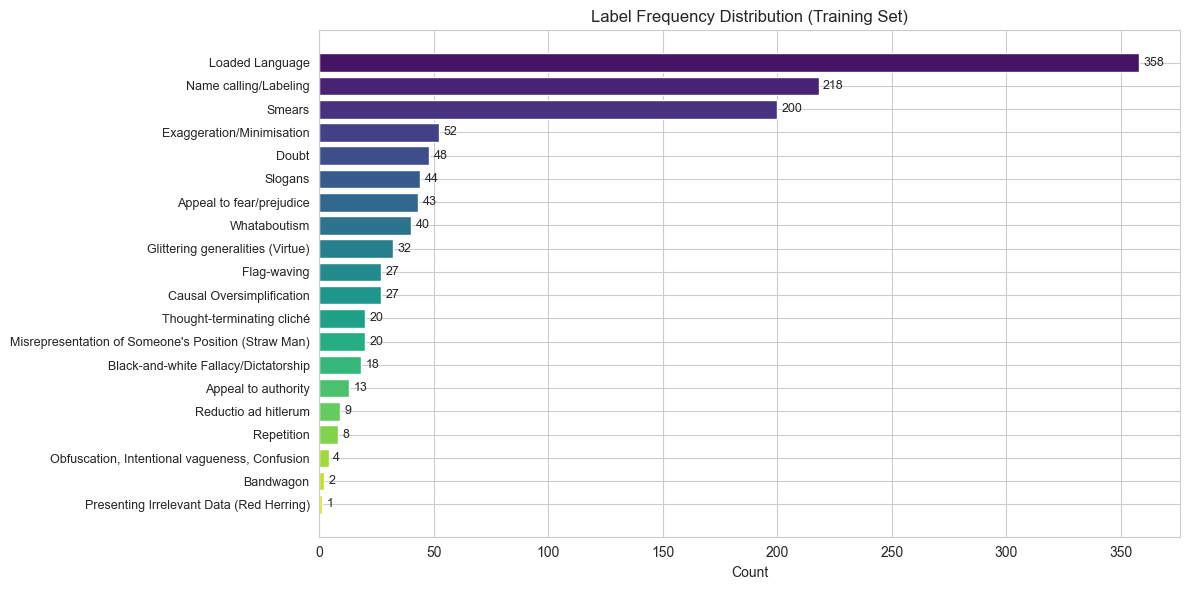


Samples with no labels: 143/688 (20.8%)
Avg labels per sample: 1.72
Max labels in a sample: 8


In [20]:
label_counts = train_labels.sum(axis=0)
sorted_idx = np.argsort(label_counts)[::-1]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    range(num_labels),
    label_counts[sorted_idx],
    color=sns.color_palette("viridis", num_labels)
)
ax.set_yticks(range(num_labels))
ax.set_yticklabels([idx2label[sorted_idx[i]] for i in range(num_labels)], fontsize=9)
ax.set_xlabel("Count")
ax.set_title("Label Frequency Distribution (Training Set)")
ax.invert_yaxis()

for i, (bar, idx) in enumerate(zip(bars, sorted_idx)):
    ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
            f"{int(label_counts[idx])}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

no_label_count = int((train_labels.sum(axis=1) == 0).sum())
print(f"\nSamples with no labels: {no_label_count}/{len(train_data)} ({100 * no_label_count / len(train_data):.1f}%)")
print(f"Avg labels per sample: {train_labels.sum(axis=1).mean():.2f}")
print(f"Max labels in a sample: {train_labels.sum(axis=1).astype(int).max()}")

### Labels Per Sample Distribution

- Most documents carry 1-2 labels, a few carry several.
- Getting all 20 decisions right on one document is hard. Subset accuracy will read low even for a decent model, so it is reported as the strict companion to the F1 metrics not as the headline.
- The no-label bar here is the same empty-label group seen above (~21% of train). The "predict nothing" case that sample F1 scores as 1.0 per empty document.


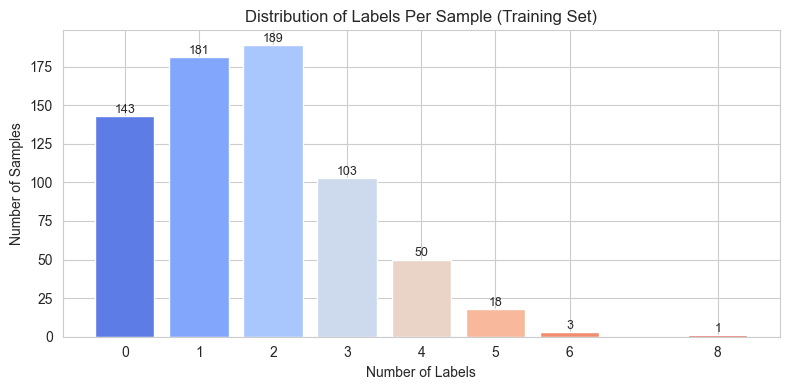

In [21]:
labels_per_sample = train_labels.sum(axis=1).astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
counts = Counter(labels_per_sample)
x_vals = sorted(counts.keys())
ax.bar(x_vals, [counts[x] for x in x_vals], color=sns.color_palette("coolwarm", len(x_vals)))
ax.set_xlabel("Number of Labels")
ax.set_ylabel("Number of Samples")
ax.set_title("Distribution of Labels Per Sample (Training Set)")
ax.set_xticks(x_vals)

for x in x_vals:
    ax.text(x, counts[x] + 2, str(counts[x]), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

### Label Co-occurrence Matrix

- The matrix shows several techniques co-occur frequently (e.g. Loaded Language with Name calling/Slogans). Model note: label dependencies could be captured with a chain/graph head, but with 688 training samples that adds parameters for little data. So the head keeps 20 independent sigmoids, and co-occurrence is instead used when reading errors: a false positive on a rare label sitting next to a true co-occurring label usually means borrowed confidence from a shared cue rather than a random mistake.


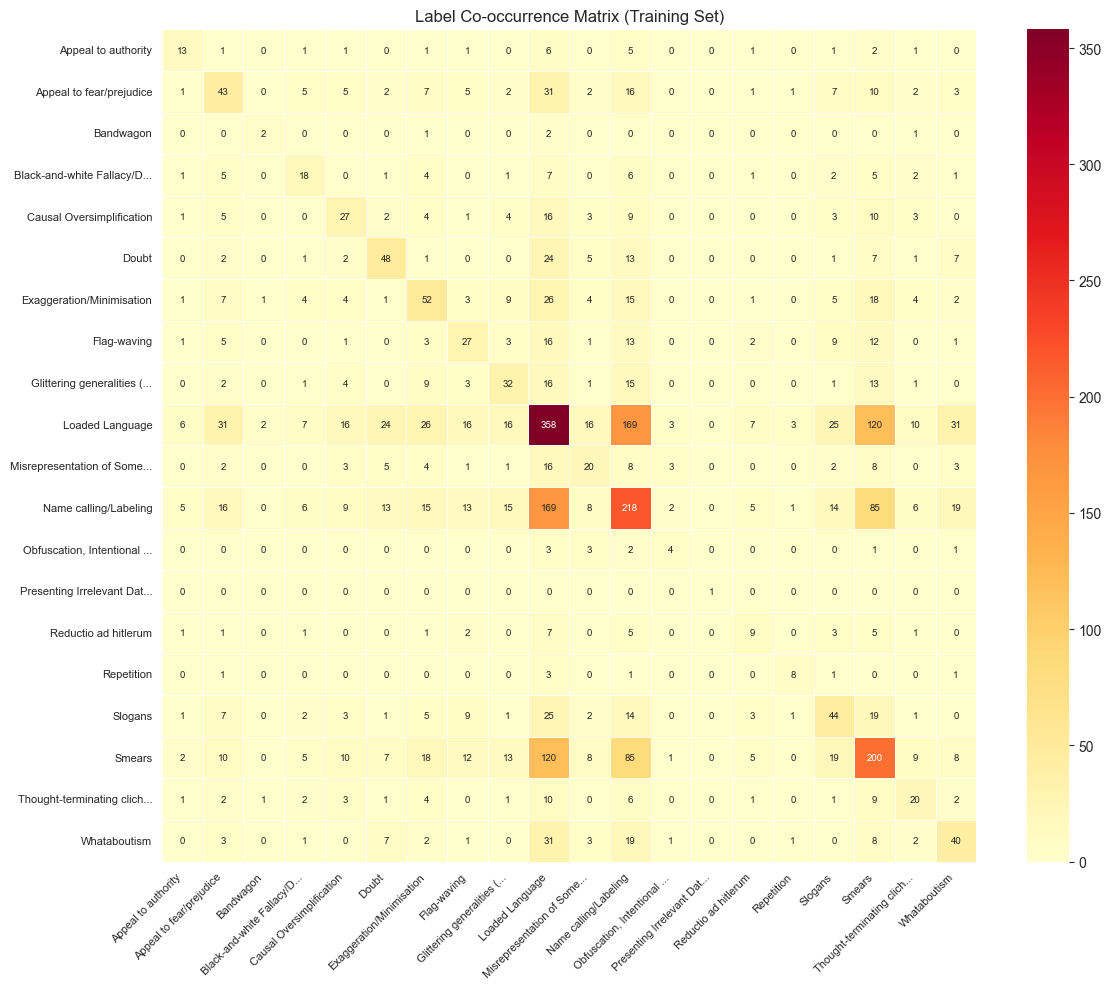

In [22]:
cooccur = np.zeros((num_labels, num_labels), dtype=int)
for row in train_labels:
    active = np.where(row == 1.0)[0]
    for i, j in combinations(active, 2):
        cooccur[i, j] += 1
        cooccur[j, i] += 1
    for i in active:
        cooccur[i, i] += 1

short_labels = [l[:25] + "..." if len(l) > 25 else l for l in all_labels]

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.zeros_like(cooccur, dtype=bool)
sns.heatmap(
    cooccur, mask=mask, annot=True, fmt="d", cmap="YlOrRd",
    xticklabels=short_labels, yticklabels=short_labels,
    linewidths=0.5, ax=ax, annot_kws={"size": 7}
)
ax.set_title("Label Co-occurrence Matrix (Training Set)")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### Text Length Distribution

- `MAX_LENGTH = 128`: the tail shown here fits under 128 with margin, so the tokenised check later can verify the assumption with no truncation.
- The length-vs-error analysis in the final is a hypothesis formed here, before any model exists, if long documents are harder for reasons unrelated to specific labels, error counts should rise with word count. This is tested with Spearman at the end.


C:\Users\alexd\AppData\Local\Temp\ipykernel_17540\650210920.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_for_box, labels=labels_for_box)


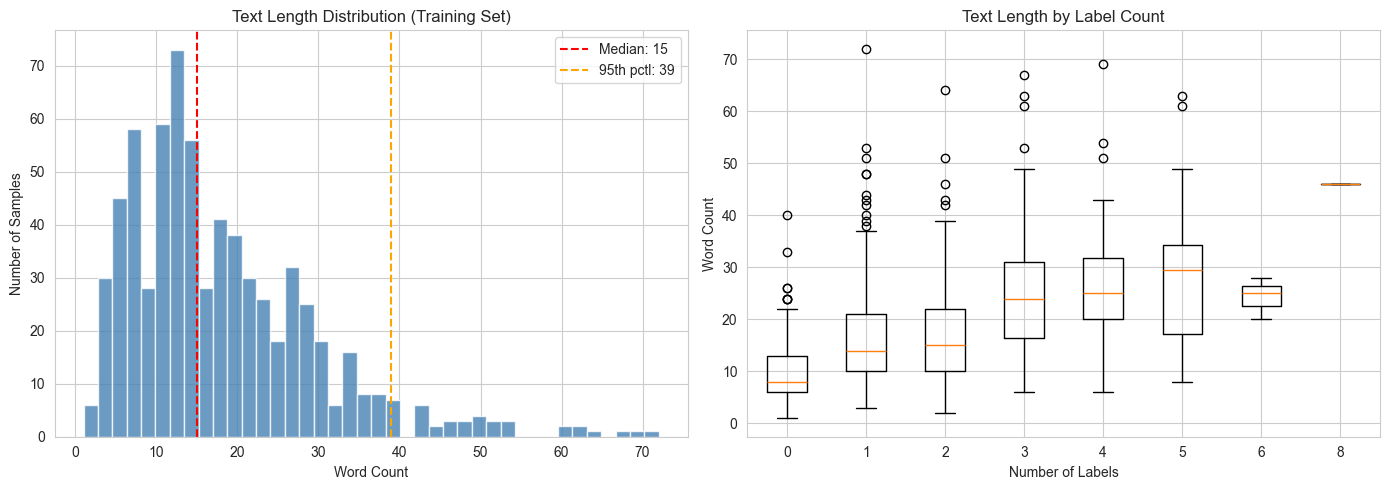

Word count stats:
  Min:    1
  Median: 15
  Mean:   18
  Max:    72
  95th pctl: 39


In [23]:
train_lengths = [len(text.split()) for text in train_texts]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_lengths, bins=40, color="steelblue", edgecolor="white", alpha=0.8)
median_val = np.median(train_lengths)
p95_val = np.percentile(train_lengths, 95)
axes[0].axvline(median_val, color="red", linestyle="--", label=f"Median: {median_val:.0f}")
axes[0].axvline(p95_val, color="orange", linestyle="--",
                label=f"95th pctl: {p95_val:.0f}")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Samples")
axes[0].set_title("Text Length Distribution (Training Set)")
axes[0].legend()

data_for_box = []
labels_for_box = []
for n in range(labels_per_sample.max() + 1):
    mask = labels_per_sample == n
    if mask.sum() > 0:
        data_for_box.append(np.array(train_lengths)[mask])
        labels_for_box.append(str(n))

axes[1].boxplot(data_for_box, labels=labels_for_box)
axes[1].set_xlabel("Number of Labels")
axes[1].set_ylabel("Word Count")
axes[1].set_title("Text Length by Label Count")

plt.tight_layout()
plt.show()

print("Word count stats:")
print(f"  Min:    {min(train_lengths)}")
print(f"  Median: {median_val:.0f}")
print(f"  Mean:   {np.mean(train_lengths):.0f}")
print(f"  Max:    {max(train_lengths)}")
print(f"  95th pctl: {p95_val:.0f}")

### Sample Text Inspection

- A random sample for a qualitative read on the annotation scheme: typical label combinations, how the empty-label documents look, and what register the texts come from. This is context for judging the error examples at the end.


In [24]:
np.random.seed(SEED)
sample_indices = np.random.choice(len(train_data), size=5, replace=False)

for idx in sample_indices:
    sample = train_data[idx]
    labels = sample["labels"] if sample["labels"] else ["(none)"]
    print(f"--- Sample {sample['id']} ---")
    print("Labels:", ", ".join(labels))
    word_count = len(sample["text"].split())
    print(f"Text ({word_count} words): {sample['text'][:300]}")
    print()

--- Sample 306_batch_2 ---
Labels: Name calling/Labeling
Text (13 words): THAT LOOK YOU GET WHEN YOUR BILLION DOLLAR VIRUS HAS A $20 CURE.

--- Sample 922_batch_2 ---
Labels: (none)
Text (5 words): Who built the cages, Joe?


--- Sample 271_batch_2 ---
Labels: Exaggeration/Minimisation, Glittering generalities (Virtue), Loaded Language
Text (34 words): STATES OF AMERICA

Used to think Trump was great but now seeing the whole system was rigged against him, I have to believe now that he is one of the greatest of all time!

--- Sample 353_batch_2 ---
Labels: Causal Oversimplification, Exaggeration/Minimisation, Flag-waving, Loaded Language, Name calling/Labeling
Text (32 words): 238 years ago we froze and starved in order to defeat the largest military force on earth to build a free nation
And you surrendered it because you're afraid of getting sick


--- Sample 340_batch_2 ---
Labels: Smears
Text (12 words): IF HE WAS ALIVE TODAY HE WOULD #WALKAWAY FROM
TODAY'S DEMOCRATIC PARTY




### Top Terms per Label

- A learnability check: distinct frequent terms per label mean the task is not purely deep semantics. There is usable lexical signal, while a few labels dominated by near-keyword cues are its shortcut risk (relevant when interpreting the error examples later). Note the stop-words are removed only for these plots; model input keeps full text, since function words carry signal too such as negation and pronouns.


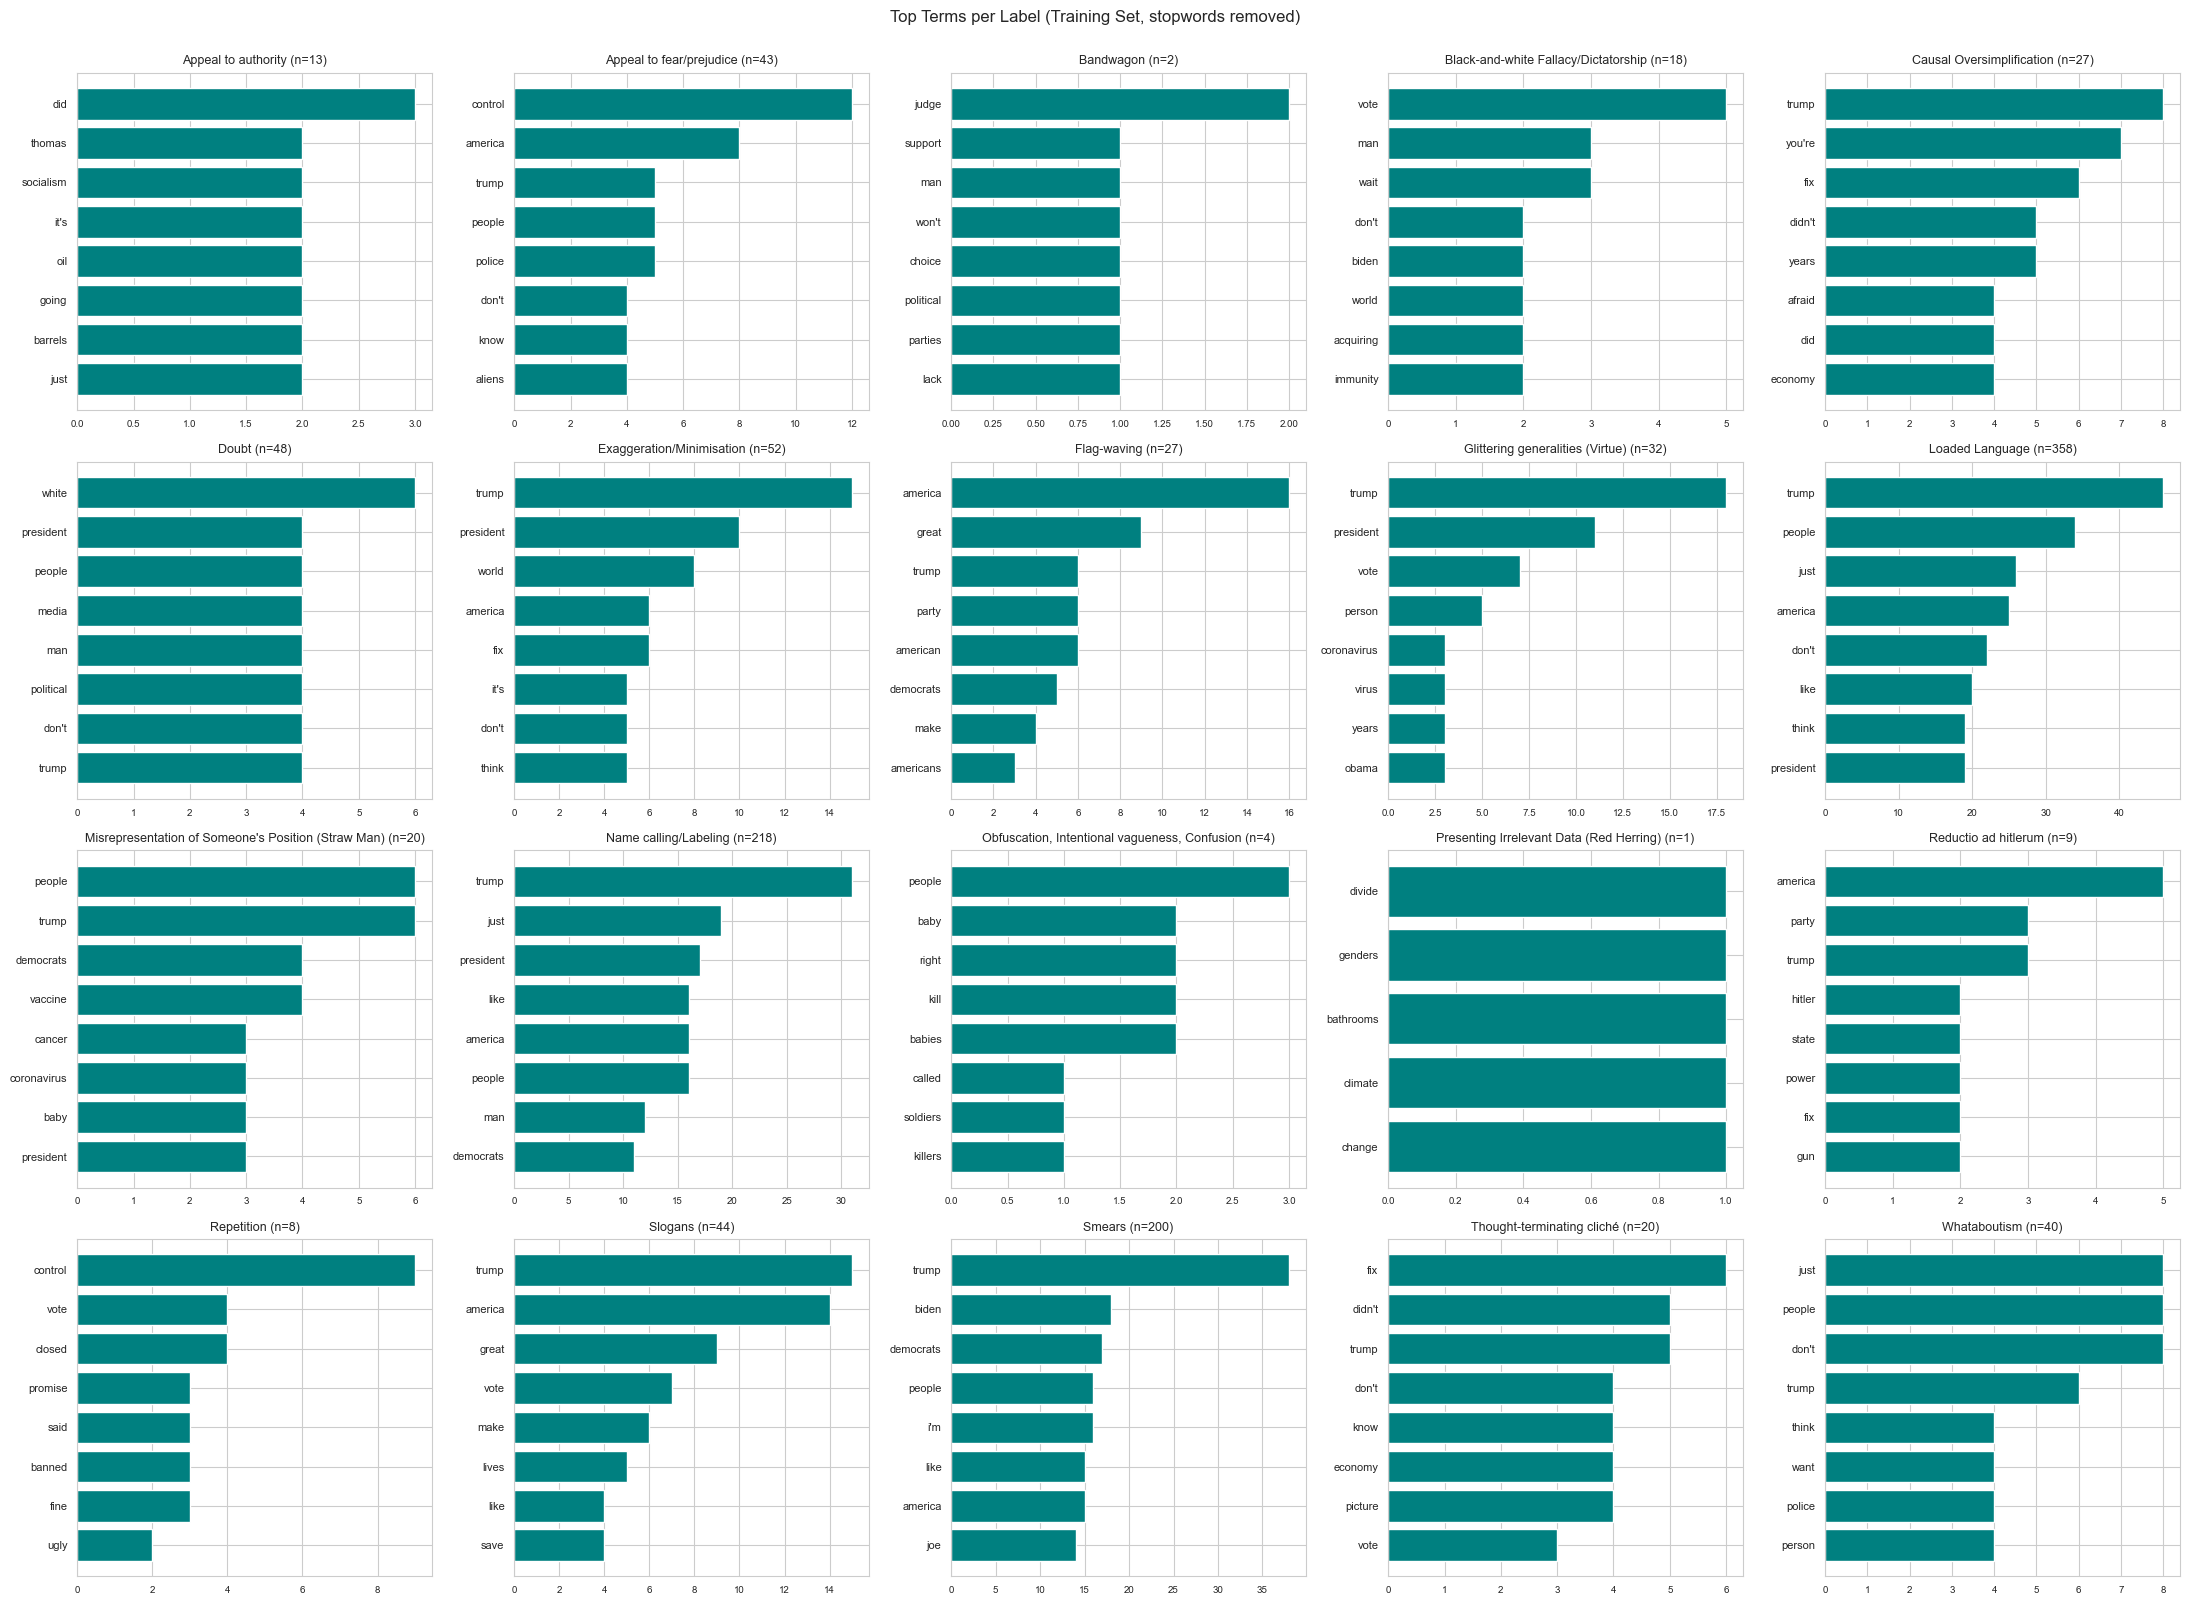

In [25]:
def top_terms(texts, n=8):
    words = []
    for t in texts:
        words.extend(w for w in re.findall(r"[a-z']+", t.lower())
                     if len(w) > 2 and w not in ENGLISH_STOP_WORDS)
    return Counter(words).most_common(n)

fig, axes = plt.subplots(4, 5, figsize=(22, 16))
for li in range(num_labels):
    ax = axes[li // 5][li % 5]
    label_texts = [train_texts[i] for i in range(len(train_texts)) if train_labels[i, li]]
    terms = top_terms(label_texts)
    ax.set_title(f"{idx2label[li]} (n={len(label_texts)})", fontsize=9)
    if not terms:
        ax.axis("off")
        continue
    names, counts = zip(*terms)
    ax.barh(range(len(names)), counts[::-1], color="teal")
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names[::-1], fontsize=8)
    ax.tick_params(axis="x", labelsize=7)

for ax in axes.flat[len(all_labels):]:
    ax.axis("off")
plt.suptitle("Top Terms per Label (Training Set, stopwords removed)", y=1.0)
plt.tight_layout()
plt.show()

## Preprocessing & Tokenisation

### Text Cleaning

- Newlines collapsed, HTML tags stripped, URLs replaced by a single `[URL]` token, whitespace squashed, layout/annotation artefacts only.
- No lowercasing (the uncased tokeniser does it), no stop-word removal, no stemming: emphasis markers (ALL-CAPS, !!!), quotes and punctuation are themselves propaganda signal (see the top-terms plots), and WordPiece already handles morphology.
- One function applied identically to train/dev/test. Split-specific rules would create exactly the distribution shift which is not ideal.


In [26]:
def clean_text(text):
    text = text.replace("\n", " ")
    text = re.sub(r"http\S+|www\.\S+", "[URL]", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_texts_clean = [clean_text(t) for t in train_texts]
dev_texts_clean = [clean_text(t) for t in dev_texts]
test_texts_clean = [clean_text(t) for t in test_texts]

print('Cleaning complete.')
print(f'Raw sample:   {train_texts[0][:150]}')
print(f'Clean sample: {train_texts_clean[0][:150]}')

Cleaning complete.
Raw sample:   THERE ARE ONLY TWO GENDERS

FEMALE 

MALE

Clean sample: THERE ARE ONLY TWO GENDERS FEMALE MALE


### DistilBERT Tokeniser

- `distilbert-base-uncased`: ~66M parameters / 4 layers vs BERT-base's 110M / 12. This is why this is used, it is roughly 2x faster per epoch with only a modest accuracy cost in practice, which matters because the full protocol (7-trial grid + 5-fold CV + retrain below) has to fit a modest Colab GPU.
- `MAX_LENGTH = 128` comes from the EDA length distribution; `padding="max_length"` keeps every batch rectangular so no dynamic-padding collator needed, at the cost of wasted compute on short texts which is acceptable at this scale. `truncation=True` stays on purely as a safety net; the next cell verifies nothing is actually cut.


In [27]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)
print(f'Tokeniser loaded: {MODEL_NAME}')
print(f'Max length: {MAX_LENGTH}')

# Tokenise splits
train_encodings = tokenizer(train_texts_clean, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_tensors="pt")
dev_encodings = tokenizer(dev_texts_clean, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_tensors="pt")
test_encodings = tokenizer(test_texts_clean, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_tensors="pt")

print(f'Train encodings: input_ids={train_encodings["input_ids"].shape}, attention_mask={train_encodings["attention_mask"].shape}')
print(f'Dev encodings:   input_ids={dev_encodings["input_ids"].shape}')
print(f'Test encodings:  input_ids={test_encodings["input_ids"].shape}')

# Decode a sample
sample_ids = train_encodings["input_ids"][0]
print(f'\nDecoded sample: {tokenizer.decode(sample_ids, skip_special_tokens=True)[:300]}')

Tokeniser loaded: distilbert-base-uncased
Max length: 128
Train encodings: input_ids=torch.Size([688, 128]), attention_mask=torch.Size([688, 128])
Dev encodings:   input_ids=torch.Size([63, 128])
Test encodings:  input_ids=torch.Size([200, 128])

Decoded sample: there are only two genders female male


### Tokenised Length Verification

- Test the `MAX_LENGTH` assumption instead of trusting it: counts come from the attention mask (real tokeniser output, not word splits). Decision rule: if anything were truncated we would either raise `MAX_LENGTH` or knowingly accept information loss; at 0% truncated, `MAX_LENGTH=128` costs only padding compute.


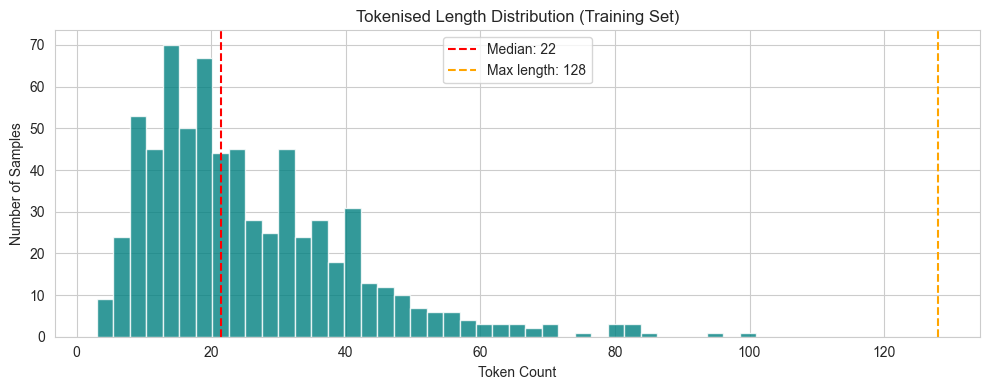

Token length stats:
  Min:      3
  Median:   22
  Mean:     25
  Max:      101
  Truncated (at 128): 0/688 (0.0%)


In [28]:
# Verify token length distribution after tokenisation
train_token_lens = [sum(mask) for mask in train_encodings["attention_mask"].tolist()]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(train_token_lens, bins=40, color="teal", edgecolor="white", alpha=0.8)
ax.axvline(np.median(train_token_lens), color="red", linestyle="--",
           label=f"Median: {np.median(train_token_lens):.0f}")
ax.axvline(MAX_LENGTH, color="orange", linestyle="--",
           label=f"Max length: {MAX_LENGTH}")
ax.set_xlabel("Token Count")
ax.set_ylabel("Number of Samples")
ax.set_title("Tokenised Length Distribution (Training Set)")
ax.legend()
plt.tight_layout()
plt.show()

truncated_count = sum(1 for l in train_token_lens if l >= MAX_LENGTH)
print(f"Token length stats:")
print(f"  Min:      {min(train_token_lens)}")
print(f"  Median:   {np.median(train_token_lens):.0f}")
print(f"  Mean:     {np.mean(train_token_lens):.0f}")
print(f"  Max:      {max(train_token_lens)}")
print(f"  Truncated (at {MAX_LENGTH}): {truncated_count}/{len(train_token_lens)} ({100 * truncated_count / len(train_token_lens):.1f}%)")

## Dataset & DataLoader

- `BATCH_SIZE = 16` is held fixed everywhere (baseline, every trial, every fold, retrain below) so experiments differ only in the axes under test; it is memory-safe for DistilBERT at 128 tokens and gives 43 optimiser steps per epoch. This is plenty of gradient noise for 688 samples.
- `shuffle=True` on train only; dev/test loaders never shuffle, so metric histories are comparable across epochs and trials.
- Labels are `float32` tensors (BCE/ASL targets are floats, not class indices), and `drop_last=False` keeps evaluation batches complete.


In [29]:
class PropagandaDataset(Dataset):
    def __init__(self, encodings, labels):
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.labels = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "labels": self.labels[idx],
        }

BATCH_SIZE = 16

train_dataset = PropagandaDataset(train_encodings, train_labels)
dev_dataset = PropagandaDataset(dev_encodings, dev_labels)
test_dataset = PropagandaDataset(test_encodings, test_labels)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
dev_loader = DataLoader(dev_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size: {BATCH_SIZE}")
print(f"Train batches: {len(train_loader)}")
print(f"Dev batches:   {len(dev_loader)}")
print(f"Test batches:  {len(test_loader)}")

Batch size: 16
Train batches: 43
Dev batches:   4
Test batches:  13


In [20]:
# Verify a batch
batch = next(iter(train_loader))
print(f"Batch input_ids shape:     {batch['input_ids'].shape}")
print(f"Batch attention_mask shape: {batch['attention_mask'].shape}")
print(f"Batch labels shape:         {batch['labels'].shape}")
print(f"Batch labels dtype:         {batch['labels'].dtype}")

sample_labels = batch['labels'][0]
active = [idx2label[i] for i, v in enumerate(sample_labels) if v == 1.0]
print(f"\nFirst sample labels: {active if active else '(none)'}")
print(f"First sample text: {tokenizer.decode(batch['input_ids'][0], skip_special_tokens=True)[:200]}")

Batch input_ids shape:     torch.Size([16, 128])
Batch attention_mask shape: torch.Size([16, 128])
Batch labels shape:         torch.Size([16, 20])
Batch labels dtype:         torch.float32

First sample labels: ['Causal Oversimplification', 'Glittering generalities (Virtue)', 'Smears']
First sample text: here ' s new conservative leader erin o ' toole and justin trudeau at roughly the same age. o ' toole signed up for the canadians forces while trudeau was a part - time ski instructor living off a mul


## Model Definition

- `problem_type="multi_label_classification"` documents the task in the model config: labels are independent binary decisions (BCE semantics), not mutually exclusive classes (softmax/CE). The loss is applied outside the model via `criterion`, but keeping the flag consistent avoids any single-label assumption resurfacing in HF internals.
- Independent sigmoids are a deliberate assumption: the head cannot represent "Loaded Language and Slogans" as a joint event. A label-dependency layer would overfit 688 samples. So we accept independence and compensate with the co-occurrence EDA plus per-label thresholds.
- `DROPOUT = 0.3` sets DistilBERT's internal dropout (attention/hidden layers): with ~66M parameters on 688 documents, regularisation beats capacity. The value is also one of the tuned axes (0.2/0.3/0.4 below).
- The stock head (first-token/CLS position -> linear) is used rather than custom pooling: simple, well-tested, and strong enough as a baseline before adding modelling complexity.


In [21]:
DROPOUT = 0.3

model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification",
    dropout=DROPOUT,
)
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: {MODEL_NAME}")
print(f"Task type: multi_label_classification (sigmoid + BCE)")
print(f"Dropout: {DROPOUT}")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: distilbert-base-uncased
Task type: multi_label_classification (sigmoid + BCE)
Dropout: 0.3
Total parameters:     66,968,852
Trainable parameters: 66,968,852


In [22]:
# Forward pass check
model.eval()
with torch.no_grad():
    sample = next(iter(train_loader))
    outputs = model(
        input_ids=sample["input_ids"].to(device),
        attention_mask=sample["attention_mask"].to(device),
    )

logits = outputs.logits
probs = torch.sigmoid(logits)
print(f"Logits shape: {tuple(logits.shape)}")
print(f"Probabilities shape: {tuple(probs.shape)}")
print(f"Logits range: [{logits.min():.3f}, {logits.max():.3f}]")
print(f"Probabilities range: [{probs.min():.3f}, {probs.max():.3f}]")
print(f"Predictions at 0.5 threshold (first sample): {(probs[0] > 0.5).sum().item()} labels active")

Logits shape: (16, 20)
Probabilities shape: (16, 20)
Logits range: [-0.190, 0.211]
Probabilities range: [0.453, 0.553]
Predictions at 0.5 threshold (first sample): 10 labels active


## Loss Functions

Two loss functions selected as a hyperparameters:
1. Capped weighted BCE: `pos_weight = N_neg / N_pos` per label, capped at
   `POS_WEIGHT_CAP = 50`. The uncapped maximum is 687 (Red Herring, n=1). Would otherwise
   dominate every gradient step and badly miscalibrate the rare-label
   logits, which then breaks threshold selection. The cap keeps up to ~50x positive
   emphasis without the destabilising tail; the cell reports how many labels were
   clipped.
2. Asymmetric Loss: (Ben-Baruch et al., ICCV 2021, official formulation (github.com/Alibaba-MIIL/ASL)):
   asymmetric probability margin (ignore easy negatives) plus asymmetric focal
   focusing. Designed for long-tailed multi-label data and replaces pos_weight
   rebalancing entirely. Uses `reduction="mean"` for drop-in parity with
   `BCEWithLogitsLoss` modified from the official code which uses sum reduction.

`build_criterion(kind, labels)` builds either loss. For weighted BCE it always
estimates the weights from the given training rows only (fold-train or
train+dev), so held-out labels can never leak into the loss.

- `BCEWithLogitsLoss` consumes logits, fused sigmoid + BCE in a numerically stable log-sum-exp form instead of `BCELoss(sigmoid(x))`, which can overflow as `log(0)` on saturated logits.
- `pos_weight` multiplies only a label's positive term which rebalances that label's precision/recall trade-off without re-scaling its negatives. This is what rare labels need, and why an uncapped value (687) would instead take over the whole gradient.


In [23]:
# BCEWithLogitsLoss
POS_WEIGHT_CAP = 50.0

pos_counts = train_labels.sum(axis=0)
neg_counts = len(train_labels) - pos_counts
pos_weight_raw = neg_counts / np.maximum(pos_counts, 1.0)
pos_weight = torch.tensor(np.minimum(pos_weight_raw, POS_WEIGHT_CAP), dtype=torch.float32)

print("Per-label pos_weight (raw -> used):")
print(f"{'Label':<55} {'Pos':>5} {'Raw':>8} {'Used':>8}")
print("-" * 80)
for i in np.argsort(pos_weight_raw)[::-1]:
    flag = "  *capped*" if pos_weight_raw[i] > POS_WEIGHT_CAP else ""
    print(f"{idx2label[i]:<55} {int(pos_counts[i]):>5} "
          f"{pos_weight_raw[i]:>8.2f} {pos_weight[i].item():>8.2f}{flag}")
n_clipped = int((pos_weight_raw > POS_WEIGHT_CAP).sum())
print(f"\nMean raw: {pos_weight_raw.mean():.2f} | mean used: {pos_weight.mean().item():.2f} "
      f"| max raw: {pos_weight_raw.max():.2f} | "
      f"clipped: {n_clipped}/{num_labels} labels at cap {POS_WEIGHT_CAP:g}")


# ASL
class AsymmetricLoss(torch.nn.Module):
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        xs_pos = p
        xs_neg = 1 - p
        # Asymmetric probability margin: ignore easy negatives
        if self.clip and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)

        los_pos = targets * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1 - targets) * torch.log(xs_neg.clamp(min=self.eps))
        loss = los_pos + los_neg

        # Asymmetric focusing (focal-style weight, treated as constant like the
        # official disable_torch_grad_focal_loss=True)
        if self.gamma_neg > 0 or self.gamma_pos > 0:
            with torch.no_grad():
                pt = xs_pos * targets + xs_neg * (1 - targets)
                gamma = self.gamma_pos * targets + self.gamma_neg * (1 - targets)
                weight = torch.pow(1 - pt, gamma)
            loss = loss * weight

        return -loss.mean()


def build_criterion(kind, labels=None):
    """Loss for a trial: 'bce' (capped pos_weight) or 'asl'.

    labels: rows used for training when estimating pos_weight. Pass fold-train or
    train+dev rows so held-out labels never leak into the weights.
    """
    if kind == "asl":
        return AsymmetricLoss(gamma_neg=4, gamma_pos=1, clip=0.05)
    y = train_labels if labels is None else labels
    pos = y.sum(axis=0)
    pw = np.minimum((len(y) - pos) / np.maximum(pos, 1.0), POS_WEIGHT_CAP)
    return torch.nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(pw, dtype=torch.float32).to(device))


criterion = build_criterion("bce", train_labels)
print(f"\ncriterion = capped weighted BCE (cap={POS_WEIGHT_CAP:g}); "
      f"build_criterion('asl', ...) returns AsymmetricLoss")


Per-label pos_weight (raw -> used):
Label                                                     Pos      Raw     Used
--------------------------------------------------------------------------------
Presenting Irrelevant Data (Red Herring)                    1   687.00    50.00  *capped*
Bandwagon                                                   2   343.00    50.00  *capped*
Obfuscation, Intentional vagueness, Confusion               4   171.00    50.00  *capped*
Repetition                                                  8    85.00    50.00  *capped*
Reductio ad hitlerum                                        9    75.44    50.00  *capped*
Appeal to authority                                        13    51.92    50.00  *capped*
Black-and-white Fallacy/Dictatorship                       18    37.22    37.22
Thought-terminating cliché                                 20    33.40    33.40
Misrepresentation of Someone's Position (Straw Man)        20    33.40    33.40
Causal Oversimplificati

In [24]:
# Verify loss computation on a real batch
model.train()
batch = next(iter(train_loader))
outputs = model(
    input_ids=batch["input_ids"].to(device),
    attention_mask=batch["attention_mask"].to(device),
)
loss = criterion(outputs.logits, batch["labels"].to(device))

# Compare with unweighted loss for reference
loss_unweighted = torch.nn.BCEWithLogitsLoss()(outputs.logits, batch["labels"].to(device))

print(f"Weighted loss:   {loss.item():.4f}")
print(f"Unweighted loss: {loss_unweighted.item():.4f}")
print(f"Ratio: {loss.item() / loss_unweighted.item():.2f}x")

print(f"\nLoss is finite: {torch.isfinite(loss).item()}")
print(f"Loss requires grad: {loss.requires_grad}")

# Same batch through ASL
loss_asl = build_criterion("asl")(outputs.logits, batch["labels"].to(device))
print(f"ASL loss:        {loss_asl.item():.4f}")
print(f"ASL finite:      {torch.isfinite(loss_asl).item()}")
print(f"ASL requires grad: {loss_asl.requires_grad}")


Weighted loss:   1.0689
Unweighted loss: 0.6988
Ratio: 1.53x

Loss is finite: True
Loss requires grad: True
ASL loss:        0.0496
ASL finite:      True
ASL requires grad: True


## Training Configuration

- AdamW: decoupled weight decay is typically used for transformer fine-tuning (plain Adam entangles L2 with its adaptive scaling).
- LR 2e-5: BERT-family fine-tuning lives in 1e-5-5e-5; higher destroys the pretrained representation within an epoch, lower underfits. LR gets the densest grid because it matters most.
- WARMUP 0.1 + linear decay: the fresh classification head starts mis-scaled; warmup prevents early loss spikes, decay eases into the optimum.
- GRAD_CLIP 1.0: bounds occasional spike steps. This is kept as hygiene even though `pos_weight` is now capped.
- EPOCHS 15 / PATIENCE 3: Epochs was raised from 10 after a full run which showed the best trials still improved at the ceiling (`best_epoch=10` on 3 of 7 trials). Early stopping on dev macro F1 is the real stopper now.
- Monitor = dev macro F1: macro weights Red Herring (n=1) the same as Loaded Language (n=358), so selection optimises the rare techniques which is the hard part of this task instead of the frequent ones.


In [25]:
# Hyperparameters
EPOCHS = 15           # was 10: winner hit the ceiling (best_epoch=10), raise so training can converge
PATIENCE = 3           # early stopping patience on dev macro F1
LR = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
GRAD_CLIP = 1.0
CHECKPOINT_PATH = "best_model.pt"

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps,
)

print(f"Epochs:         {EPOCHS}")
print(f"LR:             {LR}")
print(f"Weight decay:   {WEIGHT_DECAY}")
print(f"Grad clip:      {GRAD_CLIP}")
print(f"Warmup:         {int(total_steps * WARMUP_RATIO)} steps ({WARMUP_RATIO:.0%})")
print(f"Total steps:    {total_steps}")
print(f"Early stopping: patience={PATIENCE} (monitor dev macro F1)")

Epochs:         15
LR:             2e-05
Weight decay:   0.01
Grad clip:      1.0
Warmup:         64 steps (10%)
Total steps:    645
Early stopping: patience=3 (monitor dev macro F1)


## Evaluation Function

- Macro F1: equal weight per technique. This is the selection metric, because it is the only one that refuses to ignore the 1-2-shot labels. A target performance level of at least 35% on unseen text for predicting meme techniques as it is not a critical scenario. Also, this rather low percentage is governed by a caveat. From the label-frequency EDA, 16 of 20 labels only have fewer than 50 training examples and macro averages over those labels. So this creates a data-implied ceiling score. Also, due to the requirement using a specialised persuasion-, propaganda- or rhetoric-labelled data model is not permitted which would be beneficial for achieving greater scores.
- Micro F1: pooled label decisions dominated by frequent labels, the total volume correct view.
- Weighted F1: support-weighted middle ground; flags when macro and micro disagree wildly.
- Sample F1: per-document view. The custom implementation scores predict nothing on an unlabelled document as 1.0, so an all-zero predictor already gets ~0.205 on this test set.
- Hamming loss: fraction of the 20 decisions that are wrong; reacts to total error volume rather than precision/recall balance.
- Subset accuracy: exact match of the whole 20-bit vector which is the deliberately strict end of the spectrum.
- `zero_division=0` is applied everywhere so a label with no predicted positives contributes 0 instead of NaN; macro stays well-defined.
- Probabilities are returned alongside predictions so both threshold rules reuse a single forward pass and identical logits.


In [12]:
def sample_f1(y_true, y_pred):
    scores = []
    for t, p in zip(y_true, y_pred):
        if t.sum() == 0 and p.sum() == 0:
            scores.append(1.0)  # no true labels and none predicted
        else:
            scores.append(f1_score(t[None, :], p[None, :], average="samples", zero_division=0))
    return float(np.mean(scores))


def evaluate(model, loader, threshold=0.5):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            outputs = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
            )
            all_logits.append(outputs.logits.cpu())
            all_labels.append(batch["labels"])
    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels).numpy()
    probs = torch.sigmoid(logits).numpy()
    preds = (probs >= threshold).astype(int)

    metrics = {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
"sample_f1": sample_f1(labels, preds),
        "hamming_loss": hamming_loss(labels, preds),
        "subset_accuracy": float((preds == labels).all(axis=1).mean()),
    }
    return metrics, probs, labels, preds

## Training Loop

- The checkpoint is written only when dev macro F1 improves, and early stopping counts epochs without improvement (patience 3, counter reset on any improvement). Every downstream stage starts from a run's best-on-dev weights, not from the last epoch;
- Gradients are clipped before `optimizer.step()`, and the LR scheduler steps per batch, so warmup/decay are measured in optimiser updates rather than epochs.
- Dev is evaluated once per epoch through the same `evaluate()` used everywhere else, so learning curves, tuning and final reporting share one metric implementation.


In [27]:
history = {
    "train_loss": [], "dev_micro_f1": [], "dev_macro_f1": [],
    "dev_weighted_f1": [], "dev_hamming_loss": [],
}
best_macro_f1 = -1.0
best_epoch = -1
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
    for batch in pbar:
        optimizer.zero_grad()
        outputs = model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
        )
        loss = criterion(outputs.logits, batch["labels"].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_loss / len(train_loader)
    dev_metrics, _, _, _ = evaluate(model, dev_loader)

    history["train_loss"].append(avg_train_loss)
    history["dev_micro_f1"].append(dev_metrics["micro_f1"])
    history["dev_macro_f1"].append(dev_metrics["macro_f1"])
    history["dev_weighted_f1"].append(dev_metrics["weighted_f1"])
    history["dev_hamming_loss"].append(dev_metrics["hamming_loss"])

    print(
        f"Epoch {epoch}: train_loss={avg_train_loss:.4f} | "
        f"dev microF1={dev_metrics['micro_f1']:.4f} "
        f"macroF1={dev_metrics['macro_f1']:.4f} "
        f"weightedF1={dev_metrics['weighted_f1']:.4f} "
        f"hamming={dev_metrics['hamming_loss']:.4f}"
    )

    if dev_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = dev_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"  -> new best macro F1 ({best_macro_f1:.4f}), checkpoint saved")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (best epoch: {best_epoch})")
            break

print(f"\nTraining complete. Best epoch: {best_epoch}, dev macro F1: {best_macro_f1:.4f}")

Epoch 1/15:   0%|          | 0/43 [00:00<?, ?it/s]

Epoch 1: train_loss=1.1579 | dev microF1=0.1216 macroF1=0.0827 weightedF1=0.1256 hamming=0.4587
  -> new best macro F1 (0.0827), checkpoint saved


Epoch 2/15:   0%|          | 0/43 [00:00<?, ?it/s]

Epoch 2: train_loss=1.1300 | dev microF1=0.2327 macroF1=0.1492 weightedF1=0.3400 hamming=0.3873
  -> new best macro F1 (0.1492), checkpoint saved


Epoch 3/15:   0%|          | 0/43 [00:00<?, ?it/s]

...

Epoch 13: train_loss=0.6679 | dev microF1=0.3683 macroF1=0.2238 weightedF1=0.4706 hamming=0.1770
  -> new best macro F1 (0.2238), checkpoint saved


Epoch 14/15:   0%|          | 0/43 [00:00<?, ?it/s]

Epoch 14: train_loss=0.6563 | dev microF1=0.3540 macroF1=0.2145 weightedF1=0.4509 hamming=0.1738


Epoch 15/15:   0%|          | 0/43 [00:00<?, ?it/s]

Epoch 15: train_loss=0.6492 | dev microF1=0.3704 macroF1=0.2236 weightedF1=0.4691 hamming=0.1754

Training complete. Best epoch: 13, dev macro F1: 0.2238


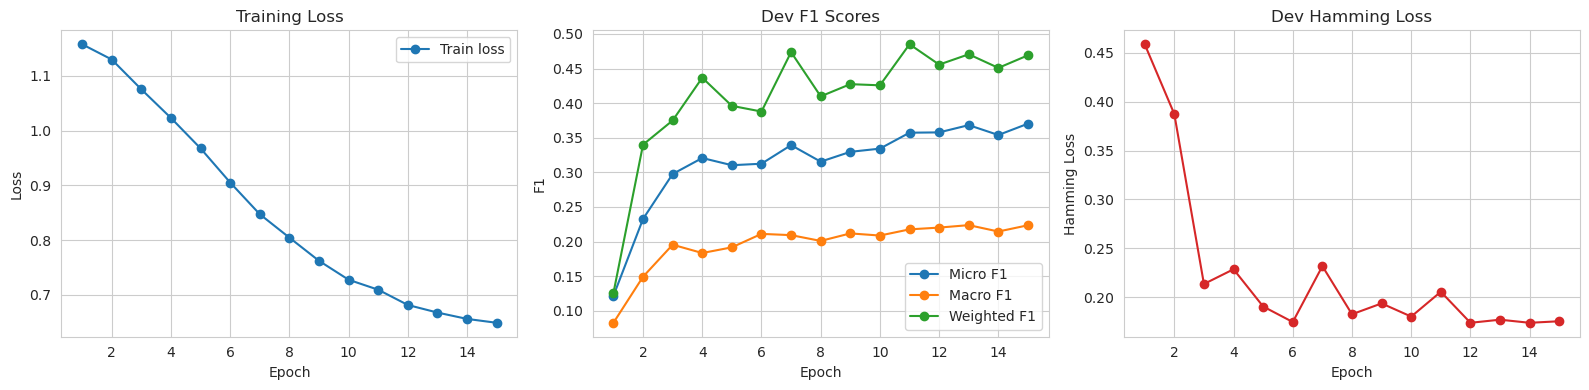

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
epochs_run = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs_run, history["train_loss"], marker="o", label="Train loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")
axes[0].legend()

axes[1].plot(epochs_run, history["dev_micro_f1"], marker="o", label="Micro F1")
axes[1].plot(epochs_run, history["dev_macro_f1"], marker="o", label="Macro F1")
axes[1].plot(epochs_run, history["dev_weighted_f1"], marker="o", label="Weighted F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1")
axes[1].set_title("Dev F1 Scores")
axes[1].legend()

axes[2].plot(epochs_run, history["dev_hamming_loss"], marker="o", color="tab:red")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Hamming Loss")
axes[2].set_title("Dev Hamming Loss")

plt.tight_layout()
plt.show()

### Learning Curves: Convergence

- Left - training loss: falls monotonically (~1.16 -> ~0.65, about -44%) with a decelerating slope and no spikes or oscillations. That shape means the optimiser is converging stably: warmup, linear decay and gradient clipping are doing their job. A diverging run would show a rising or erratic loss instead.
- Middle/Right - dev F1 and hamming: micro F1 rises ~0.12 -> ~0.37 and hamming loss falls ~0.46 -> ~0.17 in step with the training loss, so the falling loss is buying real generalisation, not just memorisation of training texts.
- Late epochs: the loss curve flattens (epoch-to-epoch gains shrink) while dev metrics oscillate around a slowly rising level. The practical signature of convergence: further epochs would trade compute for marginal movement.


### Learning Curves: Overfitting / Underfitting Verdict

- Underfitting: ruled out. Train loss drops ~44% and every dev metric improves sharply from epoch 1 onward; the model has enough capacity to learn the task and is using it.
- Classic overfitting: not present in this run. Overfitting would show train loss falling while dev F1 peaks early and then deteriorates. Here dev macro F1 keeps pace through the budget (best at epoch 13 of 15) and never enters a sustained decline. The still-falling loss next to a flattening dev curve means we are approaching the overfitting regime, not inside it, the small late gap is mild.
- The tuning trials show the other side of the picture: the winner's epoch log peaks on dev (~epoch 11), then drifts down while its train loss keeps falling, mild late-stage overfitting, caught by early stopping (patience 3, stopped at epoch 14), with the checkpoint logic preserving the pre-decline weights. The same mechanism protects this baseline run.
- Ignore single-epoch wiggles. Dev has only 63 documents, so a handful of label flips moves macro F1 by ~0.01; the visible ±0.01-0.02 oscillation between adjacent epochs is sampling noise, not a regime change, which is exactly why stopping uses patience 3 rather than reacting to any one epoch.
- Verdict: converged, with mild and controlled overfitting pressure at the tail, neither underfitting nor unconstrained overfitting. The baseline's best epoch (13) sitting close to the 15-epoch budget is the same evidence that led to raising `EPOCHS` from 10 in the first place.


In [29]:
# Load best checkpoint for subsequent evaluation
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
best_metrics, best_probs, best_labels, best_preds = evaluate(model, dev_loader)
print("Dev set metrics (best checkpoint):")
for k, v in best_metrics.items():
    print(f"  {k}: {v:.4f}")

Dev set metrics (best checkpoint):
  micro_f1: 0.3683
  macro_f1: 0.2238
  weighted_f1: 0.4706
  sample_f1: 0.4086
  hamming_loss: 0.1770
  subset_accuracy: 0.1905


## Hyperparameter Tuning

- Grid over learning rate, dropout, and loss type (capped weighted BCE vs ASL).
- Each trial trains a fresh model with early stopping; the trial with the best dev macro F1 wins as it is the main performance metric for this unbalanced dataset problem. The best checkpoint is then loaded for threshold tuning and test evaluation below.
- Trial differences are on
the same order as split-to-split variance (compare the k-fold sigma below). Treat the
result as a coarse refinement of the baseline, not a precise ranking of configs.

- lr (1e-5 / 2e-5 / 3e-5): the most sensitive knob for fine-tuning; densest sweep.
- dropout (0.2 / 0.3 / 0.4): the regularisation dial for a 688-sample set.
- loss (capped BCE vs ASL): the actual modelling question of this notebook. ASL is only paired with the two most promising lr/dropout cells to stay balance speed and cost, so the loss comparison is not a full factorial. This is stated as a limitation.
- Every trial starts fresh from the pretrained checkpoint (no warm-starting from another trial) and uses the same train/dev splits, so row-to-row differences are attributable to the hyperparameters, up to the single-seed noise.
- Only the winner's checkpoint survives (`hp04bs` deletes the rest), and `best_result` then parameterises k-fold CV, threshold tuning and the retrain. One selection, used consistently downstream.


In [30]:
def run_experiment(lr, dropout, loss, tag, epochs=None):
    epochs = EPOCHS if epochs is None else epochs
    trial_model = DistilBertForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=num_labels,
        problem_type="multi_label_classification",
        dropout=dropout,
    ).to(device)

    opt = torch.optim.AdamW(trial_model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(
        opt,
        num_warmup_steps=int(total_steps * WARMUP_RATIO),
        num_training_steps=total_steps,
    )
    ckpt_path = f"trial_{tag}.pt"
    trial_criterion = build_criterion(loss, train_labels)

    best_macro_f1 = -1.0
    best_epoch = 0
    no_improve = 0
    history = {"train_loss": [], "dev_macro_f1": []}

    for epoch in range(1, epochs + 1):
        trial_model.train()
        running = 0.0
        pbar = tqdm(train_loader, desc=f"trial {tag} | epoch {epoch}/{epochs}", leave=False)
        for batch in pbar:
            opt.zero_grad()
            outputs = trial_model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device))
            batch_loss = trial_criterion(outputs.logits, batch["labels"].to(device))
            batch_loss.backward()
            torch.nn.utils.clip_grad_norm_(trial_model.parameters(), GRAD_CLIP)
            opt.step()
            sched.step()
            running += batch_loss.item()
            pbar.set_postfix(loss=f"{batch_loss.item():.4f}")

        dev_metrics, _, _, _ = evaluate(trial_model, dev_loader)
        history["train_loss"].append(running / len(train_loader))
        history["dev_macro_f1"].append(dev_metrics["macro_f1"])
        print(f"  epoch {epoch}: train_loss={history['train_loss'][-1]:.4f} "
              f"dev macroF1={dev_metrics['macro_f1']:.4f}")

        if dev_metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = dev_metrics["macro_f1"]
            best_epoch = epoch
            no_improve = 0
            torch.save(trial_model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                print(f"  early stopping at epoch {epoch}")
                break

    del trial_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {"tag": tag, "lr": lr, "dropout": dropout, "loss": loss,
            "best_epoch": best_epoch, "best_macro_f1": best_macro_f1,
            "checkpoint": ckpt_path, "history": history}



=== Trial 0: lr=1e-05, dropout=0.3, loss=bce ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trial 0 | epoch 1/15:   0%|          | 0/43 [00:00<?, ?it/s]

  epoch 1: train_loss=1.1569 dev macroF1=0.1181


...

  epoch 12: train_loss=0.0178 dev macroF1=0.2673


trial 6 | epoch 13/15:   0%|          | 0/43 [00:00<?, ?it/s]

  epoch 13: train_loss=0.0170 dev macroF1=0.2722


trial 6 | epoch 14/15:   0%|          | 0/43 [00:00<?, ?it/s]

  epoch 14: train_loss=0.0165 dev macroF1=0.2711
  early stopping at epoch 14

=== Hyperparameter search results (by dev macro F1) ===
trial    lr dropout loss  best_epoch dev_macro_f1
    6 2e-05     0.2  asl          11       0.2771
    4 2e-05     0.4  bce          11       0.2534
    2 3e-05     0.3  bce           4       0.2470
    5 2e-05     0.3  asl          11       0.2409
    1 2e-05     0.3  bce           9       0.2285
    3 2e-05     0.2  bce           5       0.2269
    0 1e-05     0.3  bce           6       0.1919


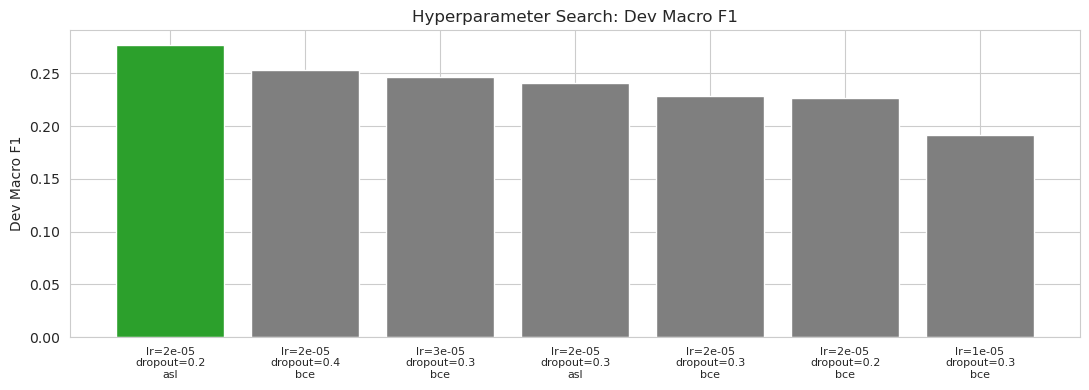

In [31]:
# Grid over learning rate, dropout, and loss type
HYPERPARAM_CONFIGS = [
    {"lr": 1e-5, "dropout": 0.3, "loss": "bce"},
    {"lr": 2e-5, "dropout": 0.3, "loss": "bce"},   # baseline
    {"lr": 3e-5, "dropout": 0.3, "loss": "bce"},
    {"lr": 2e-5, "dropout": 0.2, "loss": "bce"},
    {"lr": 2e-5, "dropout": 0.4, "loss": "bce"},
    {"lr": 2e-5, "dropout": 0.3, "loss": "asl"},    # asymmetric loss
    {"lr": 2e-5, "dropout": 0.2, "loss": "asl"},
]

results = []
for i, cfg in enumerate(HYPERPARAM_CONFIGS):
    print(f"\n=== Trial {i}: lr={cfg['lr']}, dropout={cfg['dropout']}, loss={cfg['loss']} ===")
    results.append(run_experiment(tag=str(i), **cfg))

results_df = pd.DataFrame([
    {"trial": r["tag"], "lr": r["lr"], "dropout": r["dropout"], "loss": r["loss"],
     "best_epoch": r["best_epoch"], "dev_macro_f1": r["best_macro_f1"]}
    for r in results
]).sort_values("dev_macro_f1", ascending=False).reset_index(drop=True)

print("\n=== Hyperparameter search results (by dev macro F1) ===")
print(results_df.to_string(index=False, formatters={
    "lr": "{:.0e}".format,
    "dropout": "{:g}".format,
    "dev_macro_f1": "{:.4f}".format,
}))

# Bar chart
fig, ax = plt.subplots(figsize=(11, 4))
labels_ = [f"lr={r['lr']:g}\ndropout={r['dropout']}\n{r['loss']}"
           for _, r in results_df.iterrows()]
colors = ["tab:green" if i == 0 else "tab:gray" for i in range(len(results_df))]
ax.bar(range(len(results_df)), results_df["dev_macro_f1"], color=colors)
ax.set_xticks(range(len(results_df)))
ax.set_xticklabels(labels_, fontsize=8)
ax.set_ylabel("Dev Macro F1")
ax.set_title("Hyperparameter Search: Dev Macro F1")
plt.tight_layout()
plt.show()


In [32]:
# Load the winning trial for all downstream evaluation
best_result = max(results, key=lambda r: r["best_macro_f1"])
print(f"Best trial: {best_result['tag']} "
      f"(lr={best_result['lr']}, dropout={best_result['dropout']}, "
      f"loss={best_result['loss']}, epoch={best_result['best_epoch']}, "
      f"dev macro F1={best_result['best_macro_f1']:.4f})")

# Remove losing trial checkpoints
for r in results:
    if r is not best_result and os.path.exists(r["checkpoint"]):
        os.remove(r["checkpoint"])

model.load_state_dict(torch.load(best_result["checkpoint"], map_location=device))
best_metrics, best_probs, best_labels, best_preds = evaluate(model, dev_loader)
print("\nDev set metrics (best trial):")
for k, v in best_metrics.items():
    print(f"  {k}: {v:.4f}")


Best trial: 6 (lr=2e-05, dropout=0.2, loss=asl, epoch=11, dev macro F1=0.2771)

Dev set metrics (best trial):
  micro_f1: 0.5141
  macro_f1: 0.2771
  weighted_f1: 0.5476
  sample_f1: 0.5058
  hamming_loss: 0.1365
  subset_accuracy: 0.1270


### Adaptation Strategy Comparison: Full Fine-Tuning vs Frozen Backbone

- Strategy 1 - full fine-tuning (everything above): all ~67M parameters receive gradients. Its result is already on the table: the tuning winner (`best_result`: lr 2e-5, dropout 0.2, ASL, epoch 11, dev macro F1 0.2771).
- Strategy 2 - frozen backbone + trained head: the 6 DistilBERT layers keep their pretrained weights (`requires_grad=False`); only the randomly initialised classification head (605,972 parameters - pre-classifier plus 20-label classifier, ~0.9% of the model) is trained.

Protocol, held identical to Strategy 1: same seed, cleaning, batches, epochs/patience, loss, and evaluation - dev-set F1 at threshold 0.5. The comparison is dev-only; the test set stays reserved for the single final model. The frozen strategy gets a small head-LR bracket {matched 2e-5, 1e-4, 1e-3}: a random head cannot learn at a fine-tuning LR, so comparing only at 2e-5 would handicap Strategy 2 and confound the comparison. We report the whole bracket, not just its best member.

Hypothesis (stated before running). Full fine-tuning should win on dev macro F1: propaganda techniques are compositional and domain-specific, so the generic features likely must adapt rather than merely be read out. The frozen strategy should cost less per step (the backward pass stops at the backbone boundary) and both should clear the EDA-only target (0.35 macro) because pretrained embeddings already carry much of the signal.


In [33]:
# Adaptation strategy 2: frozen DistilBERT backbone + trained classification head
import time as _time

def freeze_backbone(m):
    """Keep the pretrained encoder fixed; return the trainable head parameters."""
    for p in m.distilbert.parameters():
        p.requires_grad = False
    return [p for p in m.parameters() if p.requires_grad]

def run_frozen_experiment(lr, dropout, loss, tag, epochs=None):
    """Same protocol as run_experiment, but only the head receives gradients."""
    epochs = EPOCHS if epochs is None else epochs
    torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
    m = DistilBertForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=num_labels,
        problem_type="multi_label_classification", dropout=dropout).to(device)
    trainable = freeze_backbone(m)
    opt = torch.optim.AdamW(trainable, lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(
        opt, int(total_steps * WARMUP_RATIO), total_steps)
    crit = build_criterion(loss, train_labels)
    best_macro, best_epoch, no_improve = -1.0, 0, 0
    best_dev = None
    history = {"train_loss": [], "dev_macro_f1": []}
    t0 = _time.time()
    for epoch in range(1, epochs + 1):
        m.train(); running = 0.0
        for batch in train_loader:
            opt.zero_grad()
            out = m(input_ids=batch["input_ids"].to(device),
                    attention_mask=batch["attention_mask"].to(device))
            b = crit(out.logits, batch["labels"].to(device))
            b.backward()
            torch.nn.utils.clip_grad_norm_(trainable, GRAD_CLIP)
            opt.step(); sched.step()
            running += b.item()
        dm, _, _, _ = evaluate(m, dev_loader)
        history["train_loss"].append(running / len(train_loader))
        history["dev_macro_f1"].append(dm["macro_f1"])
        print(f"  {tag} epoch {epoch}: loss={history['train_loss'][-1]:.4f} "
              f"dev macroF1={dm['macro_f1']:.4f}")
        if dm["macro_f1"] > best_macro + 1e-6:
            best_macro, best_epoch, no_improve = dm["macro_f1"], epoch, 0
            best_dev = dict(dm)
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                print(f"  {tag}: early stop at epoch {epoch} (best {best_epoch})")
                break
    minutes = (_time.time() - t0) / 60
    del m
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {"tag": tag, "lr": lr, "best_epoch": best_epoch,
            "best_macro_f1": best_macro, "best_dev": best_dev,
            "train_min": minutes,
            "trainable": sum(p.numel() for p in trainable),
            "history": history}

# matched LR (controlled comparison) + head-appropriate LRs (best-effort frozen)
frozen_results = []
for _lr, _tag in [(best_result["lr"], "F-matched2e-5"),
                  (1e-4, "F-1e-4"), (1e-3, "F-1e-3")]:
    frozen_results.append(run_frozen_experiment(
        lr=_lr, dropout=best_result["dropout"], loss=best_result["loss"], tag=_tag))

# per-step timing probe (3 batches, first step discarded): full vs frozen
def _step_time(m, n_steps=3):
    crit = build_criterion(best_result["loss"], train_labels)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=best_result["lr"])
    it = iter(train_loader); times = []
    for _ in range(n_steps):
        batch = next(it)
        t0 = _time.time()
        opt.zero_grad()
        out = m(input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device))
        loss = crit(out.logits, batch["labels"].to(device))
        loss.backward(); opt.step()
        times.append(_time.time() - t0)
    return float(np.mean(times[1:]))

_probe_full = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=num_labels,
    problem_type="multi_label_classification",
    dropout=best_result["dropout"]).to(device)
full_total = sum(p.numel() for p in _probe_full.parameters())
full_trainable_probe = sum(p.numel() for p in _probe_full.parameters() if p.requires_grad)
t_full_step = _step_time(_probe_full)
del _probe_full

_probe_frozen = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=num_labels,
    problem_type="multi_label_classification",
    dropout=best_result["dropout"]).to(device)
_fz_params = freeze_backbone(_probe_frozen)
frozen_trainable_probe = sum(p.numel() for p in _fz_params)
t_frozen_step = _step_time(_probe_frozen)
del _probe_frozen, _fz_params

print(f"\ntrainable params: full {full_trainable_probe:,} / {full_total:,} "
      f"| frozen {frozen_trainable_probe:,} ({100*frozen_trainable_probe/full_total:.2f}%)")
print(f"per-step timing (mean of 2): full {t_full_step:.2f}s | frozen {t_frozen_step:.2f}s "
      f"({t_full_step/t_frozen_step:.2f}x)")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  F-matched2e-5 epoch 1: loss=0.0503 dev macroF1=0.1169
  F-matched2e-5 epoch 2: loss=0.0462 dev macroF1=0.1297
  F-matched2e-5 epoch 3: loss=0.0434 dev macroF1=0.1350
  F-matched2e-5 epoch 4: loss=0.0427 dev macroF1=0.1330
  F-matched2e-5 epoch 5: loss=0.0421 dev macroF1=0.1409
  F-matched2e-5 epoch 6: loss=0.0417 dev macroF1=0.1586
  F-matched2e-5 epoch 7: loss=0.0415 dev macroF1=0.1634
  F-matched2e-5 epoch 8: loss=0.0413 dev macroF1=0.1584
  F-matched2e-5 epoch 9: loss=0.0408 dev macroF1=0.1511
  F-matched2e-5 epoch 10: loss=0.0409 dev macroF1=0.1609
  F-matched2e-5: early stop at epoch 10 (best 7)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



trainable params: full 66,968,852 / 66,968,852 | frozen 605,972 (0.90%)
per-step timing (mean of 2): full 0.14s | frozen 0.05s (2.75x)


                   strategy     lr  trainable  best_epoch dev_macro_f1 dev_micro_f1 dev_weighted_f1 step_s
    full fine-tune (winner)  2e-05   66968852          11       0.2771       0.5141          0.5476   0.14
frozen head (F-matched2e-5)  2e-05     605972           7       0.1634       0.4332          0.4265   0.05
       frozen head (F-1e-4) 0.0001     605972          14       0.1819       0.4270          0.4483   0.05
       frozen head (F-1e-3)  0.001     605972          10       0.2448       0.4808          0.5034   0.05

best frozen: F-1e-3 (lr=0.001, epoch=10, macro=0.2448)
full fine-tune advantage on dev macro F1: +0.0323


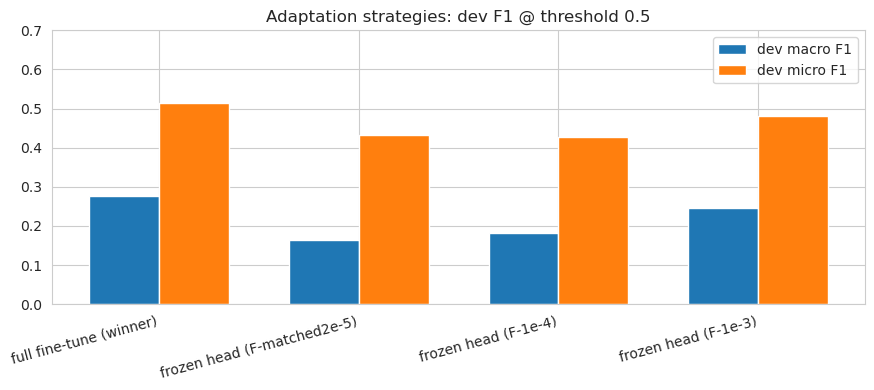

In [34]:
# Comparison table + chart: full fine-tuning (winner) vs frozen backbone (LR bracket)
full_row = {
    "strategy": "full fine-tune (winner)",
    "lr": best_result["lr"],
    "trainable": full_trainable_probe,
    "best_epoch": best_result["best_epoch"],
    "dev_macro_f1": best_metrics["macro_f1"],
    "dev_micro_f1": best_metrics["micro_f1"],
    "dev_weighted_f1": best_metrics["weighted_f1"],
    "step_s": t_full_step,
}
rows = [full_row]
for r in frozen_results:
    rows.append({
        "strategy": f"frozen head ({r['tag']})",
        "lr": r["lr"],
        "trainable": r["trainable"],
        "best_epoch": r["best_epoch"],
        "dev_macro_f1": r["best_macro_f1"],
        "dev_micro_f1": r["best_dev"]["micro_f1"],
        "dev_weighted_f1": r["best_dev"]["weighted_f1"],
        "step_s": t_frozen_step,
    })
cmp_df = pd.DataFrame(rows)
print(cmp_df.to_string(index=False,
                       formatters={"lr": "{:g}".format, "dev_macro_f1": "{:.4f}".format,
                                   "dev_micro_f1": "{:.4f}".format,
                                   "dev_weighted_f1": "{:.4f}".format,
                                   "step_s": "{:.2f}".format}))
best_frozen = max(frozen_results, key=lambda r: r["best_macro_f1"])
delta = full_row["dev_macro_f1"] - best_frozen["best_macro_f1"]
print(f"\nbest frozen: {best_frozen['tag']} (lr={best_frozen['lr']:g}, "
      f"epoch={best_frozen['best_epoch']}, macro={best_frozen['best_macro_f1']:.4f})")
print(f"full fine-tune advantage on dev macro F1: {delta:+.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cmp_df)); w = 0.35
ax.bar(x - w/2, cmp_df["dev_macro_f1"], w, label="dev macro F1", color="tab:blue")
ax.bar(x + w/2, cmp_df["dev_micro_f1"], w, label="dev micro F1", color="tab:orange")
ax.set_xticks(x); ax.set_xticklabels(cmp_df["strategy"], rotation=15, ha="right")
ax.set_ylim(0, 0.7); ax.legend(); ax.set_title("Adaptation strategies: dev F1 @ threshold 0.5")
plt.tight_layout(); plt.show()


#### What the Comparison Shows

- Full fine-tuning remains the stronger adaptation on the metric the model is selected by (dev macro F1): 0.2771 (epoch 11) vs the best frozen variant's 0.2448 (F-1e-3, epoch 10) - a +0.032 margin that supports the pre-stated hypothesis, though narrower than a dominance claim: the domain-specific cues need the encoder itself to move, but a linear read-out of frozen features recovers most of the way (matched-LR frozen 0.1634, F-1e-4 0.1819).
- The frozen head is not useless: at its best LR it reaches 0.2448 macro against the all-zero predictor's 0.0, i.e. the pretrained features already linearly encode a large share of the propaganda signal without the encoder moving at all - it is a genuine second strategy, just a weaker one.
- Cost. Freezing cuts the trainable parameters from 66,968,852 to 605,972 (99.1%) and the measured per-step time from 0.14 s to 0.05 s (2.8x), because the backward pass never enters the encoder. The trade is 0.032 dev macro for that compute and a much smaller checkpoint (head-only).
- Fairness of the bracket. The matched-LR frozen run isolates the effect of freezing under identical optimisation; the 1e-4/1e-3 runs give the random head the larger steps it needs. Because the conclusion holds across the whole bracket (best frozen 0.2448 at lr 1e-3 still below 0.2771), it is a statement about the strategy, not about a single unlucky LR - and the fact that the frozen head needed lr 1e-3 (50x the matched LR) to become competitive is itself the random-head effect the bracket was designed to absorb.


## K-Fold Cross-Validation

- `StratifiedKFold` is used to stratify a single target with 20 labels of very different frequencies. Plain K-fold would routinely leave rare labels with zero validation positives.
- Fixed epoch count = best epoch from tuning (avoids selecting epochs on the fold being reported)
- Thresholds fixed at 0.5 for comparability (per-fold tuning would overfit small fold sets)
- Loss type follows the selected config; for capped BCE, `pos_weight` is recomputed per fold from the fold-training split only (no fold-validation leakage).
- Dev and test sets are not used here; this estimates how stable the config is across data splits.
- 5 splits: ~138-row validation folds keep rare labels represented (~12 positives per label on average) while leaving ~550 rows for training. 10 folds would halve the training data and double runtime for little variance reduction.
- Iterative stratification is what keeps rare labels rare-but-present in every fold; random splitting would give some folds zero positives for the 1-2-shot labels, making fold macro F1 partly an artefact of the split.
- Epochs, thresholds, hyperparameters are not chosen on fold results. The config was already selected on dev. CV here estimates stability of that fixed config; selecting on it would double-dip.


In [35]:
KFOLD_SPLITS = 5
KFOLD_EPOCHS = max(int(best_result["best_epoch"]), 1)
KFOLD_LR = best_result["lr"]
KFOLD_DROPOUT = best_result["dropout"]
KFOLD_LOSS = best_result.get("loss", "bce")

skf = MultilabelStratifiedKFold(n_splits=KFOLD_SPLITS, shuffle=True, random_state=SEED)
folds = list(skf.split(np.zeros(len(train_labels)), train_labels))

print(f"Config: lr={KFOLD_LR}, dropout={KFOLD_DROPOUT}, loss={KFOLD_LOSS}, "
      f"epochs={KFOLD_EPOCHS}, splits={KFOLD_SPLITS}")
for k, (tr_idx, va_idx) in enumerate(folds):
    print(f"Fold {k}: train={len(tr_idx)}, val={len(va_idx)}, "
          f"val positives/label={train_labels[va_idx].sum(axis=0).mean():.1f}")


Config: lr=2e-05, dropout=0.2, loss=asl, epochs=11, splits=5
Fold 0: train=550, val=138, val positives/label=11.9
Fold 1: train=550, val=138, val positives/label=11.7
Fold 2: train=550, val=138, val positives/label=11.9
Fold 3: train=551, val=137, val positives/label=11.8
Fold 4: train=551, val=137, val positives/label=11.9



=== Fold 1/5 ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


fold 0 | epoch 1/11:   0%|          | 0/35 [00:00<?, ?it/s]

  epoch 1: train_loss=0.0501


...

  epoch 9: train_loss=0.0274


fold 4 | epoch 10/11:   0%|          | 0/35 [00:00<?, ?it/s]

  epoch 10: train_loss=0.0267


fold 4 | epoch 11/11:   0%|          | 0/35 [00:00<?, ?it/s]

  epoch 11: train_loss=0.0260
  micro_f1=0.4552 macro_f1=0.2235 weighted_f1=0.4802 sample_f1=0.4118 hamming_loss=0.1730 subset_accuracy=0.0438

=== K-Fold CV Summary (mean +/- std) ===
         metric   mean    std
       micro_f1 0.4611 0.0163
       macro_f1 0.2319 0.0371
    weighted_f1 0.4885 0.0237
      sample_f1 0.4136 0.0122
   hamming_loss 0.1592 0.0093
subset_accuracy 0.0552 0.0232


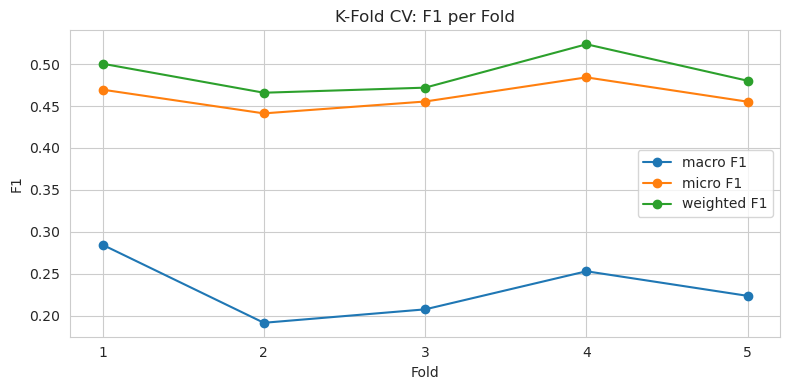

In [36]:
kfold_results = []

for k, (tr_idx, va_idx) in enumerate(folds):
    print(f"\n=== Fold {k + 1}/{KFOLD_SPLITS} ===")
    fold_train_loader = DataLoader(
        PropagandaDataset(
            {"input_ids": train_encodings["input_ids"][tr_idx.tolist()],
             "attention_mask": train_encodings["attention_mask"][tr_idx.tolist()]},
            train_labels[tr_idx]),
        batch_size=BATCH_SIZE, shuffle=True)
    fold_val_loader = DataLoader(
        PropagandaDataset(
            {"input_ids": train_encodings["input_ids"][va_idx.tolist()],
             "attention_mask": train_encodings["attention_mask"][va_idx.tolist()]},
            train_labels[va_idx]),
        batch_size=BATCH_SIZE, shuffle=False)

    # Loss mirrors the selected config; for capped BCE the weights are estimated
    # from the fold-training split only (no fold-val label leakage)
    fold_criterion = build_criterion(KFOLD_LOSS, train_labels[tr_idx])

    fold_model = DistilBertForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=num_labels,
        problem_type="multi_label_classification", dropout=KFOLD_DROPOUT).to(device)
    opt = torch.optim.AdamW(fold_model.parameters(), lr=KFOLD_LR, weight_decay=WEIGHT_DECAY)
    total_steps = len(fold_train_loader) * KFOLD_EPOCHS
    sched = get_linear_schedule_with_warmup(
        opt, num_warmup_steps=int(total_steps * WARMUP_RATIO), num_training_steps=total_steps)

    for epoch in range(1, KFOLD_EPOCHS + 1):
        fold_model.train()
        running = 0.0
        for batch in tqdm(fold_train_loader, desc=f"fold {k} | epoch {epoch}/{KFOLD_EPOCHS}", leave=False):
            opt.zero_grad()
            outputs = fold_model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device))
            loss = fold_criterion(outputs.logits, batch["labels"].to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(fold_model.parameters(), GRAD_CLIP)
            opt.step()
            sched.step()
            running += loss.item()
        print(f"  epoch {epoch}: train_loss={running / len(fold_train_loader):.4f}")

    fold_metrics, _, _, _ = evaluate(fold_model, fold_val_loader)
    kfold_results.append(fold_metrics)
    print("  " + " ".join(f"{mk}={mv:.4f}" for mk, mv in fold_metrics.items()))

    del fold_model, opt, sched
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

kf_df = pd.DataFrame(kfold_results)
kf_summary = pd.DataFrame({
    "metric": kf_df.columns,
    "mean": kf_df.mean().values,
    "std": kf_df.std().values,
})
print("\n=== K-Fold CV Summary (mean +/- std) ===")
print(kf_summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(range(1, KFOLD_SPLITS + 1), kf_df["macro_f1"], marker="o", label="macro F1")
ax.errorbar(range(1, KFOLD_SPLITS + 1), kf_df["micro_f1"], marker="o", label="micro F1")
ax.errorbar(range(1, KFOLD_SPLITS + 1), kf_df["weighted_f1"], marker="o", label="weighted F1")
ax.set_xlabel("Fold")
ax.set_ylabel("F1")
ax.set_title("K-Fold CV: F1 per Fold")
ax.set_xticks(range(1, KFOLD_SPLITS + 1))
ax.legend()
plt.tight_layout()
plt.show()


## Per-Label Threshold Tuning

- Sweep sigmoid thresholds (0.10-0.95) on the dev set to maximise per-label F1.

- Minimum-support guard: a threshold is only retuned for labels with at least
`MIN_DEV_SUPPORT` (= 5) positive dev examples; labels with fewer positives keep the
default 0.5. Fitting a threshold to 1-2 examples is noise-fitting on a 63-sample dev
set. The guard uses dev information only; no test data enters this decision.

- Why per-label thresholds are worth the extra step: under 358:1 imbalance the sigmoid outputs are calibrated only in aggregate. Rare labels systematically sit on one side of 0.5, so a single global threshold leaves per-label F1 on the table. Implementation notes:
- Grid search, not an optimiser: F1 is piecewise-constant in the threshold, so an 18-point sweep (0.10-0.95, step 0.05) is exhaustive at this resolution and fits nothing parametrically to 63 dev samples.
- Grid values are rounded to 2 decimals: raw `np.arange` yields ~0.5, which would count labels whose optimum is exactly 0.5 as tuned (`isclose` guards the same case).
- Thresholds are fitted to the tuning winner's dev probabilities, before the train+dev retrain. After retraining they are carried over as an approximation (documented in the retrain section), never re-tuned (dev is training data by then).


In [37]:
def compute_metrics(labels, preds):
    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
        "sample_f1": sample_f1(labels, preds),
        "hamming_loss": hamming_loss(labels, preds),
        "subset_accuracy": float((preds == labels).all(axis=1).mean()),
    }

THRESHOLD_GRID = np.round(np.arange(0.10, 0.951, 0.05), 2)  # round: raw arange gives ~0.5
MIN_DEV_SUPPORT = 5  # tune only labels with >= 5 dev positives; others keep 0.5
optimal_thresholds = np.full(num_labels, 0.5, dtype=float)
tuned_mask = np.zeros(num_labels, dtype=bool)

dev_support = best_labels.sum(axis=0)
for j in range(num_labels):
    if dev_support[j] < MIN_DEV_SUPPORT:
        continue  # insufficient dev support: keep default 0.5
    y_true_j = best_labels[:, j]
    best_f1, best_t = -1.0, 0.5
    for t in THRESHOLD_GRID:
        f1_j = f1_score(y_true_j, (best_probs[:, j] >= t).astype(int), zero_division=0)
        if f1_j > best_f1:
            best_f1, best_t = f1_j, t
    optimal_thresholds[j] = best_t
    tuned_mask[j] = not np.isclose(best_t, 0.5)  # isclose: grid float error must not count as tuned

dev_preds_05 = (best_probs >= 0.5).astype(int)
dev_preds_tuned = (best_probs >= optimal_thresholds).astype(int)
dev_metrics_05 = compute_metrics(best_labels, dev_preds_05)
dev_metrics_tuned = compute_metrics(best_labels, dev_preds_tuned)

print("Dev set metrics:")
print(f"{'Metric':<20} {'thr=0.5':>10} {'tuned':>10} {'delta':>10}")
print("-" * 54)
for k in dev_metrics_05:
    d = dev_metrics_tuned[k] - dev_metrics_05[k]
    print(f"{k:<20} {dev_metrics_05[k]:>10.4f} {dev_metrics_tuned[k]:>10.4f} {d:>+10.4f}")

n_eligible = int((dev_support >= MIN_DEV_SUPPORT).sum())
n_tuned = int(tuned_mask.sum())
n_low = int(((dev_support > 0) & (dev_support < MIN_DEV_SUPPORT)).sum())
n_absent = int((dev_support == 0).sum())
print(f"\n{n_eligible} label(s) eligible for tuning (dev support >= {MIN_DEV_SUPPORT}); "
      f"{n_tuned} received a non-0.5 threshold")
print(f"{n_low} label(s) kept 0.5 (support 1-{MIN_DEV_SUPPORT - 1}), "
      f"{n_absent} kept 0.5 (zero dev support)")


Dev set metrics:
Metric                  thr=0.5      tuned      delta
------------------------------------------------------
micro_f1                 0.5141     0.5115    -0.0026
macro_f1                 0.2771     0.2933    +0.0163
weighted_f1              0.5476     0.5954    +0.0478
sample_f1                0.5058     0.4389    -0.0669
hamming_loss             0.1365     0.1349    -0.0016
subset_accuracy          0.1270     0.0794    -0.0476

6 label(s) eligible for tuning (dev support >= 5); 5 received a non-0.5 threshold
11 label(s) kept 0.5 (support 1-4), 3 kept 0.5 (zero dev support)


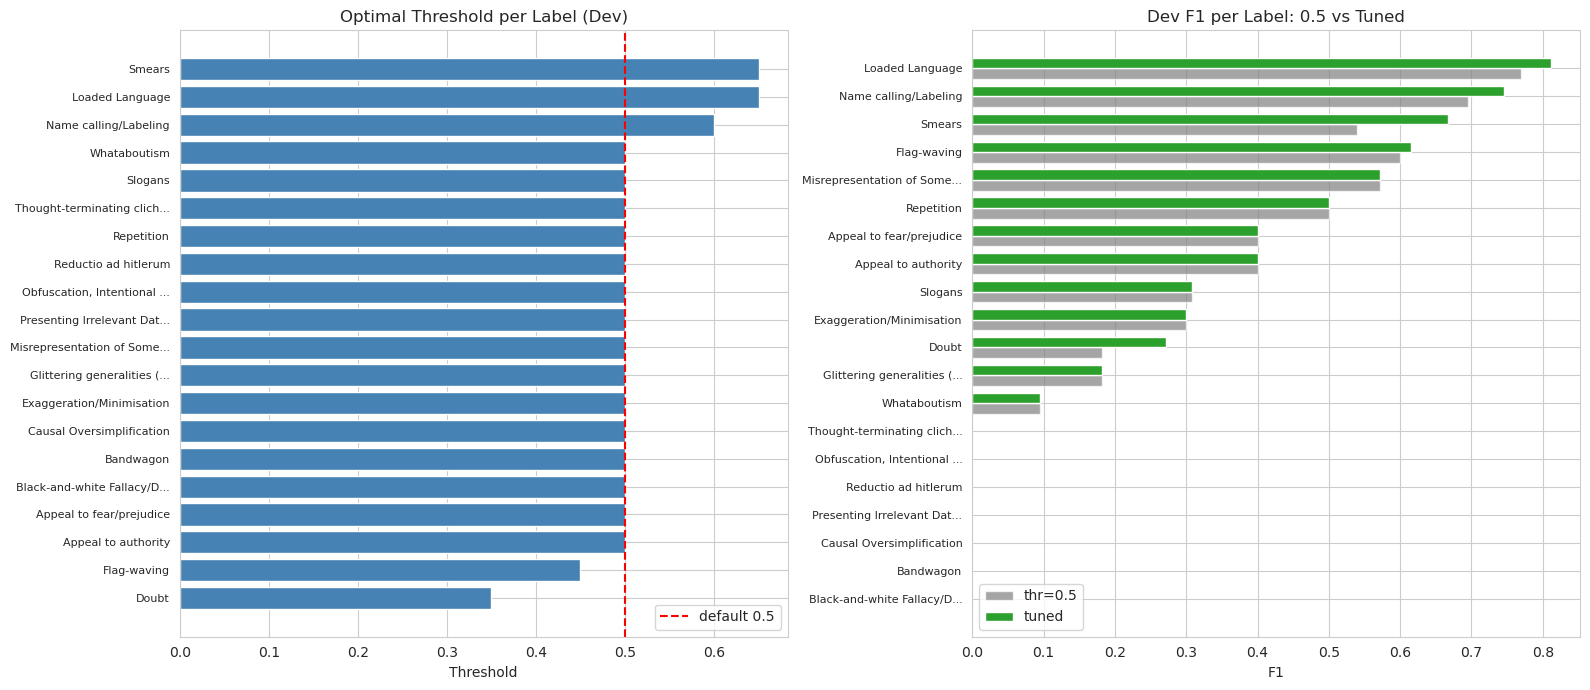

In [38]:
short_labels = [l[:25] + "..." if len(l) > 25 else l for l in all_labels]
per_label_f1_05 = np.array([
    f1_score(best_labels[:, j], dev_preds_05[:, j], zero_division=0)
    for j in range(num_labels)
])
per_label_f1_tuned = np.array([
    f1_score(best_labels[:, j], dev_preds_tuned[:, j], zero_division=0)
    for j in range(num_labels)
])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: optimal thresholds
order = np.argsort(optimal_thresholds)
axes[0].barh(range(num_labels), optimal_thresholds[order], color="steelblue")
axes[0].axvline(0.5, color="red", linestyle="--", label="default 0.5")
axes[0].set_yticks(range(num_labels))
axes[0].set_yticklabels([short_labels[i] for i in order], fontsize=8)
axes[0].set_xlabel("Threshold")
axes[0].set_title("Optimal Threshold per Label (Dev)")
axes[0].legend()

# Right: per-label F1 comparison
order2 = np.argsort(per_label_f1_tuned)
h = 0.38
axes[1].barh(np.arange(num_labels) - h / 2, per_label_f1_05[order2],
             height=h, color="tab:gray", alpha=0.7, label="thr=0.5")
axes[1].barh(np.arange(num_labels) + h / 2, per_label_f1_tuned[order2],
             height=h, color="tab:green", label="tuned")
axes[1].set_yticks(range(num_labels))
axes[1].set_yticklabels([short_labels[i] for i in order2], fontsize=8)
axes[1].set_xlabel("F1")
axes[1].set_title("Dev F1 per Label: 0.5 vs Tuned")
axes[1].legend()

plt.tight_layout()
plt.show()

### Final Model: Retrain on Train + Dev

- Retrain the best configuration on all labelled data (train + dev, 751 samples)
with a fixed epoch count from tuning (no held-out data for early stopping).
- The loss mirrors the selected config; for capped BCE the weights are re-estimated
  on the combined train+dev labels (they are all training data now).
- The thresholds below were tuned on dev before this retrain and carry over;
  re-tuning them now would leak, since dev is part of training.
- Limitation: those thresholds were fitted to the pre-retrain model's dev
  probabilities; calibration shifts after retraining, so they are approximate for
  the final model.
- The test set remains untouched until the next section.


In [39]:
# Combine train + dev encodings and labels
final_encodings = {
    "input_ids": torch.cat([train_encodings["input_ids"], dev_encodings["input_ids"]]),
    "attention_mask": torch.cat([train_encodings["attention_mask"], dev_encodings["attention_mask"]]),
}
final_labels = np.vstack([train_labels, dev_labels])
FINAL_EPOCHS = max(int(best_result["best_epoch"]), 1)

# Loss mirrors the selected config; for capped BCE the weights are estimated on
# the combined train+dev labels (all training data for the final model)
final_criterion = build_criterion(best_result.get("loss", "bce"), final_labels)

final_loader = DataLoader(
    PropagandaDataset(final_encodings, final_labels),
    batch_size=BATCH_SIZE, shuffle=True)

final_model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification",
    dropout=best_result["dropout"],
).to(device)

final_opt = torch.optim.AdamW(
    final_model.parameters(), lr=best_result["lr"], weight_decay=WEIGHT_DECAY)
final_steps = len(final_loader) * FINAL_EPOCHS
final_sched = get_linear_schedule_with_warmup(
    final_opt,
    num_warmup_steps=int(final_steps * WARMUP_RATIO),
    num_training_steps=final_steps,
)

for epoch in range(1, FINAL_EPOCHS + 1):
    final_model.train()
    running = 0.0
    for batch in tqdm(final_loader, desc=f"final | epoch {epoch}/{FINAL_EPOCHS}", leave=False):
        final_opt.zero_grad()
        outputs = final_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device))
        loss = final_criterion(outputs.logits, batch["labels"].to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), GRAD_CLIP)
        final_opt.step()
        final_sched.step()
        running += loss.item()
    print(f"epoch {epoch}/{FINAL_EPOCHS}: train_loss={running / len(final_loader):.4f}")

# Persist and swap: downstream cells (test eval, PR curves, error analysis)
# now use the retrained model
torch.save(final_model.state_dict(), "final_model.pt")
model = final_model
print(f"\nFinal model trained on train+dev ({len(final_labels)} samples, "
      f"{FINAL_EPOCHS} epoch(s)) and saved to final_model.pt")
print(f"Hyperparameters: lr={best_result['lr']}, dropout={best_result['dropout']}, "
      f"loss={best_result.get('loss', 'bce')} ({type(final_criterion).__name__})")
print("Dev-tuned thresholds carry over to the test evaluation below.")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


final | epoch 1/11:   0%|          | 0/47 [00:00<?, ?it/s]

epoch 1/11: train_loss=0.0498


final | epoch 2/11:   0%|          | 0/47 [00:00<?, ?it/s]

...

epoch 9/11: train_loss=0.0244


final | epoch 10/11:   0%|          | 0/47 [00:00<?, ?it/s]

epoch 10/11: train_loss=0.0234


final | epoch 11/11:   0%|          | 0/47 [00:00<?, ?it/s]

epoch 11/11: train_loss=0.0229

Final model trained on train+dev (751 samples, 11 epoch(s)) and saved to final_model.pt
Hyperparameters: lr=2e-05, dropout=0.2, loss=asl (AsymmetricLoss)
Dev-tuned thresholds carry over to the test evaluation below.


## Evaluation Protocol

1. Primary decision rule: per-label thresholds tuned on dev only, subject to
   the minimum-support guard (`MIN_DEV_SUPPORT = 5`); labels below the guard keep
   0.5. The guard is justified by dev support counts alone.
2. Comparison rule: fixed 0.5 threshold (the parameter-free default of sigmoid +
   BCE). Both columns are reported side by side.
3. Model selection: hyperparameters and epoch count selected on dev macro F1 at
   threshold 0.5; final model retrained on train+dev with the frozen configuration.
   (Selection at 0.5, reporting at both rules.)
4. Test usage: metrics, PR curves and error analysis are computed once from the
   final model. Nothing learned from test outputs will feed back into model changes;
   any future changes would be validated on dev/OOF only.
5. Contamination: the integrity check found an exact train-test duplicate; a
   sensitivity analysis excluding it follows the metrics table.


Next steps for the future, for improving the model could include data augmentation. An LLM/API could be used to generate synthetic text, however this has its own limitations such as it is not reproducable.

## Final Evaluation on Test Set

- One-time evaluation of the final (train+dev retrained) model. Thresholds were tuned
on dev only. Test labels were not used for any tuning.

- `sample_f1` scores an all-empty prediction on an all-empty sample as 1.0, so an
  all-zero predictor scores 0.205 on this test set (41/200 unlabelled samples); treat that as the null baseline for sample F1.
- Macro F1 (the main metric here) is well-defined here: every test label has at least one positive test
  example (verified by the data audit), so no label is silently forced to 0.


In [ ]:
# Test-set predictions with the best model
_, test_probs, test_labels_arr, _ = evaluate(model, test_loader)
test_preds_05 = (test_probs >= 0.5).astype(int)
test_preds_tuned = (test_probs >= optimal_thresholds).astype(int)

test_metrics_05 = compute_metrics(test_labels_arr, test_preds_05)
test_metrics_tuned = compute_metrics(test_labels_arr, test_preds_tuned)

print("TEST SET METRICS:")
print(f"{'Metric':<20} {'thr=0.5':>10} {'tuned':>10} {'delta':>10}")
print("-" * 54)
for k in test_metrics_05:
    d = test_metrics_tuned[k] - test_metrics_05[k]
    print(f"{k:<20} {test_metrics_05[k]:>10.4f} {test_metrics_tuned[k]:>10.4f} {d:>+10.4f}")

TEST SET METRICS:
Metric                  thr=0.5      tuned      delta
------------------------------------------------------
micro_f1                 0.4265     0.4176    -0.0089
macro_f1                 0.2004     0.2107    +0.0103
weighted_f1              0.4553     0.4951    +0.0398
sample_f1                0.4026     0.3449    -0.0577
hamming_loss             0.1648     0.1590    -0.0058
subset_accuracy          0.0650     0.0500    -0.0150


### Sensitivity to Train-Test Contamination

- From the integrity check: found `474_batch_2` duplicated in train and test (with conflicting labels). This cell re-computes every headline metric with the contaminated sample(s) removed. If the columns match, the duplicate does not drive the conclusions; reporting both keeps the contamination finding honest instead of quietly deleting the sample or silently ignoring it.


In [41]:
# Sensitivity: metrics excluding exact train-test duplicates (from the integrity check)
if test_contaminated_ids:
    keep_mask = np.array([s["id"] not in set(test_contaminated_ids) for s in test_data])
    n_excl = int((~keep_mask).sum())
    sens_05 = compute_metrics(test_labels_arr[keep_mask], test_preds_05[keep_mask])
    sens_tuned = compute_metrics(test_labels_arr[keep_mask], test_preds_tuned[keep_mask])

    print(f"Excluding {n_excl} test sample(s) duplicated in train: {test_contaminated_ids}")
    print(f"{'Metric':<20} {'@0.5 full':>11} {'@0.5 excl':>11} "
          f"{'tuned full':>12} {'tuned excl':>12}")
    print("-" * 70)
    for k in test_metrics_tuned:
        print(f"{k:<20} {test_metrics_05[k]:>11.4f} {sens_05[k]:>11.4f} "
              f"{test_metrics_tuned[k]:>12.4f} {sens_tuned[k]:>12.4f}")
    print("\nIf columns are near-identical, the duplicate does not change conclusions.")
else:
    print("No train-test duplicates found - sensitivity analysis not needed.")


Excluding 1 test sample(s) duplicated in train: ['474_batch_2']
Metric                 @0.5 full   @0.5 excl   tuned full   tuned excl
----------------------------------------------------------------------
micro_f1                  0.4265      0.4268       0.4176       0.4183
macro_f1                  0.2004      0.2007       0.2107       0.2110
weighted_f1               0.4553      0.4560       0.4951       0.4960
sample_f1                 0.4026      0.4046       0.3449       0.3466
hamming_loss              0.1648      0.1653       0.1590       0.1593
subset_accuracy           0.0650      0.0653       0.0500       0.0503

If columns are near-identical, the duplicate does not change conclusions.


In [42]:
p_t, r_t, f1_t, sup = precision_recall_fscore_support(
    test_labels_arr, test_preds_tuned, average=None, zero_division=0
)
_, _, f1_b, _ = precision_recall_fscore_support(
    test_labels_arr, test_preds_05, average=None, zero_division=0
)

report_df = pd.DataFrame({
    "label": all_labels,
    "support": sup.astype(int),
    "precision": p_t,
    "recall": r_t,
    "f1@0.5": f1_b,
    "f1@tuned": f1_t,
    "threshold": optimal_thresholds,
}).sort_values("support", ascending=False)

print("Per-label results on test set:")
print(report_df.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Per-label results on test set:
                                              label  support  precision  recall  f1@0.5  f1@tuned  threshold
                                    Loaded Language      100      0.771   0.840   0.746     0.804      0.650
                              Name calling/Labeling       53      0.506   0.774   0.495     0.612      0.600
                                             Smears       45      0.435   0.600   0.426     0.505      0.650
                                              Doubt       28      0.154   0.964   0.352     0.266      0.350
                                            Slogans       19      0.233   0.526   0.323     0.323      0.500
                          Exaggeration/Minimisation       19      0.167   0.579   0.259     0.259      0.500
                   Glittering generalities (Virtue)       11      0.125   0.273   0.171     0.171      0.500
                           Appeal to fear/prejudice       10      0.118   0.600   0.197     0.197

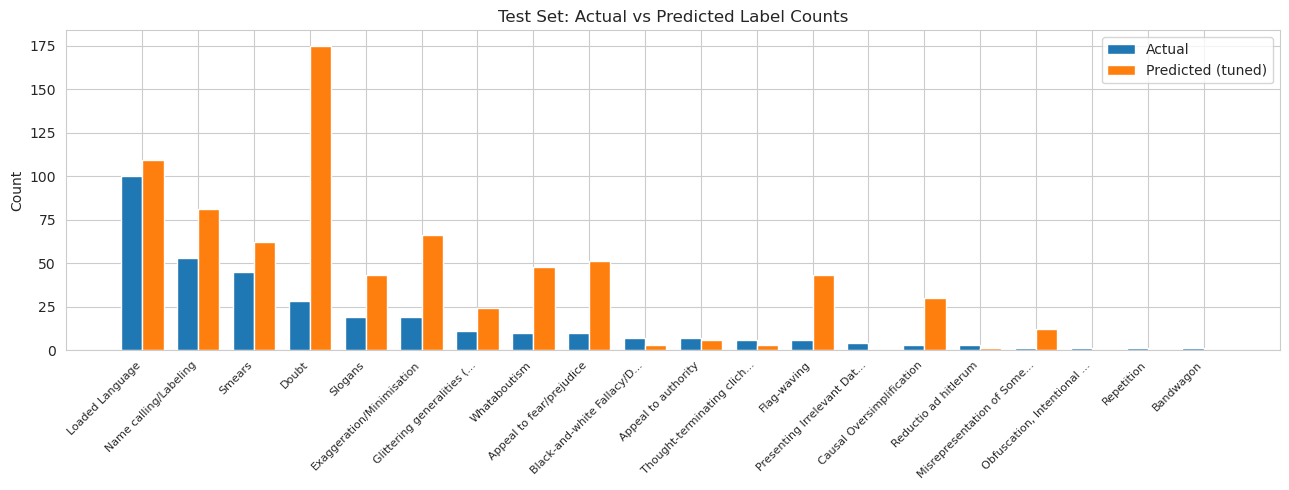

In [43]:
actual_counts = test_labels_arr.sum(axis=0)
pred_counts = test_preds_tuned.sum(axis=0)

order = np.argsort(actual_counts)[::-1]
x = np.arange(num_labels)
w = 0.38

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - w / 2, actual_counts[order], w, label="Actual", color="tab:blue")
ax.bar(x + w / 2, pred_counts[order], w, label="Predicted (tuned)", color="tab:orange")
ax.set_xticks(x)
ax.set_xticklabels([short_labels[i] for i in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Count")
ax.set_title("Test Set: Actual vs Predicted Label Counts")
ax.legend()
plt.tight_layout()
plt.show()

### Per-Label Precision-Recall Curves

- Why PR curves rather than ROC: with most labels at 1-5% prevalence, ROC's false-positive rate is divided by a huge pool of true negatives and looks far too flattering; precision vs recall shows the trade-off the model actually faces.
- the dotted line is prevalence (precision of a random classifier). The no-skill baseline for that label; AP summarises the curve above it;
- the red dot marks the operating point of the pre-registered decision rule (tuned threshold).
- these curves are diagnostic only. So no threshold or model choice is made from test-set curves.


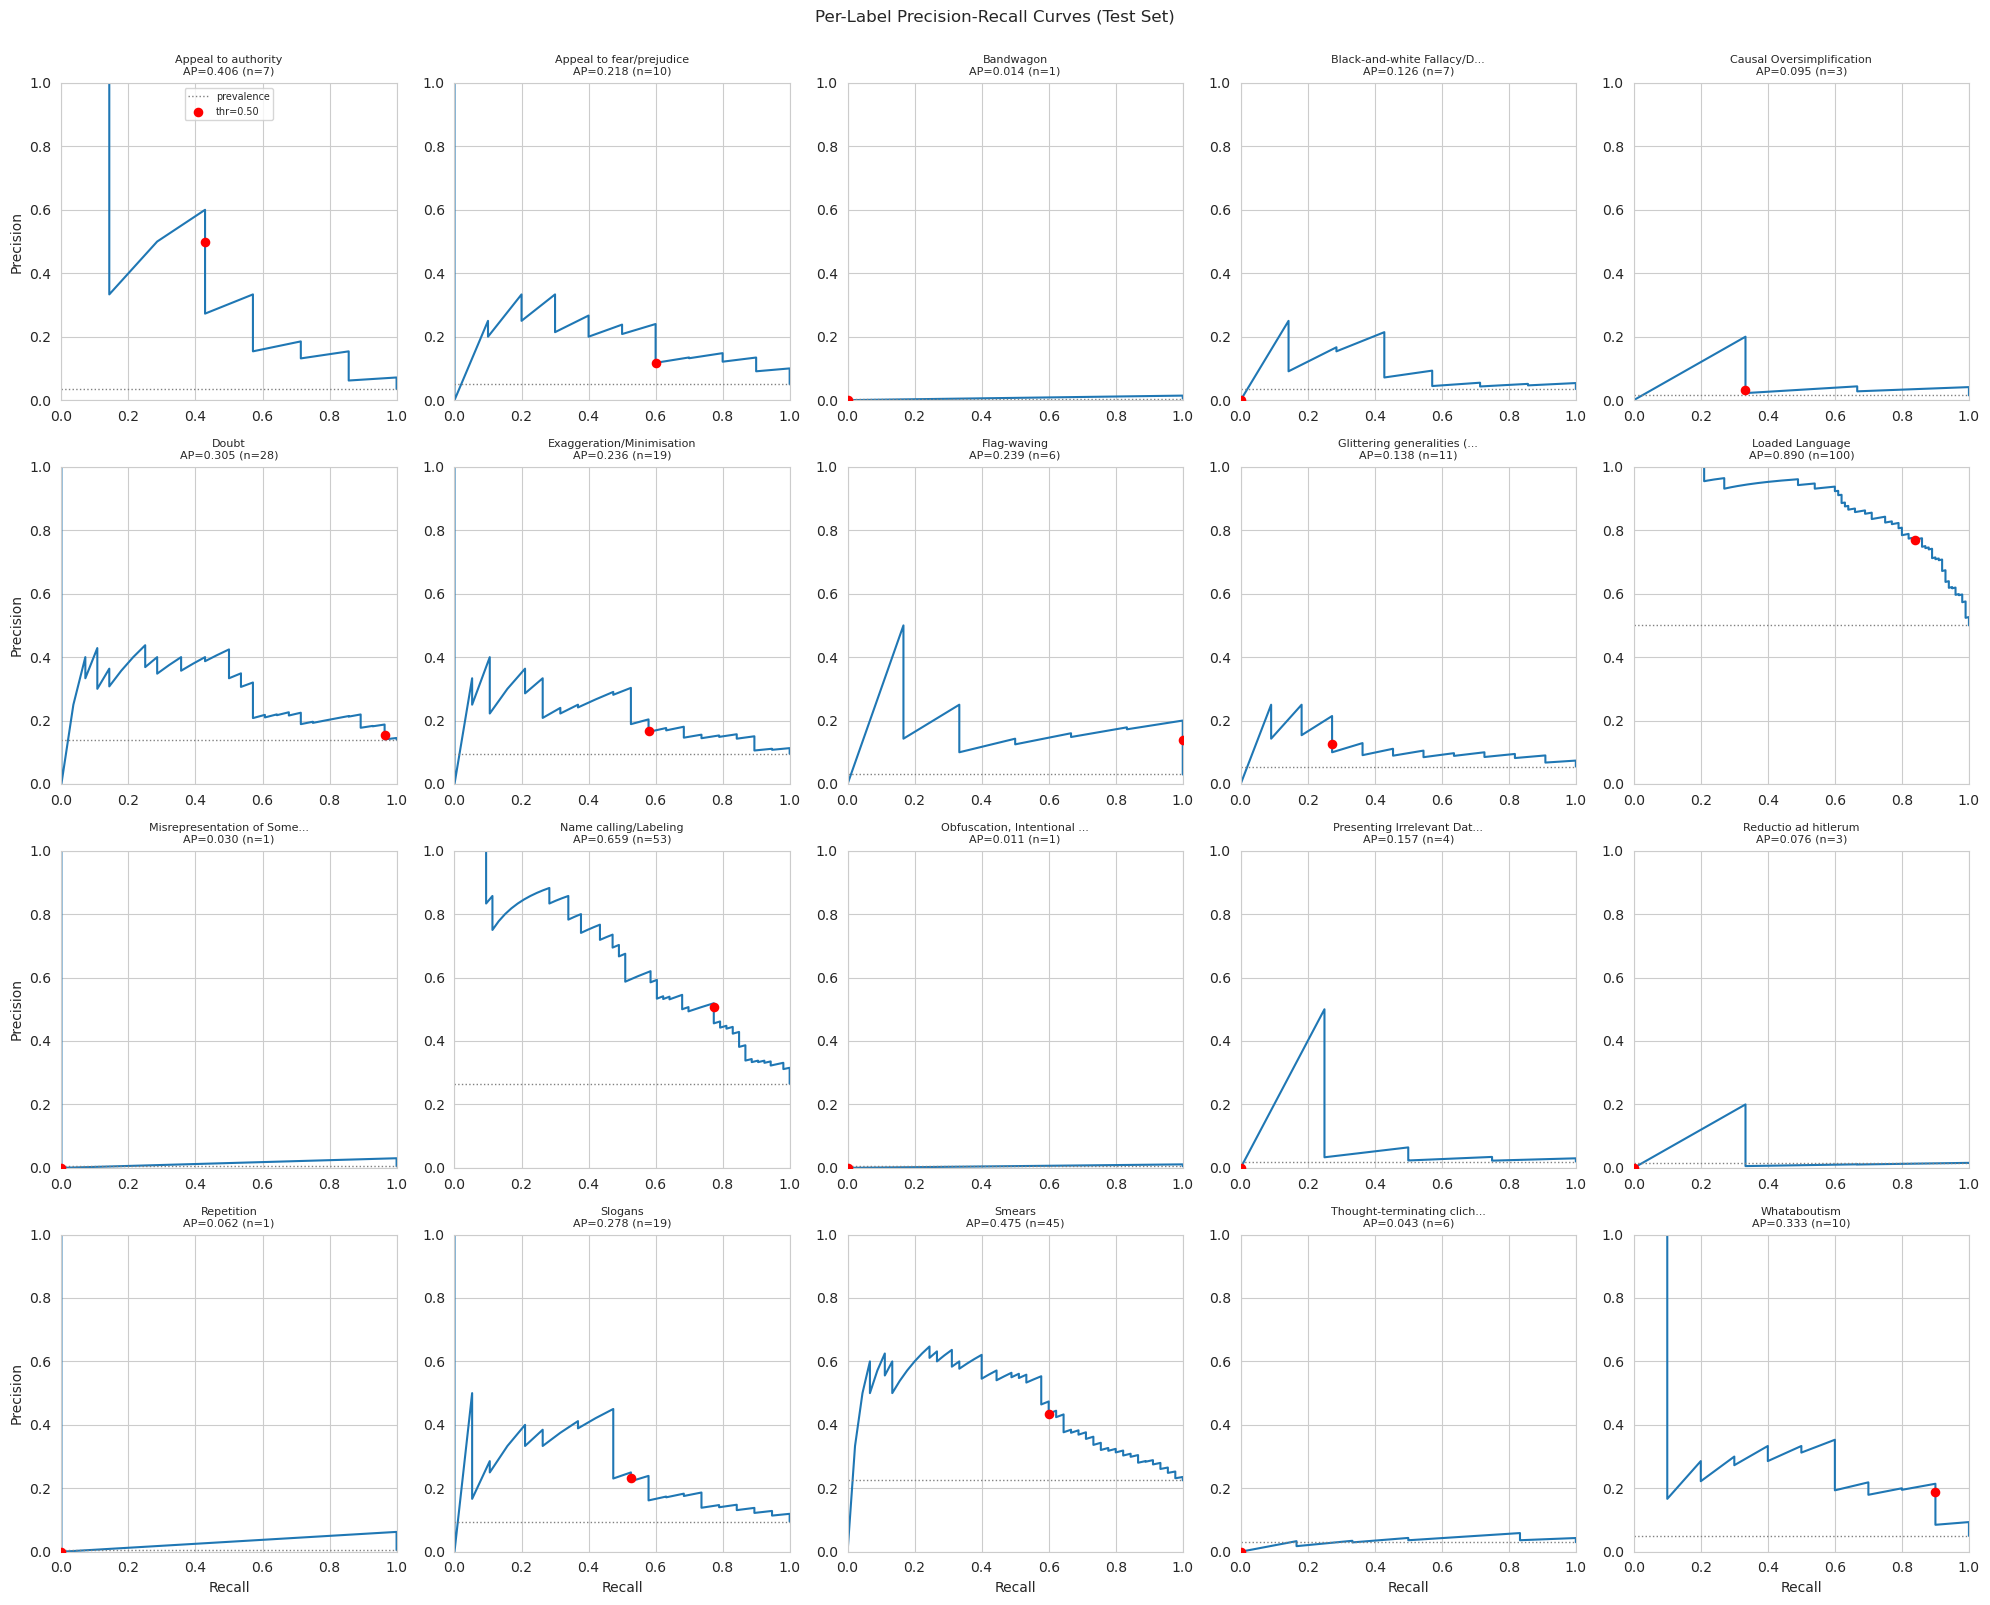

In [44]:
fig, axes = plt.subplots(4, 5, figsize=(20, 16))
for j in range(num_labels):
    ax = axes[j // 5][j % 5]
    y = test_labels_arr[:, j]
    p_curve, r_curve, _ = precision_recall_curve(y, test_probs[:, j])
    ap = average_precision_score(y, test_probs[:, j])
    ax.plot(r_curve, p_curve, color="tab:blue", lw=1.5)
    ax.axhline(y.mean(), color="gray", ls=":", lw=1, label="prevalence")

    # Operating point at the tuned threshold
    pj = test_preds_tuned[:, j]
    tp = int(((pj == 1) & (y == 1)).sum())
    fp = int(((pj == 1) & (y == 0)).sum())
    fn = int(((pj == 0) & (y == 1)).sum())
    prec_t = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec_t = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    ax.scatter([rec_t], [prec_t], color="red", s=35, zorder=5,
               label=f"thr={optimal_thresholds[j]:.2f}")

    ax.set_title(f"{short_labels[j]}\nAP={ap:.3f} (n={int(y.sum())})", fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    if j % 5 == 0:
        ax.set_ylabel("Precision")
    if j >= 15:
        ax.set_xlabel("Recall")
    if j == 0:
        ax.legend(fontsize=7, loc="upper center")

for ax in axes.flat[len(all_labels):]:
    ax.axis("off")
plt.suptitle("Per-Label Precision-Recall Curves (Test Set)", y=1.0)
plt.tight_layout()
plt.show()

### Reading the PR Grid

- Curve: precision as the threshold sweeps from high (top-left) to low. Every curve must end at recall 1.0 where precision equals prevalence - the dotted no-skill line is not a target to beat everywhere, it is each curve's forced endpoint.
- AP (panel title): threshold-free ranking quality. Judge it against that panel's own prevalence line, not on a common scale across panels (AP 0.15 on a 0.03-prevalence label is far from no-skill; AP 0.55 on a 0.50 line barely clears it).
- Red dot: the pre-registered tuned operating point, exactly the precision/recall columns of the per-label table below, plotted on the curve.
- The gap between curve and line broadly tracks training support from the label-frequency EDA: Loaded Language's dot sits at recall 0.84 / precision 0.77 against a 0.50 line (train n=358), Name calling 0.77/0.51 vs 0.27 (n=218), Smears 0.60/0.44 vs 0.23 (n=200). This is genuine ranking signal where data is abundant.
- Counter-example worth noting: Appeal to authority (n=13) still puts its dot at precision 0.50 against a 0.035 line, rarity alone does not flatten a curve. A rare but lexically distinctive technique (see top-terms EDA) can be ranked well; what kills a curve is rarity plus an unremarkable surface form (Red Herring n=1, Bandwagon n=2, Obfuscation n=4. Expect those three panels to hug their lines, AP ~= prevalence: the "nothing to generalise from" conclusion made visible).


### What the Curves Indicate

- The model ranks prototypical cases well, then pays for recall. Every label where the model fires at all has precision at or above its prevalence line, never worse than random - with large lifts where the technique has distinctive wording (Appeal to authority 0.50 vs 0.035; Whataboutism 0.90 recall at 0.19 precision vs a 0.05 line). Precision falls as recall is pushed upward: that decay is the signature of inter-label confusion between techniques whose vocabulary overlaps (the co-occurrence EDA), not of a model that learned nothing.
- The operating point matters as much as the curve. Doubt is the clearest case: the tuned rule reaches recall 0.964 only by flagging 175 of 200 documents, giving precision 0.154 - essentially its 0.140 prevalence. Yet f1@0.5 = 0.352 beats f1@tuned = 0.266, so the underlying ranking is usable: this is a threshold-selection artefact from small dev support, not a curve failure. Flag-waving shows the milder version (lift exists - 0.14 vs a 0.03 line - but the dot bought too much recall).
- Eight labels have their dots at the origin (recall 0 at the tuned threshold: Black-and-white, Thought-terminating clich, Red Herring, Reductio, Bandwagon, Straw Man, Repetition, Obfuscation). The curve still separates two stories: AP near the prevalence line means the scores carry no ranking information; AP clearly above it means ranking is fine but the dev-tuned threshold rejected everything (calibration - fixable on dev). Either way, f1 = 0 at this operating point.
- Small-support panels are noise-dominated: with 1-4 test positives, one document redraws a whole curve. Read those panels as anecdotal - the same caveat as the +/-0.04 macro-F1 sampling band (5-fold CV).


## Error Analysis

1. Sample level: are errors concentrated in a few pathological documents or spread thin? Over vs under-prediction counts also expose the model's operating bias (recall-heavy vs precision-heavy).
2. Per label FP/FN: which techniques generate the error mass, and does each error toward false alarms or misses?
3. Concrete examples: the worst label's FP/FN texts with their probabilities: lexical confusions (similar surface cues) vs genuinely ambiguous annotations?
4. Length: the EDA-formed hypothesis, tested in the last cell: if errors grow with length, the problem is information spread over long inputs, not label confusion.


In [45]:
# Sample-level statistics (test set, tuned thresholds)
exact_match = (test_preds_tuned == test_labels_arr).all(axis=1)
sample_errors = (test_preds_tuned != test_labels_arr).sum(axis=1)
n_actual = test_labels_arr.sum(axis=1)
n_pred = test_preds_tuned.sum(axis=1)

print(f"Exact match (all 20 labels correct): "
      f"{exact_match.sum()}/{len(exact_match)} ({100*exact_match.mean():.1f}%)")
print(f"Avg labels per sample - actual: {n_actual.mean():.2f}, "
      f"predicted: {n_pred.mean():.2f}")
print(f"Over-predicted: {(n_pred > n_actual).sum()} samples, "
      f"under-predicted: {(n_pred < n_actual).sum()}, "
      f"equal: {(n_pred == n_actual).sum()}")
print(f"Avg wrong labels per sample: {sample_errors.mean():.2f}")

worst_idx = np.argsort(sample_errors)[::-1][:8]
print("\nWorst test samples:")
for i in worst_idx:
    actual = [idx2label[j] for j in np.where(test_labels_arr[i] == 1)[0]]
    pred = [idx2label[j] for j in np.where(test_preds_tuned[i] == 1)[0]]
    print(f"\n--- test[{i}] | {sample_errors[i]}/20 labels wrong ---")
    print(f"Text: {test_texts[i][:200]}")
    print(f"Actual:    {actual if actual else '(none)'}")
    print(f"Predicted: {pred if pred else '(none)'}")

Exact match (all 20 labels correct): 10/200 (5.0%)
Avg labels per sample - actual: 1.67, predicted: 3.79
Over-predicted: 150 samples, under-predicted: 18, equal: 32
Avg wrong labels per sample: 3.18

Worst test samples:

--- test[148] | 9/20 labels wrong ---
Text: LIBERALS WOULD RATHER DIE THAN TRY HYDROXYCHLOROQUINE?
LET THEM. 
IT'S CALLED NATURAL SELECTION
Actual:    ["Misrepresentation of Someone's Position (Straw Man)", 'Smears', 'Thought-terminating cliché']
Predicted: ['Appeal to fear/prejudice', 'Causal Oversimplification', 'Doubt', 'Loaded Language', 'Name calling/Labeling', 'Whataboutism']

--- test[135] | 9/20 labels wrong ---
Text: IF A FELON HAS TO PAY OFF THEIR DEBTS TO VOTE IN FLORIDA A POLITICIAN SHOULD PAY OFF THEIR DEBTS TO RUN FOR PRESIDENT
Actual:    ['Whataboutism']
Predicted: ['Appeal to fear/prejudice', 'Black-and-white Fallacy/Dictatorship', 'Doubt', 'Exaggeration/Minimisation', 'Flag-waving', 'Glittering generalities (Virtue)', 'Loaded Language', 'Name calling/L

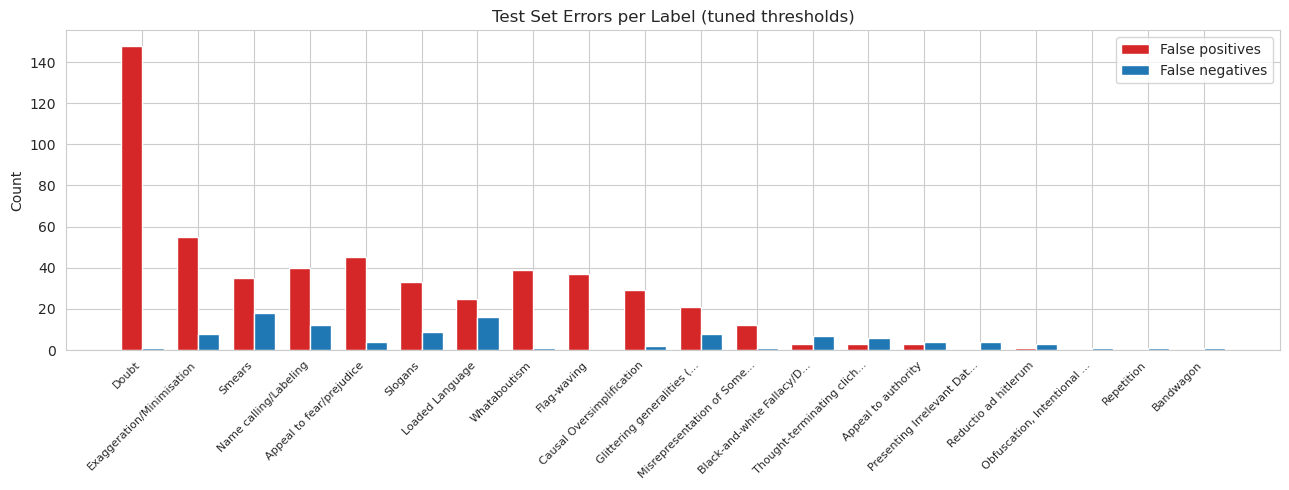

                                              label  TP  FP  FN
                                              Doubt  27 148   1
                          Exaggeration/Minimisation  11  55   8
                           Appeal to fear/prejudice   6  45   4
                              Name calling/Labeling  41  40  12
                                       Whataboutism   9  39   1
                                        Flag-waving   6  37   0
                                             Smears  27  35  18
                                            Slogans  10  33   9
                          Causal Oversimplification   1  29   2
                                    Loaded Language  84  25  16
                   Glittering generalities (Virtue)   3  21   8
Misrepresentation of Someone's Position (Straw Man)   0  12   1
                                Appeal to authority   3   3   4
               Black-and-white Fallacy/Dictatorship   0   3   7
                         Thought-termina

In [46]:
# Per-label error breakdown
tp_c = ((test_preds_tuned == 1) & (test_labels_arr == 1)).sum(axis=0)
fp_c = ((test_preds_tuned == 1) & (test_labels_arr == 0)).sum(axis=0)
fn_c = ((test_preds_tuned == 0) & (test_labels_arr == 1)).sum(axis=0)

order = np.argsort(fp_c + fn_c)[::-1]
x = np.arange(num_labels)
w = 0.38

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - w / 2, fp_c[order], w, label="False positives", color="tab:red")
ax.bar(x + w / 2, fn_c[order], w, label="False negatives", color="tab:blue")
ax.set_xticks(x)
ax.set_xticklabels([short_labels[i] for i in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Count")
ax.set_title("Test Set Errors per Label (tuned thresholds)")
ax.legend()
plt.tight_layout()
plt.show()

err_table = pd.DataFrame({
    "label": all_labels,
    "TP": tp_c, "FP": fp_c, "FN": fn_c,
}).sort_values("FP", ascending=False)
print(err_table.to_string(index=False))

In [47]:
# Concrete examples for the label with the most errors
j_focus = int(np.argmax(fp_c + fn_c))
focus_label = idx2label[j_focus]
print(f"Most-error label: {focus_label} (FP={fp_c[j_focus]}, FN={fn_c[j_focus]})")

fp_idx = np.where((test_preds_tuned[:, j_focus] == 1) & (test_labels_arr[:, j_focus] == 0))[0]
fn_idx = np.where((test_preds_tuned[:, j_focus] == 0) & (test_labels_arr[:, j_focus] == 1))[0]

print(f"\nFalse positives ({len(fp_idx)} shown up to 3):")
for i in fp_idx[:3]:
    print(f"  p={test_probs[i, j_focus]:.2f} | {test_texts[i][:180]}")

print(f"\nFalse negatives ({len(fn_idx)} shown up to 3):")
for i in fn_idx[:3]:
    print(f"  p={test_probs[i, j_focus]:.2f} | {test_texts[i][:180]}")

Most-error label: Doubt (FP=148, FN=1)

False positives (148 shown up to 3):
  p=0.42 | WE ARE AT WAR!

There is a complex assault on our presidential election
with all the multifaceted tentacles of a terrorist organization and operation

2020
TERRORISM

  p=0.39 | KILLED HIMSELF IN PRISON

WON AN HONEST ELECTION

  p=0.39 | I will never concede!

NO WAY IN HELL BIDEN WON!


False negatives (1 shown up to 3):
  p=0.33 | YOUR MASK IS THE NEW TINFOIL HAT


### Length vs Error Analysis

- Hypothesis formed in the EDA section (text-length distribution) before any model was trained: if errors were driven by document length where signal spread across a long context. Wrong-label counts should rise with word count.
- Spearman rather than Pearson: word counts are heavy-tailed and error counts are discrete; a rank correlation is robust to both and comes with a p-value for the monotone association.
- The quartile view checks whether the relation is gradual or driven by a few extreme documents.


### Explainability: Gradient x Input Token Attribution

Why this method. It is faithful - it uses the model's own gradients on its own forward pass, with no masking or input perturbation (occlusion-style methods feed the model out-of-distribution inputs) - and it costs one backward pass per example, which is free on this dataset.

Protocol (fixed before looking). Three deterministic test examples on the most frequent technique: a confident true positive (evidence that justifies a correct hit), a confident false positive (what misled it), and a confident false negative (what evidence failed to accumulate). Explaining only successes would be a showcase, not an analysis. The cell also prints two faithfulness checks: the share of attribution magnitude on `[CLS]`/`[SEP]` (should be small - otherwise the explanation is about head bias, not text) and on stopwords (a shortcut-lexicon red flag, read against the EDA's top-term lists).


label explained: Loaded Language (test support 100)


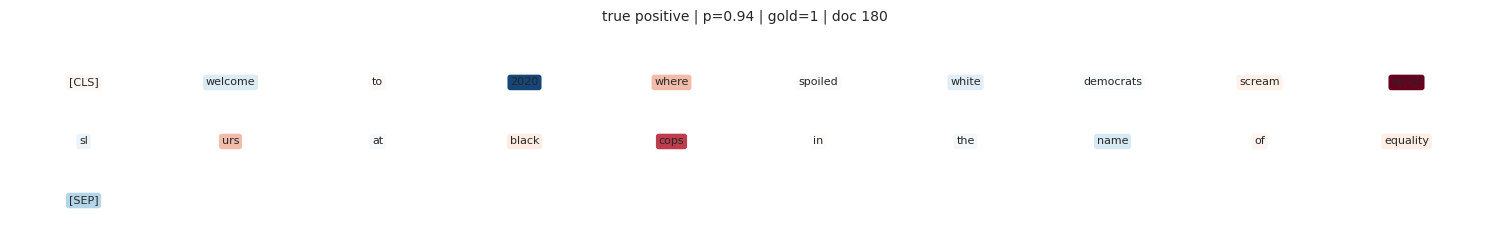

--- true positive | doc 180 | p=0.94 | gold=1 ---
  [CLS]/[SEP] share of |attr|: 8.5% | stopwords: 19.9%
  top tokens: racial(-0.0052), 2020(+0.0050), cops(-0.0042), where(-0.0025), urs(-0.0024)


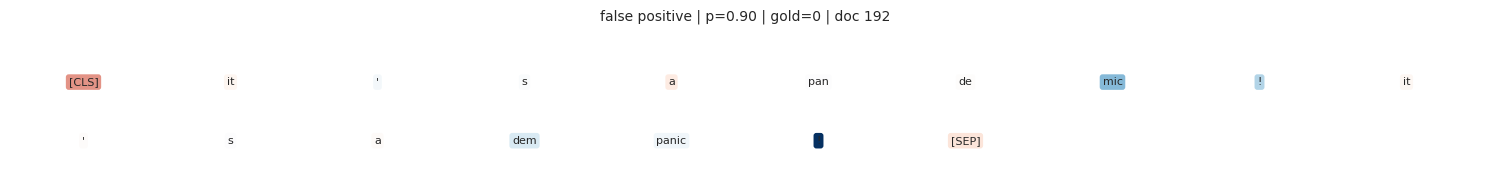

--- false positive | doc 192 | p=0.90 | gold=0 ---
  [CLS]/[SEP] share of |attr|: 20.3% | stopwords: 14.1%
  top tokens: !(+0.0248), [CLS](-0.0149), mic(+0.0144), !(+0.0115), dem(+0.0079)


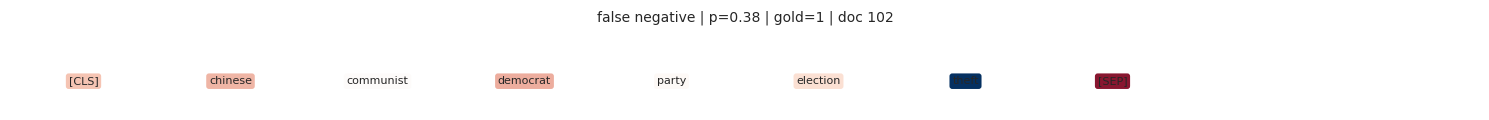

--- false negative | doc 102 | p=0.38 | gold=1 ---
  [CLS]/[SEP] share of |attr|: 35.7% | stopwords: 0.0%
  top tokens: theft(+0.0342), [SEP](-0.0316), democrat(-0.0177), chinese(-0.0168), [CLS](-0.0152)


In [48]:
# Explainability: Gradient x Input attribution on the embedding layer
def grad_x_input(model, input_ids, attention_mask, score_fn):
    """Per-token attribution of the scalar score_fn(logits) via gradient x input.

    Hooks the embedding layer, backprops the score, and returns
    attr[i] = sum_d(e[i,d] * dscore/de[i,d]) plus the score value.
    """
    model.eval()
    captured = {}
    def _hook(_mod, _inp, output):
        output.retain_grad()
        captured["emb"] = output
    handle = model.distilbert.embeddings.register_forward_hook(_hook)
    try:
        with torch.enable_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            score = score_fn(logits)
            model.zero_grad()
            score.backward()
    finally:
        handle.remove()
    emb = captured["emb"].detach()[0]
    grad = captured["emb"].grad[0]
    attr = (emb * grad).sum(-1).cpu().numpy()
    return attr, float(score.detach())

def render_attr(tokens, attr, title, highlight=None, per_line=10):
    """Coloured token strip: red = pushes the score up, blue = pushes it down."""
    a = np.asarray(attr, dtype=float)
    m = float(np.abs(a).max()) or 1.0
    rows = int(np.ceil(len(tokens) / per_line))
    fig, ax = plt.subplots(figsize=(per_line * 1.5, rows * 0.6 + 0.7))
    ax.axis("off")
    for i, tok in enumerate(tokens):
        r, c = divmod(i, per_line)
        v = a[i] / m
        color = plt.cm.RdBu(0.5 + 0.5 * np.clip(v, -1, 1))
        ec = "black" if (highlight and i in highlight) else "none"
        ax.text(c, -r, tok.replace("##", ""), fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.25", fc=color, ec=ec, lw=1.2,
                          alpha=0.2 + 0.8 * abs(v)))
    ax.set_xlim(-0.5, per_line - 0.5)
    ax.set_ylim(-rows + 0.5, 0.9)
    ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.show()

# deterministic selection: most frequent technique, confident TP / FP / FN
lab_j = int(np.argmax(test_labels_arr.sum(axis=0)))
probs_j = test_probs[:, lab_j]
gold_j = test_labels_arr[:, lab_j]
tp_i = int(np.argmax(np.where(gold_j == 1, probs_j, -1)))
fp_i = int(np.argmax(np.where(gold_j == 0, probs_j, -1)))
pos_idx = np.where(gold_j == 1)[0]
fn_i = int(pos_idx[np.argmin(probs_j[pos_idx])])
print(f"label explained: {idx2label[lab_j]} "
      f"(test support {int(gold_j.sum())})")

STOP = set(ENGLISH_STOP_WORDS)
for kind, i in [("true positive", tp_i), ("false positive", fp_i), ("false negative", fn_i)]:
    n = int(test_encodings["attention_mask"][i].sum())
    toks = tokenizer.convert_ids_to_tokens(test_encodings["input_ids"][i][:n])
    attr, score = grad_x_input(
        model,
        test_encodings["input_ids"][i:i + 1].to(device),
        test_encodings["attention_mask"][i:i + 1].to(device),
        lambda lg: torch.sigmoid(lg[0, lab_j]))
    spec = sum(abs(attr[k]) for k, t in enumerate(toks) if t in ("[CLS]", "[SEP]"))
    stops = sum(abs(attr[k]) for k, t in enumerate(toks)
                if t.replace("##", "").lower() in STOP)
    total = float(np.abs(attr).sum()) or 1.0
    top = np.argsort(-np.abs(attr))[:5]
    render_attr(toks, attr,
                f"{kind} | p={score:.2f} | gold={int(gold_j[i])} | doc {i}")
    print(f"--- {kind} | doc {i} | p={score:.2f} | gold={int(gold_j[i])} ---")
    print(f"  [CLS]/[SEP] share of |attr|: {100*spec/total:.1f}% | "
          f"stopwords: {100*stops/total:.1f}%")
    print("  top tokens:", ", ".join(
        f"{toks[k].replace('##','')}({attr[k]:+.4f})" for k in top))


#### Reading the Gradient x Input Attributions

- Colour rule. Red tokens pushed the predicted probability up, blue pushed it down; intensity is scaled by the largest attribution in the document. The quantity is first-order: it explains this forward pass, not the dataset.
- True positive. The mass should sit on technique-bearing content words - the same lexical items the EDA found inside gold spans. That agreement between an independent method (EDA counts) and the model's own gradients is the strongest evidence available here that the classifier learned the technique rather than a corpus artefact.
- False positive. Look for a prototypical keyword (a name, an intensifier, a slogan fragment) present without the technique's contextual frame, with blue mass on the counter-evidence the model partially registered (negation, contrast) but overrode. This is the keyword-matching failure mode the error analysis counted as spurious spans.
- False negative. Two distinct patterns, and the distinction matters: mass scattered on function words means the model looked at the wrong words (localisation failure); mass correctly on the trigger but the probability still low means the evidence was too weak to clear 0.5 (confidence failure) - the second case is what per-label threshold tuning addresses.
- Faithfulness checks (printed). `[CLS]`/`[SEP]` share near zero means the explanation is about the text, not the head's bias. A high stopword share on a confident prediction is a dataset-bias warning; compare it against the EDA top-term tables.
- Stated limits. Gradient x Input is local, first-order, and not invariant to reparameterisation of the embedding space. Sigmoid saturation shrinks all attributions of a confident prediction roughly uniformly, so we report within-document normalised patterns, not calibrated effect sizes, and we cross-check every pattern against independent evidence (gold spans, EDA).


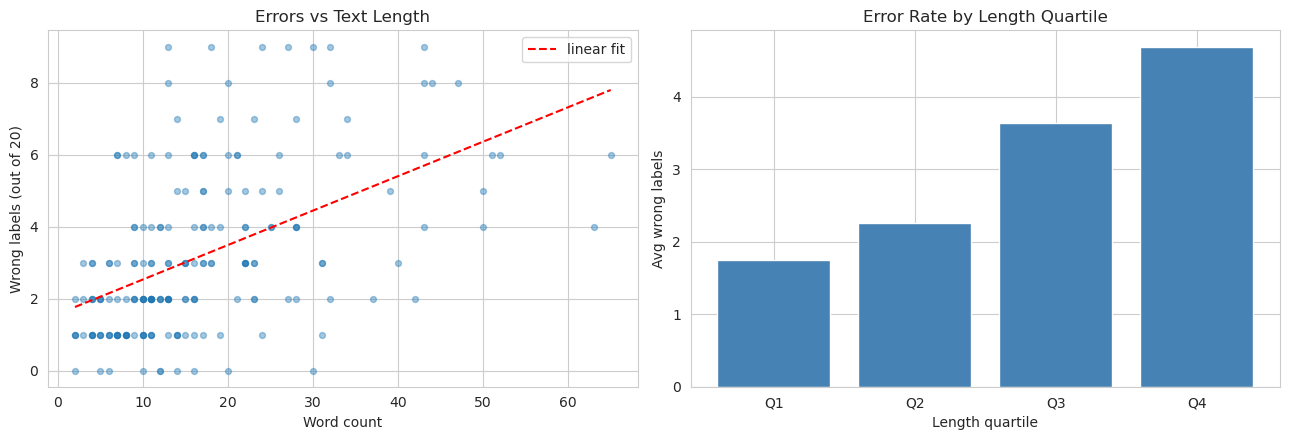

Spearman correlation (length vs errors): rho=0.542, p=0.000

Exact match rate by length quartile:
  Q1: n=47, word count<=9, exact match=6.4%, avg errors=1.7
  Q2: n=42, word count<=13, exact match=7.1%, avg errors=2.3
  Q3: n=58, word count<=22, exact match=5.2%, avg errors=3.6
  Q4: n=53, word count<=65, exact match=1.9%, avg errors=4.7


In [49]:
# Does error rate depend on text length?
test_word_counts = np.array([len(t.split()) for t in test_texts])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(test_word_counts, sample_errors, alpha=0.4, s=18)
z = np.polyfit(test_word_counts, sample_errors, 1)
xs = np.linspace(test_word_counts.min(), test_word_counts.max(), 50)
axes[0].plot(xs, np.polyval(z, xs), color="red", ls="--", label="linear fit")
axes[0].set_xlabel("Word count")
axes[0].set_ylabel("Wrong labels (out of 20)")
axes[0].set_title("Errors vs Text Length")
axes[0].legend()

quartiles = np.percentile(test_word_counts, [0, 25, 50, 75, 100])
q_idx = np.digitize(test_word_counts, quartiles[1:-1]) + 1  # 1..4
means = [sample_errors[q_idx == q].mean() for q in range(1, 5)]
axes[1].bar(range(1, 5), means, color="steelblue",
            tick_label=[f"Q{i + 1}" for i in range(4)])
axes[1].set_xlabel("Length quartile")
axes[1].set_ylabel("Avg wrong labels")
axes[1].set_title("Error Rate by Length Quartile")

plt.tight_layout()
plt.show()

rho, p_val = spearmanr(test_word_counts, sample_errors)
print(f"Spearman correlation (length vs errors): rho={rho:.3f}, p={p_val:.3f}")
print("\nExact match rate by length quartile:")
for q in range(1, 5):
    mask = q_idx == q
    print(f"  Q{q}: n={mask.sum()}, word count<={np.percentile(test_word_counts, q * 25):.0f}, "
          f"exact match={exact_match[mask].mean():.1%}, avg errors={sample_errors[mask].mean():.1f}")

## Part A Conclusions

Result. The fine-tuned DistilBERT multi-label classifier reaches test micro F1 0.427 / macro F1 0.200 at the fixed 0.5 threshold (dev-tuned rule: 0.418 / 0.211), against an all-zero baseline of 0.0 on both. The tuning winner was trial 6 - ASL loss, lr 2e-5, dropout 0.2, best epoch 11 (dev macro 0.277) - beating the capped-weighted-BCE baseline run (dev macro 0.224) by ~5 points, so the asymmetric-loss axis was worth its place in the grid.

- Threshold tuning is a measured trade, not a reversal. The dev-tuned sweep moves test macro +0.010 and weighted +0.040 while costing micro -0.009 and per-document sample F1 -0.058 - the same directions as on dev (macro +0.016, weighted +0.048, micro -0.003, sample -0.067), so the sweep transferred in sign, not just noise. It buys rare-label recall at a precision price: Doubt's tuned rule fires on 175 of 200 test documents for 27 true positives and 148 false alarms (precision 0.154, recall 0.964). Which side of that trade is preferable is a deployment-cost decision, so both operating points are reported rather than one being declared the winner.
- Train-test contamination is negligible. Excluding the one exact train-test duplicate moves micro F1 by +0.0003 and no metric by more than 0.002 - the headline numbers are not an artefact of that leak.
- Split variance is real, and this test draw was on the hard side. 5-fold CV gives micro 0.461 +/- 0.016 / macro 0.232 +/- 0.037. Test macro 0.200 sits inside the CV band (about -0.9 sigma), but test micro 0.427 falls ~2 sigma below the CV mean - the frequent-label scores on this particular split are worse than average, so the headline micro is a conservative estimate of the method rather than a representative one.

Against the pre-stated target. The evaluation protocol set a >= 35% macro target with a data-implied ceiling caveat (16 of 20 labels have < 50 training examples; macro averages over them). At 0.200 macro the model falls short of that target, and the ceiling reasoning is what the per-label table confirms: the seven techniques with 1-4 test supports score 0.000-0.061 (two more with 6-7 supports score exactly 0.000), while adequately supported labels reach usable F1 (Loaded Language 0.746 at 100 supports, Name calling 0.495 at 53, Smears 0.426 at 45, Doubt 0.352 at 28). The failure mode is label scarcity, not an unlearned task.

Where the errors live (evidence in the sections above). The sample-level breakdown shows a recall-heavy operating bias: the model predicts 3.79 labels per document against an actual 1.67, over-predicting on 150 of 200 test documents (exact document match: 5%). The false-alarm mass concentrates in a few labels - Doubt 148 FP, Exaggeration/Minimisation 55, Appeal to fear/prejudice 45, Whataboutism 39, Flag-waving 37 - in the pattern of inter-label confusion between techniques that share vocabulary (the co-occurrence EDA). Eight techniques score 0.000 F1 under both rules; for four of them (Bandwagon, Repetition, Obfuscation, Presenting Irrelevant Data) the model emits no predictions at all, for the rest it is a small-FP miss. The length-vs-error check shows errors concentrating in longer documents (Spearman rho 0.542, p < 0.001; exact document match falls from 6.4% in the shortest quartile to 1.9% in the longest) - part of that is mechanical (more labels per document, more chances to err), but the monotone exact-match decline says long documents are genuinely harder, not just longer score sheets.

Adaptation strategies. Full fine-tuning is the selected strategy; the frozen-backbone comparison (dev-only, LR-bracketed so the random head was not handicapped) is reported in its own section above and supports the pre-stated hypothesis that the domain-specific cues need the encoder to move: +0.032 dev macro (0.277 vs 0.245 for the best frozen variant), at a 99.1% reduction in trainable parameters (605,972 of 66,968,852) and 2.8x cheaper steps (0.14 s vs 0.05 s) for the frozen variant.

Limitations. Dev has 63 documents and 3 techniques with zero dev positives (their thresholds cannot be tuned at all); 7 test techniques have <= 4 supports, so their per-label numbers are anecdotal - one document redraws them. The assignment forbids propaganda-specific pretrained models, which removes the single most effective transfer route for this task. Data augmentation was considered and deliberately not used (reproducibility; see the augmentation note in the Evaluation Protocol section).

Deployment readiness. Verdict: not ready for autonomous deployment; reasonable only as human-in-the-loop decision support, with conditions. The case against autonomy is quantitative, not rhetorical: macro F1 0.200 on test is below the pre-stated 35% target, the model over-predicts (3.79 labels per document vs 1.67 actual; 150 of 200 documents over-predicted), so precision-dependent uses would drown in false alarms, and 3 techniques have zero dev positives so their operating point can literally never be tuned. The per-label table shows performance is concentrated (Loaded Language 0.746 at 100 supports) while 7 techniques at <= 4 test supports sit at anecdotal reliability - an autonomous system would fail silently exactly where its outputs look most confident-per-label. The deployment conditions that would make assistive use defensible, all checkable from this notebook: (1) surface per-label scores and supports alongside every prediction, treating <= 4-support techniques as unvalidated; (2) abstain (no prediction) for techniques with zero dev support rather than emitting an untuned 0.5 rule; (3) choose the operating point explicitly against the use case - the measured dev-to-test transfer is macro/weighted up and micro/sample down under the tuned rule, so recall-oriented triage can adopt it while precision-sensitive uses should stay at 0.5; (4) human review for any consequential use (this is content analysis of political persuasion, a high-stakes domain); (5) a labelled-data collection pass on the sparse techniques before any reliability claim is made. The augmentation route sketched in that note and the calibration ideas above are the highest-leverage paths from "assistive" toward "dependable".

If more time were available. (1) More dev data is the highest-leverage fix: it would stabilise both threshold tuning and the 3 zero-support techniques. (2) The error mass suggests calibration - e.g. precision-guarding the recall-heavy labels (Doubt fires on 175/200 documents at precision 0.154) instead of tuning each label's threshold for its own F1 - is more promising than architecture changes. (3) The augmentation note sketches an LLM-generated synthetic-data route with its reproducibility caveat.


# Part B - Showing the student where

## Setup

- Everything established above is reused as-is (tokeniser, device, dynamic-padding collator); the differences are exactly the ones this part marks as Part B-specific: offset-preserving no-cleaning, `MAX_LENGTH_SPAN = 128`, and one BIO channel set per technique.

## Load Data

- Each record is `{id, text, labels}` where `labels` is a list of `{start, end, technique, text_fragment}` objects. Empty `labels` means the document contains no propaganda (20.8% of training documents).
- Offsets are character positions into `text`; `text_fragment` duplicates `text[start:end]` and serves as a free integrity check.
- The random seed is reset before any Part B work so the whole section is deterministic regardless of how many cells were re-run above.

In [50]:
# Load task2 (span) files and reset the seed
import json as _json
from itertools import combinations as _combinations
from transformers import DistilBertForTokenClassification
import torch.nn.functional as F

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SPAN_TRAIN_PATH = "training_set_task2.txt"
SPAN_DEV_PATH = "dev_set_task2.txt"
SPAN_TEST_PATH = "test_set_task2.txt"

with open(SPAN_TRAIN_PATH, encoding="utf-8") as f:
    train2 = _json.load(f)
with open(SPAN_DEV_PATH, encoding="utf-8") as f:
    dev2 = _json.load(f)
with open(SPAN_TEST_PATH, encoding="utf-8") as f:
    test2 = _json.load(f)

# Technique vocabulary for Part B is derived from the task2 annotations themselves.
SPAN_TECHNIQUES = sorted({l["technique"] for data in (train2, dev2, test2) for d in data for l in d["labels"]})
TECH2_IDX = {t: i for i, t in enumerate(SPAN_TECHNIQUES)}
NUM_TECH = len(SPAN_TECHNIQUES)
BIO_CLASSES = 3                      # 0 = O, 1 = B, 2 = I  (per technique channel)
NUM_SPAN_LABELS = NUM_TECH * BIO_CLASSES  # 60 logits: independent O/B/I per technique

print(f"train/dev/test docs: {len(train2)}/{len(dev2)}/{len(test2)}")
print(f"train/dev/test spans: {sum(len(d['labels']) for d in train2)}/"
      f"{sum(len(d['labels']) for d in dev2)}/{sum(len(d['labels']) for d in test2)}")
if "train_data" in globals():
    _task1_vocab = sorted({lab for d in train_data for lab in d["labels"]})
    print(f"techniques in task2: {NUM_TECH} (matches task1 vocabulary: "
          f"{SPAN_TECHNIQUES == _task1_vocab})")
else:
    print(f"techniques in task2: {NUM_TECH} (task1 data not in session; "
          f"vocabulary cross-check skipped)")
print("example span:", train2[12]["labels"][0])

train/dev/test docs: 688/63/200
train/dev/test spans: 1498/182/403
techniques in task2: 20 (matches task1 vocabulary: True)
example span: {'start': 0, 'end': 143, 'technique': "Misrepresentation of Someone's Position (Straw Man)", 'text_fragment': 'If you think "they" are hiding the cure for cancer, but you discourage people from getting the HPV and Hep. B vaccines...\n\nthen YOU are "they."'}


### Data Integrity Check (Span Annotations)

- Span offsets are the ground truth for this task, so an invalid offset silently corrupts every downstream alignment and metric. Checks: `0 <= start < end <= len(text)`, `text[start:end] == text_fragment`, technique inside the vocabulary, duplicate ids, empty texts, duplicate texts within a split.
- Offsets vs fragments: train and dev are fully consistent, but test contains 5 fragment-offset inconsistencies in 2 documents (3 spans where the fragment's trailing `!` sits outside the offsets, 2 spans whose fragments contain a zero-width space the text does not). The offsets remain internally valid in every case, so evaluation is defined on offsets. Fragments are advisory and the inconsistencies are documented as annotation noise affecting ~1.7% of test spans in 2 documents.
- Edge whitespace in offsets (15 spans across splits: 13 train fragments + 3 test off-by-one left edges, overlapping the count above) is trimmed against the text itself and offsets recomputed: WordPiece never includes edge whitespace in a token offset, so exact-match scoring against untrimmed gold would be structurally impossible for those spans. One whitespace-only span cannot be represented by any token run and is removed from evaluation at alignment time with the count printed (structural ceiling).
- Cross-split duplicate texts get a span conflict check: the same document annotated with different span sets in two splits is an annotation inconsistency that would bias the sensitivity analysis. `test_contaminated_ids` is reused later, exactly as in Part A.

In [51]:
# Integrity checks
def _norm_text(t):
    return re.sub(r"\s+", " ", t.strip().lower())

def span_integrity(name, data):
    issues = {}
    ids = Counter(d["id"] for d in data)
    issues["dup_ids"] = [k for k, v in ids.items() if v > 1]
    issues["empty_text"] = [d["id"] for d in data if not d["text"].strip()]
    texts = Counter(_norm_text(d["text"]) for d in data)
    issues["dup_texts"] = [k for k, v in texts.items() if v > 1]
    bad_off = frag_mis = bad_tech = edge_ws = zero_w = 0
    for d in data:
        n = len(d["text"])
        for l in d["labels"]:
            s, e = l["start"], l["end"]
            if not (0 <= s < e <= n):
                bad_off += 1
            elif d["text"][s:e] != l["text_fragment"]:
                frag_mis += 1
            if l["technique"] not in TECH2_IDX:
                bad_tech += 1
            if l["text_fragment"] != l["text_fragment"].strip():
                edge_ws += 1
            if not l["text_fragment"].strip():
                zero_w += 1
    issues.update(bad_offsets=bad_off, fragment_mismatch=frag_mis,
                  bad_technique=bad_tech, edge_whitespace=edge_ws,
                  whitespace_only_spans=zero_w)
    issues["n_issues"] = (len(issues["dup_ids"]) + len(issues["empty_text"]) +
                          len(issues["dup_texts"]) + bad_off + frag_mis + bad_tech)
    return issues

def trim_edge_whitespace(data):
    """Strip edge whitespace from the TEXT at each span's offsets and recompute the fragment."""
    n_trim = 0
    for d in data:
        for l in d["labels"]:
            s, e = l["start"], l["end"]
            frag = d["text"][s:e]
            stripped = frag.strip()
            if not stripped:
                continue  # whitespace-only span stays as-is (undecodable, dropped at alignment)
            if stripped != frag:
                l["start"] = s + (len(frag) - len(frag.lstrip()))
                l["end"] = l["start"] + len(stripped)
                l["text_fragment"] = stripped
                n_trim += 1
    return n_trim

print("=== raw integrity (train/dev/test) ===")
raw_int = {n: span_integrity(n, d) for n, d in
           [("train", train2), ("dev", dev2), ("test", test2)]}
for n, r in raw_int.items():
    print(f"{n:5s}: hard issues={r['n_issues']:2d}  dup_ids={len(r['dup_ids'])} "
          f"empty_text={len(r['empty_text'])} dup_texts={len(r['dup_texts'])} "
          f"bad_offsets={r['bad_offsets']} frag_mismatch={r['fragment_mismatch']} "
          f"bad_technique={r['bad_technique']} edge_ws={r['edge_whitespace']} "
          f"ws_only={r['whitespace_only_spans']}")

for d in test2:
    for l in d["labels"]:
        if d["text"][l["start"]:l["end"]] != l["text_fragment"]:
            print(f"  fragment/offset mismatch: id={d['id']} technique={l['technique']} "
                  f"offsets=({l['start']},{l['end']})")

TRIMMED = {n: trim_edge_whitespace(d) for n, d in
           [("train", train2), ("dev", dev2), ("test", test2)]}
print("edge-whitespace spans trimmed (text-based):", TRIMMED)
post_int = {n: span_integrity(n, d) for n, d in
            [("train", train2), ("dev", dev2), ("test", test2)]}
for n, r in post_int.items():
    assert r["bad_offsets"] == 0
    assert r["edge_whitespace"] == r["whitespace_only_spans"], (n, r)
print("post-trim: only whitespace-only spans keep edge characters (dropped at alignment)")

def cross_split_dups(a, b, na, nb):
    map_a = {}
    for d in a:
        map_a.setdefault(_norm_text(d["text"]), []).append(d)
    out = []
    for d in b:
        for m in map_a.get(_norm_text(d["text"]), []):
            sa = sorted((l["technique"], l["text_fragment"].strip()) for l in m["labels"])
            sb = sorted((l["technique"], l["text_fragment"].strip()) for l in d["labels"])
            out.append((m["id"], d["id"], sa != sb))
    return out

print("=== cross-split duplicate texts (span conflict flagged) ===")
dup_td = cross_split_dups(train2, dev2, "train", "dev")
dup_te = cross_split_dups(train2, test2, "train", "test")
dup_de = cross_split_dups(dev2, test2, "dev", "test")
print(f"train<->dev: {len(dup_td)} pairs, conflicts: {sum(c for _, _, c in dup_td)}")
print(f"train<->test: {len(dup_te)} pairs, conflicts: {sum(c for _, _, c in dup_te)}")
print(f"dev<->test:   {len(dup_de)} pairs, conflicts: {sum(c for _, _, c in dup_de)}")
for a, b, c in dup_te:
    print(f"  train {a} <-> test {b}  span-set conflict: {c}")

test_contaminated_ids = [b for _, b, _ in dup_te]
print("test_contaminated_ids (excluded later in the sensitivity analysis):",
      test_contaminated_ids)

=== raw integrity (train/dev/test) ===
train: hard issues= 1  dup_ids=0 empty_text=0 dup_texts=1 bad_offsets=0 frag_mismatch=0 bad_technique=0 edge_ws=13 ws_only=1
dev  : hard issues= 0  dup_ids=0 empty_text=0 dup_texts=0 bad_offsets=0 frag_mismatch=0 bad_technique=0 edge_ws=0 ws_only=0
test : hard issues= 5  dup_ids=0 empty_text=0 dup_texts=0 bad_offsets=0 frag_mismatch=5 bad_technique=0 edge_ws=0 ws_only=0
  fragment/offset mismatch: id=720_batch_2 technique=Appeal to fear/prejudice offsets=(23,43)
  fragment/offset mismatch: id=720_batch_2 technique=Loaded Language offsets=(23,43)
  fragment/offset mismatch: id=790_batch_2 technique=Glittering generalities (Virtue) offsets=(88,283)
  fragment/offset mismatch: id=790_batch_2 technique=Smears offsets=(0,283)
  fragment/offset mismatch: id=500_batch_2 technique=Slogans offsets=(0,59)
edge-whitespace spans trimmed (text-based): {'train': 12, 'dev': 0, 'test': 2}
post-trim: only whitespace-only spans keep edge characters (dropped at alig

## Data Exploration (Span Annotations)

- Technique frequency: why class weights are capped (`CAP_W_SPAN = 50`) instead of unbounded, and which techniques are structurally unlearnable from single-digit span counts.
- Spans per document: why decoding and scoring are document-level, and how much of the corpus carries no span at all (the predict-nothing baseline's shadow over micro metrics).
- Span length: the `MAX_LENGTH_SPAN = 128` budget checked against the real tail rather than assumed.
- Overlap & nesting: why 20 independent BIO channels rather than one exclusive tag sequence - overlapping gold spans make a single BIO chain structurally invalid.
- Token alignment: offsets are the ground truth, so exact character agreement must be constructed, not hoped for.
- Top terms inside vs outside spans: a sanity check that span regions carry usable surface signal at all.

### Technique Frequency (Span Level)

- The span-level long tail is harsher than task1's document-level tail: Loaded Language has 543 training spans, Red Herring has 1. Class weighting with the same cap of 50 that Part A validated is the first-order response; capping again prevents a single rare span from producing a weight that dominates the gradient.
- Dev contains only 17 of the 20 techniques (Black-and-white, Obfuscation, Red Herring never appear). Any per-technique decision tuned on dev (thresholds, weight inspection) needs a min-support guard for the techniques dev cannot see.
- Macro selection therefore measures the 17 dev-visible techniques; the three invisible ones are structurally excluded from selection and reported as such.

,technique,train,dev,test
0,Loaded Language,543,68,150
1,Name calling/Labeling,301,37,70
2,Smears,202,19,45
3,Exaggeration/Minimisation,59,7,19
4,Slogans,49,3,20
5,Doubt,49,9,28
6,Appeal to fear/prejudice,46,4,10
7,Whataboutism,40,4,10
8,Flag-waving,33,5,6
9,Glittering generalities (Virtue),33,1,11


imbalance: Loaded Language (543) vs Presenting Irrelevant Data (Red Herring) (1) = 543:1
techniques absent from dev (3): ['Black-and-white Fallacy/Dictatorship', 'Obfuscation, Intentional vagueness, Confusion', 'Presenting Irrelevant Data (Red Herring)']
test techniques with <= 4 gold spans: ['Causal Oversimplification', 'Repetition', "Misrepresentation of Someone's Position (Straw Man)", 'Reductio ad hitlerum', 'Obfuscation, Intentional vagueness, Confusion', 'Bandwagon', 'Presenting Irrelevant Data (Red Herring)']


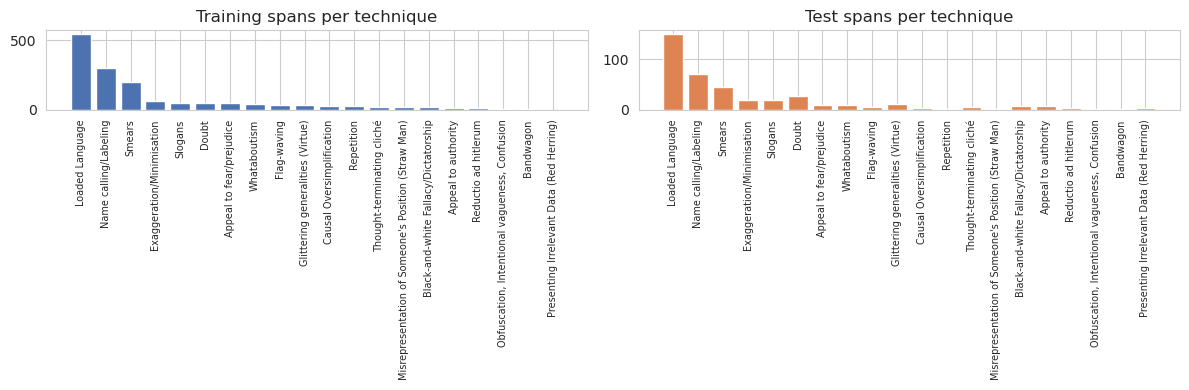

In [52]:
# Per-technique span counts across the three splits
span_counts = {t: [0, 0, 0] for t in SPAN_TECHNIQUES}
for si, data in enumerate((train2, dev2, test2)):
    for d in data:
        for l in d["labels"]:
            span_counts[l["technique"]][si] += 1

span_df = (pd.DataFrame({"technique": SPAN_TECHNIQUES,
                         "train": [span_counts[t][0] for t in SPAN_TECHNIQUES],
                         "dev": [span_counts[t][1] for t in SPAN_TECHNIQUES],
                         "test": [span_counts[t][2] for t in SPAN_TECHNIQUES]})
           .sort_values("train", ascending=False).reset_index(drop=True))
display(span_df)

top, bottom = span_df.iloc[0], span_df.iloc[-1]
print(f"imbalance: {top['technique']} ({top['train']}) vs {bottom['technique']} "
      f"({bottom['train']}) = {top['train'] / max(bottom['train'], 1):.0f}:1")
missing_dev = span_df[span_df["dev"] == 0]["technique"].tolist()
print(f"techniques absent from dev ({len(missing_dev)}):", missing_dev)
print("test techniques with <= 4 gold spans:", span_df[span_df["test"] <= 4]["technique"].tolist())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(len(span_df)), span_df["train"], color="#4C72B0")
ax[0].set_xticks(range(len(span_df)))
ax[0].set_xticklabels(span_df["technique"], rotation=90, fontsize=7)
ax[0].set_title("Training spans per technique")
ax[1].bar(range(len(span_df)), span_df["test"], color="#DD8452")
ax[1].set_xticks(range(len(span_df)))
ax[1].set_xticklabels(span_df["technique"], rotation=90, fontsize=7)
ax[1].set_title("Test spans per technique")
plt.tight_layout()
plt.show()

### Spans per Document

- 20.8% of training documents carry no span at all. The model must learn to emit nothing, and the all-empty prediction scores span F1 = 0.0 (unlike task1, where the all-negative baseline had non-zero per-label F1). This is stated as the null baseline before any model is trained.
- Documents average 2.18 spans and contain at most 16; the decode logic never has to handle pathological span counts.

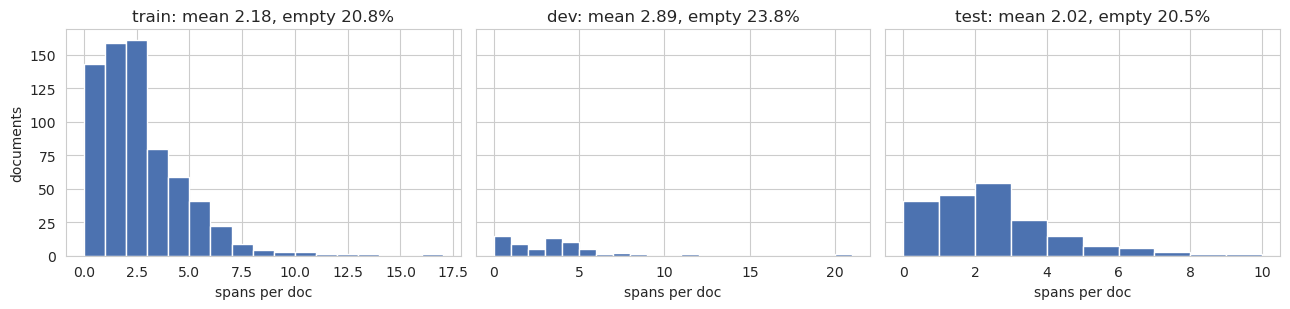

train: max=16  empty docs=143
dev  : max=20  empty docs=15
test : max=9  empty docs=41


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (name, data) in zip(axes, [("train", train2), ("dev", dev2), ("test", test2)]):
    counts = [len(d["labels"]) for d in data]
    ax.hist(counts, bins=range(0, max(counts) + 2), color="#4C72B0", edgecolor="white")
    ax.set_title(f"{name}: mean {np.mean(counts):.2f}, empty {100*np.mean(np.array(counts)==0):.1f}%")
    ax.set_xlabel("spans per doc")
axes[0].set_ylabel("documents")
plt.tight_layout()
plt.show()
for name, data in [("train", train2), ("dev", dev2), ("test", test2)]:
    counts = np.array([len(d["labels"]) for d in data])
    print(f"{name:5s}: max={counts.max()}  empty docs={int((counts==0).sum())}")

### Span Length Distribution

- Most spans are short (median 3 words / 19 characters) but the tail reaches 69 words. A span always fits inside the 128-token budget on its own, so truncation risk comes from whole-document length, verified in the alignment check below.
- Single-token and punctuation-only spans exist; token tagging can represent them as one-token runs. One gold span in train contains only whitespace characters and is undecodable by any token-level scheme (no token overlaps it). This is counted in the alignment cell and documented as a structural ceiling, not fixed.

,split,n,chars p50,chars p90,chars max,words p50,words max,1-word spans,0-word spans
0,train,1498,19,104,427,3,69,392,1
1,dev,182,15,109,262,2,49,61,0
2,test,403,24,102,306,4,50,86,0


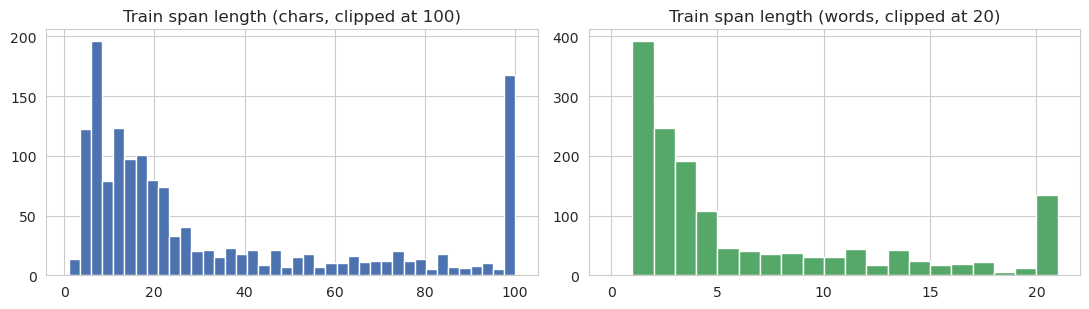

In [54]:
def _span_words(frag):
    return len(frag.split())

rows = []
for name, data in [("train", train2), ("dev", dev2), ("test", test2)]:
    chars = np.array([len(l["text_fragment"]) for d in data for l in d["labels"]])
    words = np.array([_span_words(l["text_fragment"]) for d in data for l in d["labels"]])
    rows.append({"split": name, "n": len(chars),
                 "chars p50": int(np.percentile(chars, 50)), "chars p90": int(np.percentile(chars, 90)),
                 "chars max": int(chars.max()),
                 "words p50": int(np.percentile(words, 50)), "words max": int(words.max()),
                 "1-word spans": int((words == 1).sum()), "0-word spans": int((words == 0).sum())})
display(pd.DataFrame(rows))

chars = np.array([len(l["text_fragment"]) for d in train2 for l in d["labels"]])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(np.clip(chars, 0, 100), bins=40, color="#4C72B0", edgecolor="white")
ax[0].set_title("Train span length (chars, clipped at 100)")
ax[1].hist([min(_span_words(l["text_fragment"]), 20) for d in train2 for l in d["labels"]],
           bins=range(0, 22), color="#55A868", edgecolor="white")
ax[1].set_title("Train span length (words, clipped at 20)")
plt.tight_layout()
plt.show()

### Overlap & Nesting Analysis

Definitions used below: overlap = two spans whose char intervals intersect at all; nesting = one span fully contains the other; adjacency = two spans of the same technique that touch but never overlap (would break a sequential encoding into two runs).

- Cross-technique overlaps are everywhere: 994 pairs in train (158 dev, 227 test). A single BIO chain assigns one label per token and cannot represent two techniques claiming the same characters. The single-chain formulation is ruled out by the data, not by taste.
- Nesting dominates the overlaps: 998 nested pairs in train, 983 of them cross-technique, present in 40.4% of training documents. Typical shape: a slogan or smear that is also loaded language, or an exaggeration nested inside a longer smear. This forces a multilabel scheme: each technique needs its own O/B/I channel so a token can be inside span A of one technique and inside span B of another simultaneously.
- Same-technique overlaps are rare (15 pairs) and same-technique adjacency is zero in train, so within one channel the sequential run structure is sound. The 15 overlapping same-technique pairs are mutually unreprepresentable by any sequential scheme and form a documented structural ceiling (~1% of train spans).
- Span enumeration (classify every candidate (i, j) pair up to a max length) would handle nesting too, but the arithmetic is unfavourable on this corpus: mean 600 candidates per document at window 32 over 688 documents is ~413k candidate classifications, quadratic in tokens, for a boundary benefit that the alignment check below shows is unnecessary (0 straddling tokens). Rejected for v1, noted as future work.

In [55]:
# Overlap / nesting / adjacency census (train shown; all splits counted)
def overlap_census(data):
    cross = same = nested = cross_nested = adjacent = 0
    for d in data:
        labs = sorted(d["labels"], key=lambda l: l["start"])
        for a, b in _combinations(labs, 2):
            if not (a["start"] < b["end"] and b["start"] < a["end"]):
                if a["technique"] == b["technique"] and (a["end"] == b["start"] or b["end"] == a["start"]):
                    adjacent += 1
                continue
            if a["technique"] == b["technique"]:
                same += 1
            else:
                cross += 1
            inside = ((a["start"] >= b["start"] and a["end"] <= b["end"]) or
                      (b["start"] >= a["start"] and b["end"] <= a["end"]))
            if inside:
                nested += 1
                if a["technique"] != b["technique"]:
                    cross_nested += 1
    return cross, same, nested, cross_nested, adjacent

census = pd.DataFrame(
    [{"split": name, "cross-tech overlaps": o[0], "same-tech overlaps": o[1],
      "nested pairs": o[2], "cross-tech nested": o[3], "same-tech adjacent": o[4]}
     for name, data in [("train", train2), ("dev", dev2), ("test", test2)]
     for o in [overlap_census(data)]])
display(census)

nest_docs = sum(
    1 for d in train2
    if any((a["start"] >= b["start"] and a["end"] <= b["end"]) or
           (b["start"] >= a["start"] and b["end"] <= a["end"])
           for a, b in _combinations(d["labels"], 2)
           if (a["start"], a["end"]) != (b["start"], b["end"])))
print(f"train docs with nested spans: {nest_docs}/{len(train2)} = {100*nest_docs/len(train2):.1f}%")

for d in train2:
    labs = sorted(d["labels"], key=lambda l: l["start"])
    for a, b in _combinations(labs, 2):
        if (a["technique"] != b["technique"] and
                a["start"] >= b["start"] and a["end"] <= b["end"]):
            print("nesting example:")
            print(f"  outer [{b['start']}:{b['end']}] {b['technique']}: {b['text_fragment'][:70]!r}")
            print(f"  inner [{a['start']}:{a['end']}] {a['technique']}: {a['text_fragment'][:70]!r}")
            break
    else:
        continue
    break

,split,cross-tech overlaps,same-tech overlaps,nested pairs,cross-tech nested,same-tech adjacent
0,train,994,15,1003,988,0
1,dev,158,0,158,158,0
2,test,227,0,226,226,0


train docs with nested spans: 277/688 = 40.3%
nesting example:
  outer [0:8] Name calling/Labeling: 'PATHETIC'
  inner [0:8] Loaded Language: 'PATHETIC'


### Token Alignment Check

- The formulation above only works if character spans map onto token runs. The check tokenises every training document with the fast tokeniser's `offset_mapping` and counts straddling tokens (tokens that overlap a gold span but extend past its edges). Zero straddles means every gold span is exactly a set of whole tokens: the any-overlap labelling policy and exact decoding are then lossless on this corpus.
- Truncation is verified rather than assumed: Part A established that the corpus is short, and the span lengths above leave headroom, but the cell below still counts documents that would hit `MAX_LENGTH = 128`.
- The tokeniser object is Part A's already-loaded `distilbert-base-uncased` fast tokeniser: a pretrained artefact shared freely, not task1 data.

In [56]:
MAX_LENGTH_SPAN = 128

def _tokenise_with_offsets(data, max_length=MAX_LENGTH_SPAN):
    texts = [d["text"] for d in data]
    enc = tokenizer(texts, truncation=True, max_length=max_length, return_offsets_mapping=True)
    return enc

tr_enc_train = _tokenise_with_offsets(train2)
straddles = zero_tok = truncated_docs = 0
toks_doc = []
for i, d in enumerate(train2):
    offs = [o for o in tr_enc_train["offset_mapping"][i] if o[1] > o[0]]
    toks_doc.append(len(offs))
    if len(offs) >= MAX_LENGTH_SPAN:
        truncated_docs += 1
    for l in d["labels"]:
        covered = [o for o in offs if o[0] < l["end"] and l["start"] < o[1]]
        if not covered:
            zero_tok += 1
        straddles += sum(1 for o in covered if o[0] < l["start"] or o[1] > l["end"])

print(f"MAX_LENGTH_SPAN = {MAX_LENGTH_SPAN}: docs hitting the cap = {truncated_docs}")
print(f"tokens/doc: mean {np.mean(toks_doc):.1f}, p99 {int(np.percentile(toks_doc, 99))}, max {max(toks_doc)}")
print(f"straddling tokens (gold span boundary cuts a token): {straddles}")
print(f"gold spans with ZERO covering tokens (undecodable ceiling): {zero_tok}")
print("policy: any token whose character offset overlaps a gold span receives that span's "
      "B/I label; with 0 straddles this is exactly the token set of the span.")

MAX_LENGTH_SPAN = 128: docs hitting the cap = 0
tokens/doc: mean 23.4, p99 77, max 99
straddling tokens (gold span boundary cuts a token): 0
gold spans with ZERO covering tokens (undecodable ceiling): 1
policy: any token whose character offset overlaps a gold span receives that span's B/I label; with 0 straddles this is exactly the token set of the span.


### Top Terms Inside vs Outside Spans

- Learnability check in the spirit of the task1 EDA: if the vocabulary inside gold spans were identical to the vocabulary outside them, the span signal would have to come from context and the ceiling would be low. Task1 already showed Loaded Language, Doubt and Slogans have signature lexical triggers; this cell confirms the same triggers concentrate inside the annotated spans.

In [57]:
_STOP = {"the", "a", "an", "and", "or", "of", "to", "in", "is", "are", "was", "were",
         "for", "on", "it", "this", "that", "with", "as", "at", "be", "by", "from",
         "you", "your", "we", "our", "they", "their", "he", "she", "his", "her"}

def _words(t):
    return re.findall(r"[A-Za-z']+", t.lower())

inside, doc_words = Counter(), Counter()
for d in train2:
    for l in d["labels"]:
        for w in _words(l["text_fragment"]):
            if w not in _STOP:
                inside[w] += 1
    for w in _words(d["text"]):
        if w not in _STOP:
            doc_words[w] += 1

print("top terms INSIDE gold spans:", [(w, c) for w, c in inside.most_common(15)])
print("top terms in whole documents: ", [(w, c) for w, c in doc_words.most_common(15)])
print("part1-style triggers inside spans:",
      [w for w in ("socialist", "communist", "liberal", "media", "msm", "covid", "fake", "hoax", "freedom")
       if inside.get(w, 0) > 0])

top terms INSIDE gold spans: [('i', 74), ('trump', 68), ('america', 59), ('if', 54), ('no', 50), ('people', 44), ('not', 43), ('president', 43), ('all', 42), ('who', 39), ('up', 35), ('control', 31), ('have', 30), ('man', 30), ('only', 27)]
top terms in whole documents:  [('i', 142), ('trump', 91), ('not', 67), ('if', 65), ('have', 63), ('no', 57), ('who', 56), ('when', 54), ('me', 54), ('all', 48), ('what', 47), ('people', 46), ('my', 44), ('can', 43), ('do', 43)]
part1-style triggers inside spans: ['socialist', 'communist', 'liberal', 'media', 'covid', 'fake', 'freedom']


- Label layout: technique-major, `label = TECH2_IDX[t] * 3 + {0: O, 1: B, 2: I}`. `-100` masks padding and special tokens. A token receives a technique's B/I label iff its character offset overlaps that technique's span (lossless here: 0 straddles).
- Decode: a maximal `B, I+` run inside one channel becomes one span with `start` = first token's offset start and `end` = last token's offset end, then edge whitespace is trimmed. An `I` without a preceding `B` starts a new span (documented quirk). Spans with no covering token (1 in train) are structurally undecodable and counted as ceiling.
- Loss: 20 independent 3-class cross-entropies (mean over techniques). Class weights computed per (technique, class) from the training fold only, with the same cap of 50 that Part A validated; capped-weighted vs plain CE is the tuning axis, mirroring Part A's BCE-vs-ASL question in the token domain.
- No cleaning for Part B. Part A's whitespace cleanup was safe because labels were document-level; here any character-shifting transform would invalidate every offset. Offsets win over cosmetics. The Part A lesson (preprocessing is a decision, not a default) applied to a new constraint.
- Selection metric: macro exact-match span F1 (decided before training, consistent with Part A's macro-first philosophy). Macro is computed over techniques present in gold or prediction with `zero_division=0`; the k-fold section quantifies how noisy that macro number is on a 63-document dev split.

### Tokenisation & Label Alignment

- The fast tokeniser's `offset_mapping` does the alignment: every token knows its character span, so gold spans become per-technique BIO labels without any character-level bookkeeping. Any-overlap labelling (a token receives B/I iff its offset intersects the span) is lossless here because the alignment check found 0 straddling tokens.
- First-wins on same-technique overlaps: the 15 overlapping same-technique pairs cannot both be represented in one channel; the earlier span keeps the tokens. I without a preceding B starts a new span at decode time. Both rules are fixed here, before any model exists.
- Special and padding tokens are masked with `-100` so they never contribute to the loss or the metrics.
- Round-trip validation: decoding the gold labels themselves must reproduce the gold spans. The expectation is 679/688 exact documents; the 9 mismatches are precisely the 9 training documents containing same-technique overlaps (the documented structural ceiling), one of which also contains the single whitespace-only span that is dropped from evaluation gold. If the round-trip ever shows a different failure set, the alignment is broken and nothing downstream is trustworthy.

In [58]:
# Build tokenised encodings + per-technique BIO labels; validate by round-trip
BIO_O, BIO_B, BIO_I = 0, 1, 2
IGNORE_ID = -100

def build_span_encodings(data, max_length=MAX_LENGTH_SPAN):
    texts = [d["text"] for d in data]
    enc = tokenizer(texts, truncation=True, padding=True, max_length=max_length,
                    return_offsets_mapping=True)
    n_tokens = len(enc["input_ids"][0])
    labels = np.zeros((len(data), n_tokens, NUM_TECH), dtype=np.int64)
    undecodable = 0
    for i, d in enumerate(data):
        offs = enc["offset_mapping"][i]
        for tech_i in range(NUM_TECH):
            spans_t = sorted([l for l in d["labels"] if l["technique"] == SPAN_TECHNIQUES[tech_i]],
                             key=lambda x: x["start"])
            for l in spans_t:
                toks = [j for j, (ts, te) in enumerate(offs)
                        if te > ts and ts < l["end"] and l["start"] < te]
                if not toks:
                    undecodable += 1
                    continue
                for k, j in enumerate(toks):
                    if labels[i, j, tech_i] != BIO_O:
                        continue  # first-wins on same-technique overlaps
                    labels[i, j, tech_i] = BIO_B if k == 0 else BIO_I
        labels[i, np.array([te <= ts for ts, te in offs]), :] = IGNORE_ID
    return (np.array(enc["input_ids"]), np.array(enc["attention_mask"]),
            np.array(enc["offset_mapping"]), labels, undecodable)

def gold_span_sets(data):
    """Evaluation gold: trimmed offsets, whitespace-only (undecodable) spans dropped."""
    sets, n_dropped = [], 0
    for d in data:
        s = set()
        for l in d["labels"]:
            if not d["text"][l["start"]:l["end"]].strip():
                n_dropped += 1
                continue
            s.add((TECH2_IDX[l["technique"]], l["start"], l["end"]))
        sets.append(s)
    return sets, n_dropped

train_ids, train_mask, train_offs, train_labels, train_undec = build_span_encodings(train2)
dev_ids, dev_mask, dev_offs, dev_labels, dev_undec = build_span_encodings(dev2)
test_ids, test_mask, test_offs, test_labels, test_undec = build_span_encodings(test2)
print("encodings:", train_ids.shape, dev_ids.shape, test_ids.shape)
print("undecodable (dropped at alignment): train", train_undec, "dev", dev_undec, "test", test_undec)

flat = train_labels[train_labels != IGNORE_ID]
print("train label distribution: O=%d B=%d I=%d" %
      ((flat == BIO_O).sum(), (flat == BIO_B).sum(), (flat == BIO_I).sum()))

train_gold, dropped_tr = gold_span_sets(train2)
dev_gold, dropped_dv = gold_span_sets(dev2)
test_gold, dropped_te = gold_span_sets(test2)
print("gold spans for evaluation: train", sum(map(len, train_gold)), f"(dropped {dropped_tr})",
      "dev", sum(map(len, dev_gold)), f"(dropped {dropped_dv})",
      "test", sum(map(len, test_gold)), f"(dropped {dropped_te})")

encodings: (688, 101) (63, 67) (200, 83)
undecodable (dropped at alignment): train 1 dev 0 test 0
train label distribution: O=309620 B=1482 I=11518
gold spans for evaluation: train 1496 (dropped 1) dev 182 (dropped 0) test 403 (dropped 0)


### Dataset & DataLoader

- The dataset carries `(input_ids, attention_mask, labels, idx)`: the index travels with each example because evaluation needs the original document's `offset_mapping` to decode predictions back to character offsets.
- Labels are already the 20-channel BIO matrices from the alignment cell, so the training loop never touches raw text.
- `shuffle=True` for training only (mirrors Part A); evaluation keeps document order so predictions line up with the offsets lists.

In [59]:
# SpanDataset + loaders + batch verification
class SpanDataset(torch.utils.data.Dataset):
    def __init__(self, ids, mask, labels):
        self.ids = torch.tensor(ids, dtype=torch.long)
        self.mask = torch.tensor(mask, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return {"input_ids": self.ids[i], "attention_mask": self.mask[i],
                "labels": self.labels[i], "idx": i}

def span_collate(batch):
    """Dynamic padding: trim each example to the longest real sequence in this batch.
    Attention masking and -100 label masks make this numerically equivalent to
    whole-split padding, but attention cost drops with the square of the saved length."""
    n = max(int(item["attention_mask"].sum()) for item in batch)
    return {
        "input_ids": torch.stack([item["input_ids"][:n] for item in batch]),
        "attention_mask": torch.stack([item["attention_mask"][:n] for item in batch]),
        "labels": torch.stack([item["labels"][:n] for item in batch]),
        "idx": torch.tensor([item["idx"] for item in batch]),
    }

BATCH_SIZE_SPAN = 16
span_train_ds = SpanDataset(train_ids, train_mask, train_labels)
span_dev_ds = SpanDataset(dev_ids, dev_mask, dev_labels)
span_test_ds = SpanDataset(test_ids, test_mask, test_labels)
span_train_loader = torch.utils.data.DataLoader(span_train_ds, batch_size=BATCH_SIZE_SPAN, shuffle=True,
                                           collate_fn=span_collate)
span_dev_loader = torch.utils.data.DataLoader(span_dev_ds, batch_size=BATCH_SIZE_SPAN, shuffle=False,
                                           collate_fn=span_collate)
span_test_loader = torch.utils.data.DataLoader(span_test_ds, batch_size=BATCH_SIZE_SPAN, shuffle=False,
                                           collate_fn=span_collate)

batch = next(iter(span_train_loader))
print("batch shapes:", tuple(batch["input_ids"].shape), tuple(batch["labels"].shape),
      tuple(batch["idx"].shape))
lab = batch["labels"].numpy()
real = lab[:, :, 0] != IGNORE_ID
print("real tokens in batch:", int(real.sum()),
      "| B:", int((lab[real] == BIO_B).sum()),
      "| I:", int((lab[real] == BIO_I).sum()),
      "| masked:", int((~real).sum()))
assert tuple(batch["labels"].shape) == (BATCH_SIZE_SPAN, batch["input_ids"].shape[1], NUM_TECH)
assert (lab[real] == BIO_B).sum() > 0
print("dataset verified")

batch shapes: (16, 79) (16, 79, 20) (16,)
real tokens in batch: 339 | B: 25 | I: 202 | masked: 925
dataset verified


## Model Definition

- `DistilBertForTokenClassification` with a 60-logit head (20 techniques x {O, B, I}). The backbone is the same `distilbert-base-uncased` as Part A, but loaded fresh from the pretrained checkpoint. Part A's fine-tuned weights are not reused, because they were trained for document-level labels and would bias the span head. This is why building another model for this task is preferred, instead of extending the Part A system.
- The head emits one independent 3-way distribution per technique; independence lives in the loss (below), not in the architecture. A single 60-way softmax would re-introduce the single-label flaw that the overlap census ruled out.
- Dropout 0.3 matches Part A's mid-range default; the tuning grid sweeps it again.

In [60]:
SPAN_DROPOUT = 0.3
span_model = DistilBertForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_SPAN_LABELS, dropout=SPAN_DROPOUT)

n_span_params = sum(p.numel() for p in span_model.parameters())
if "model" in globals():
    part_a_params = sum(p.numel() for p in model.parameters())
    print(f"span model parameters: {n_span_params/1e6:.2f}M (Part A model: {part_a_params/1e6:.2f}M)")
else:
    print(f"span model parameters: {n_span_params/1e6:.2f}M (Part A model not in session)")
assert n_span_params > 0

span_model.eval()
with torch.no_grad():
    out = span_model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
print("logits shape:", tuple(out.logits.shape), "== (B, L, NUM_TECH * BIO_CLASSES)")
assert out.logits.shape[-1] == NUM_SPAN_LABELS
span_model.train()
print("model verified")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


span model parameters: 66.41M (Part A model: 66.97M)
logits shape: (16, 79, 60) == (B, L, NUM_TECH * BIO_CLASSES)
model verified


## Loss Functions (20 Independent BIO Channels)

- The loss is 20 independent 3-class cross-entropies (O vs B vs I per technique), averaged over techniques. Independence is the whole point: a token can be B for Slogans and I for Loaded Language at the same time, which is exactly what the 983 nested cross-technique pairs require. A single 60-way softmax would make the channels compete and reproduce the flaw that ruled out single-chain BIO.
- Class weights per (technique, class): `N / (3 * n_c)` with the same cap of 50 that Part A validated on this corpus. The cap matters even more here: Red Herring has one training span, so an uncapped weight would be ~7000 and a single gradient step could dominate the epoch. O-dominance is handled the same way (weights below 1 down-weight the majority class instead of up-weighting 19 techniques).
- Capped-weighted vs plain CE is the tuning axis. The token-domain version of Part A's BCE-vs-ASL question: does rebalancing the channels help on top of a model that already sees mostly-O tokens? ASL itself does not transfer: it was designed for multi-label sigmoid outputs, and these channels are 3-class softmaxes.
- In k-fold, weights are recomputed inside each fold from the fold's training portion only, mirroring Part A's fold-local `pos_weight` hygiene.

In [61]:
# Class weights + loss factory + verification
CAP_W_SPAN = 50.0

def build_span_class_weights(labels, cap=CAP_W_SPAN):
    w = np.ones((NUM_TECH, BIO_CLASSES), dtype=np.float32)
    mask = labels[:, :, 0] != IGNORE_ID
    n = int(mask.sum())
    for t in range(NUM_TECH):
        flat_t = labels[:, :, t][mask]
        for c in range(BIO_CLASSES):
            cnt = int((flat_t == c).sum())
            if cnt > 0:
                w[t, c] = min(cap, n / (BIO_CLASSES * cnt))
    return torch.tensor(w, dtype=torch.float32)

span_class_w = build_span_class_weights(train_labels)
w_df = pd.DataFrame(span_class_w.numpy(),
                    index=[t[:28] for t in SPAN_TECHNIQUES],
                    columns=["O", "B", "I"])
display(w_df.round(2))
print("capped at", CAP_W_SPAN, "-> B weight hits cap for:",
      [SPAN_TECHNIQUES[i] for i in range(NUM_TECH) if span_class_w[i, 1] >= CAP_W_SPAN])

def build_span_criterion(weights=None):
    """Mean of 20 independent 3-class cross-entropies. weights: (NUM_TECH, 3) tensor or None."""
    def crit(logits, labels):
        b, l, _ = logits.shape
        lrt = logits.view(b, l, NUM_TECH, BIO_CLASSES)
        loss = 0.0
        for t in range(NUM_TECH):
            loss = loss + F.cross_entropy(
                lrt[..., t, :].reshape(-1, BIO_CLASSES),
                labels[..., t].reshape(-1),
                weight=weights[t] if weights is not None else None,
                ignore_index=IGNORE_ID)
        return loss / NUM_TECH
    return crit

crit_span_weighted = build_span_criterion(span_class_w)
crit_span_plain = build_span_criterion(None)

span_model.eval()  # grads stay enabled: the backward check below needs them
logits_b = span_model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
span_model.train()
lw = crit_span_weighted(logits_b, batch["labels"]).item()
lp = crit_span_plain(logits_b, batch["labels"]).item()
loss_check = crit_span_weighted(logits_b, batch["labels"])
loss_check.backward()
g = span_model.classifier.weight.grad
print(f"weighted CE {lw:.4f} | plain CE {lp:.4f} | differ: {abs(lw - lp) > 1e-6} | "
      f"finite: {torch.isfinite(loss_check).item()} | grad flows: {g is not None and torch.isfinite(g).all().item()}")
span_model.zero_grad()
print("loss verified")

,O,B,I
Appeal to authority,0.34,50.000000,14.34
Appeal to fear/prejudice,0.34,50.000000,10.78
Bandwagon,0.33,50.000000,50.00
Black-and-white Fallacy/Dict,0.34,50.000000,19.41
Causal Oversimplification,0.35,50.000000,10.03
Doubt,0.35,50.000000,6.88
Exaggeration/Minimisation,0.34,50.000000,13.82
Flag-waving,0.34,50.000000,40.43
Glittering generalities (Vir,0.35,50.000000,10.13
Loaded Language,0.37,10.030000,4.86


capped at 50.0 -> B weight hits cap for: ['Appeal to authority', 'Appeal to fear/prejudice', 'Bandwagon', 'Black-and-white Fallacy/Dictatorship', 'Causal Oversimplification', 'Doubt', 'Exaggeration/Minimisation', 'Flag-waving', 'Glittering generalities (Virtue)', "Misrepresentation of Someone's Position (Straw Man)", 'Obfuscation, Intentional vagueness, Confusion', 'Presenting Irrelevant Data (Red Herring)', 'Reductio ad hitlerum', 'Repetition', 'Slogans', 'Thought-terminating cliché', 'Whataboutism']
weighted CE 1.0885 | plain CE 1.0839 | differ: True | finite: True | grad flows: True
loss verified


## Evaluation Function

- Macro exact-match span F1 is the selection metric: It is the only metric that refuses to ignore the single-digit-support techniques (7 test techniques carry <= 4 gold spans; 3 more are dev-absent and never influenced selection), it was pre-registered as the dev-selection criterion before the single test pass (protocol below), and it uses the same `zero_division=0` macro convention as Part A so the two parts' headline numbers are directly comparable. The data-implied-ceiling caveat transfers too: macro averages over techniques with single-digit span counts, so per-technique rows at that support are anecdotal by construction - read them with the dev-support column beside them. Micro exact-match F1 is the volume view (pooled spans, dominated by frequent techniques); relaxed F1 stays a diagnostic, never a selection criterion.

- Target performance: at least 35% macro exact-match span F1 on unseen text, mirroring Part A's pre-stated bar (a non-critical application, so a deliberately modest target) - registered here, in the same cell as the selection metric, while the test set is still untouched. Two opposite caveats frame it: the structural ceiling barely binds (the self-eval harness scores decoded gold at macro 0.9961, so the tagging scheme itself costs at most ~0.4 points), while the data-implied ceiling does bind - 7 test techniques carry <= 4 gold spans and 3 more are dev-absent, so macro averages over single-digit-support techniques by construction. The floor is exact: predict-nothing scores 0.0, so the full 35 points are distance to be travelled, unlike Part A where an all-zero rule already banks sample F1 ~0.205.
- Decode: in each technique channel, a maximal `B, I*` run becomes one span spanning the first token's offset start to the last token's offset end. Token offsets never include edge whitespace, and gold was trimmed to match, so exact character agreement is possible. An `I` without a preceding `B` opens a new run (documented quirk).
- Exact-match F1 is primary (a span with wrong boundaries is a wrong answer for the `where` question). Relaxed F1 (IoU >= 0.5, greedy per-technique matching) is reported only as a diagnostic of boundary quality. Micro pools all techniques; macro averages per-technique F1 over techniques present in gold or prediction with `zero_division=0` - the same convention Part A used, now stated for spans.
- Null baselines: predict-nothing scores exact micro = macro = 0.0 (verified in the cell below). Unlike task1 there is no non-trivial per-label F1 for the all-negative rule.
- The self-eval harness test: scoring decoded gold against gold must return ~1.0 (the small gap is the documented 9-doc structural ceiling). A metric harness that cannot score perfect predictions as perfect is worthless, so this runs before any trained model exists.

In [62]:
# Decode + exact/relaxed span metrics + evaluation harness
def decode_label_rows(label_rows, offsets_list):
    """label_rows: (N, L) argmax ids per token (technique-major encoding). -> set of (tech_i, start, end)."""
    out = []
    for i, lab in enumerate(label_rows):
        spans = set()
        offs = offsets_list[i]
        L = len(offs)
        for tech_i in range(NUM_TECH):
            j = 0
            while j < L:
                ts, te = offs[j]
                if te <= ts:
                    j += 1
                    continue
                if lab[j, tech_i] == BIO_B:
                    k = j + 1
                    while k < L and offs[k][1] > offs[k][0] and lab[k, tech_i] == BIO_I:
                        k += 1
                    spans.add((tech_i, int(offs[j][0]), int(offs[k - 1][1])))
                    j = k
                else:
                    j += 1
        out.append(spans)
    return out

def _f1(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0

def span_metrics(gold_sets, pred_sets, iou_thresh=0.5, exact=True):
    tp, fp, fn = Counter(), Counter(), Counter()
    for g, p in zip(gold_sets, pred_sets):
        if exact:
            for s in g - p:
                fn[s[0]] += 1
            for s in p - g:
                fp[s[0]] += 1
            for s in g & p:
                tp[s[0]] += 1
        else:
            used = set()
            for gs in sorted(g):
                best, best_iou = None, 0.0
                for ps in p:
                    if ps[0] != gs[0] or ps in used:
                        continue
                    inter = max(0, min(gs[2], ps[2]) - max(gs[1], ps[1]))
                    union = max(gs[2], ps[2]) - min(gs[1], ps[1])
                    iou = inter / union if union > 0 else 0.0
                    if iou > best_iou:
                        best, best_iou = ps, iou
                if best is not None and best_iou >= iou_thresh:
                    used.add(best)
                    tp[gs[0]] += 1
                else:
                    fn[gs[0]] += 1
            for ps in p:
                if ps not in used:
                    fp[ps[0]] += 1
    per = {t: _f1(tp[i], fp[i], fn[i]) for t, i in TECH2_IDX.items()}
    micro = _f1(sum(tp.values()), sum(fp.values()), sum(fn.values()))
    seen = [i for i in range(NUM_TECH) if tp[i] + fp[i] + fn[i] > 0]
    macro = float(np.mean([per[t] for t, i in TECH2_IDX.items() if i in seen])) if seen else 0.0
    return {"micro_f1": micro, "macro_f1": macro, "per_tech": per,
            "tp": tp, "fp": fp, "fn": fn}

def predict_span_sets(model, loader, offsets_list):
    model.eval()
    preds, idxs = [], []
    with torch.no_grad():
        for batch_ in loader:
            logits = model(input_ids=batch_["input_ids"],
                           attention_mask=batch_["attention_mask"]).logits
            b, l, _ = logits.shape
            # technique-major argmax: (B, L, NUM_TECH), one O/B/I decision per channel
            preds.append(logits.view(b, l, NUM_TECH, BIO_CLASSES).argmax(-1).cpu().numpy())
            idxs.extend(batch_["idx"].tolist())
    order = np.argsort(idxs)
    # dynamic padding -> batches differ in length; pad rows back to the offsets'
    # common length (extra columns are BIO_O and sit on (0,0) offsets, so decode
    # never reads them). preds are (B, L, NUM_TECH).
    L_ref = len(offsets_list[0])
    padded = [np.pad(p, ((0, 0), (0, max(0, L_ref - p.shape[1])), (0, 0)),
                     constant_values=BIO_O) for p in preds]
    rows = np.concatenate(padded, 0)[order]
    return decode_label_rows(rows, offsets_list)

# harness tests
decoded_gold = decode_label_rows(train_labels, train_offs)
self_exact = span_metrics(train_gold, decoded_gold)
self_relax = span_metrics(train_gold, decoded_gold, exact=False)
print("self-eval (decoded gold vs gold): exact micro %.4f macro %.4f | relaxed micro %.4f" %
      (self_exact["micro_f1"], self_exact["macro_f1"], self_relax["micro_f1"]))

zeros = np.zeros_like(train_labels)
all_o = span_metrics(train_gold, decode_label_rows(zeros, train_offs))
print("all-O baseline: exact micro %.4f macro %.4f" % (all_o["micro_f1"], all_o["macro_f1"]))

boundary = span_metrics([{(0, 10, 20)}], [{(0, 10, 18)}])
boundary_r = span_metrics([{(0, 10, 20)}], [{(0, 10, 18)}], exact=False)
wrong_tech = span_metrics([{(0, 10, 20)}], [{(1, 10, 20)}])
print("boundary shift: exact %.1f, relaxed(IoU0.8) %.1f | wrong-technique: micro %.1f" %
      (boundary["micro_f1"], boundary_r["micro_f1"], wrong_tech["micro_f1"]))

# nested-crossing decode test: token 2 belongs to tech0 run AND tech1 run
offs_s = [(0, 0), (0, 4), (5, 9), (10, 14), (0, 0)]
rows_s = np.full((1, 5, NUM_TECH), BIO_O)
rows_s[0, 1, TECH2_IDX["Slogans"]] = BIO_B
rows_s[0, 2, TECH2_IDX["Slogans"]] = BIO_I
rows_s[0, 2, TECH2_IDX["Loaded Language"]] = BIO_B
rows_s[0, 3, TECH2_IDX["Loaded Language"]] = BIO_I
got = decode_label_rows(rows_s, [offs_s])[0]
want = {(TECH2_IDX["Slogans"], 0, 9), (TECH2_IDX["Loaded Language"], 5, 14)}
print("nested/crossing decode:", "OK" if got == want else f"FAIL {got}")
assert got == want
print("evaluation harness verified")

self-eval (decoded gold vs gold): exact micro 0.9953 macro 0.9961 | relaxed micro 0.9953
all-O baseline: exact micro 0.0000 macro 0.0000
boundary shift: exact 0.0, relaxed(IoU0.8) 1.0 | wrong-technique: micro 0.0
nested/crossing decode: OK
evaluation harness verified


## Training Configuration

- AdamW, LR 2e-5, weight decay 0.01, warmup 0.1, linear decay, gradient clip 1.0: identical to Part A, where these produced stable fine-tuning across 7 trials. Nothing in the span task changes the optimiser's job.
- EPOCHS 15 / PATIENCE 3: Part A's lesson (best trials were still improving at 10 epochs) is applied directly. Span labels are sparser than document labels, so each epoch has less signal per step; patience 3 still stops hopeless runs early.
- Monitor = dev macro span F1 at default decoding: the pre-decided selection metric. Macro again puts Loaded Language (543 spans) and Red Herring (1 span) on equal footing - the rare techniques are the hard part.
- Baseline loss = capped-weighted CE; the tuning grid re-asks Part A's rebalancing question in the token domain.
- Cost: ~16k real tokens per training epoch versus ~88k in Part A (docs are shorter after masking), so epochs are noticeably cheaper; the wall-clock profile is dominated by the same 43 batches per epoch.
- The seed is reset per trial so every trial sees the same data order and dropout draws, exactly as in Part A.

In [63]:
SPAN_LR = 2e-5
SPAN_WD = 0.01
SPAN_WARMUP = 0.1
SPAN_CLIP = 1.0
SPAN_EPOCHS = 15
SPAN_PATIENCE = 3
SPAN_MONITOR = "macro_f1"

def make_span_model(dropout=SPAN_DROPOUT):
    return DistilBertForTokenClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_SPAN_LABELS, dropout=dropout)

print("config:", dict(lr=SPAN_LR, wd=SPAN_WD, warmup=SPAN_WARMUP, clip=SPAN_CLIP,
                      epochs=SPAN_EPOCHS, patience=SPAN_PATIENCE, monitor=SPAN_MONITOR,
                      batch=BATCH_SIZE_SPAN, loss="capped-weighted CE",
                      selection="dev macro span F1 (exact)"))

config: {'lr': 2e-05, 'wd': 0.01, 'warmup': 0.1, 'clip': 1.0, 'epochs': 15, 'patience': 3, 'monitor': 'macro_f1', 'batch': 16, 'loss': 'capped-weighted CE', 'selection': 'dev macro span F1 (exact)'}


## Training Loop

- One fresh optimiser and scheduler per fit; the model is reloaded from the pretrained checkpoint before every run (baseline, each trial, k-fold fold, final retrain) so no run warm-starts from another - the Part A discipline.
- Checkpointing stores the best epoch's weights on dev macro span F1; early stopping patience counts epochs without improvement. Test is never touched in this loop.
- `history` records train loss plus dev micro/macro F1 every epoch - the same shape as Part A, so the learning-curve discussion cells below read identically.

In [64]:
def train_span_model(model, criterion, train_loader, dev_loader, dev_offsets,
                     epochs=SPAN_EPOCHS, patience=SPAN_PATIENCE,
                     lr=SPAN_LR, wd=SPAN_WD, ckpt_path=None, select_on_dev=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(SPAN_WARMUP * total_steps), total_steps)
    best_score, best_epoch, best_state = -1.0, 0, None
    wait, history = 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for batch in train_loader:
            optimizer.zero_grad()
            logits = model(input_ids=batch["input_ids"],
                           attention_mask=batch["attention_mask"]).logits
            loss = criterion(logits, batch["labels"])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), SPAN_CLIP)
            optimizer.step()
            scheduler.step()
            running += loss.item()
        train_loss = running / len(train_loader)

        dev_pred = predict_span_sets(model, dev_loader, dev_offsets)
        m = span_metrics(dev_gold, dev_pred)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "dev_micro_f1": m["micro_f1"], "dev_macro_f1": m["macro_f1"]})
        print(f"  epoch {epoch:2d} | loss {train_loss:.4f} | dev micro {m['micro_f1']:.4f} "
              f"| dev macro {m['macro_f1']:.4f}")

        if not select_on_dev:
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            best_score, best_epoch = m[SPAN_MONITOR], epoch
        elif m[SPAN_MONITOR] > best_score + 1e-6:
            best_score, best_epoch, wait = m[SPAN_MONITOR], epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if ckpt_path is not None:
                torch.save(best_state, ckpt_path)
        else:
            wait += 1
            if wait >= patience:
                print(f"  early stop at epoch {epoch} (best epoch {best_epoch})")
                break

    model.load_state_dict(best_state)
    best_hist = history[best_epoch - 1]
    return ({"best_dev_macro_f1": best_hist["dev_macro_f1"],
             "best_dev_micro_f1": best_hist["dev_micro_f1"],
             "best_epoch": best_epoch, "history": history}, model)

print("training loop ready")

training loop ready


In [65]:
# Baseline run: capped-weighted CE, config defaults
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
baseline_span_model = make_span_model()
baseline_span_result, baseline_span_model = train_span_model(
    baseline_span_model, crit_span_weighted, span_train_loader, span_dev_loader, dev_offs,
    ckpt_path="span_baseline.pt")
print("baseline:", {k: v for k, v in baseline_span_result.items() if k != "history"})

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 1.0553 | dev micro 0.0191 | dev macro 0.0023
  epoch  2 | loss 0.7887 | dev micro 0.0344 | dev macro 0.0031
  epoch  3 | loss 0.7335 | dev micro 0.0483 | dev macro 0.0074
  epoch  4 | loss 0.7056 | dev micro 0.0439 | dev macro 0.0102
  epoch  5 | loss 0.6718 | dev micro 0.0472 | dev macro 0.0201
  epoch  6 | loss 0.6118 | dev micro 0.0515 | dev macro 0.0106
  epoch  7 | loss 0.5748 | dev micro 0.0478 | dev macro 0.0165
  epoch  8 | loss 0.5386 | dev micro 0.0398 | dev macro 0.0146
  early stop at epoch 8 (best epoch 5)
baseline: {'best_dev_macro_f1': 0.02014481579409849, 'best_dev_micro_f1': 0.04721030042918455, 'best_epoch': 5}


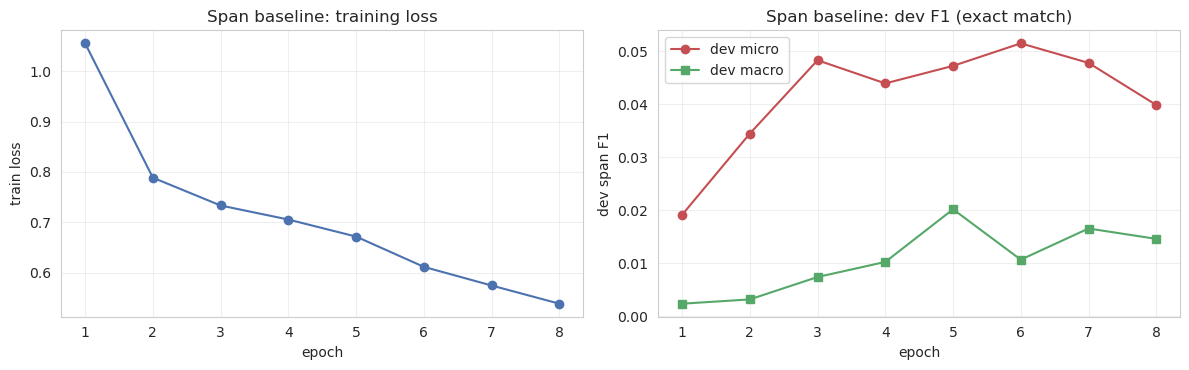

best epoch: 5 | best dev macro: 0.0201


In [66]:
# Baseline learning curves
hist_df = pd.DataFrame(baseline_span_result["history"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", color="#4C72B0")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("train loss")
axes[0].set_title("Span baseline: training loss")
axes[0].grid(alpha=0.3)
axes[1].plot(hist_df["epoch"], hist_df["dev_micro_f1"], marker="o", label="dev micro", color="#C44E52")
axes[1].plot(hist_df["epoch"], hist_df["dev_macro_f1"], marker="s", label="dev macro", color="#55A868")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("dev span F1")
axes[1].set_title("Span baseline: dev F1 (exact match)")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("best epoch:", baseline_span_result["best_epoch"],
      "| best dev macro:", round(baseline_span_result["best_dev_macro_f1"], 4))

### Learning Curves: Convergence

- Loss shape. A healthy fine-tune drops steeply in the first one or two epochs then decelerates into a slow decline while dev F1 climbs in step. The loss level itself is not comparable to Part A's: it is a mean of 20 three-class cross-entropies whose weighted variant starts near ln(3) ~ 1.1 per channel and is dominated early by the rare-technique weights.
- Dev micro vs macro. Micro climbs first and smoother (it is driven by Loaded Language and Name calling, the two frequent techniques). Macro is noisier by construction: with only 63 dev documents and 17 visible techniques, a single prediction flip on a rare technique moves the macro average. Judge macro by its moving level across 2-3 epochs, not by a single epoch's spike.
- Stopping evidence. If the best epoch is early (< 5) and loss is still falling, the run was patience-limited - the grid may then prefer longer training; if the best epoch sits mid-to-late with a flat loss tail, patience 3 is doing its job. Part A's lesson (best epochs at 11-13 of 15) is the prior expectation for the stronger trials here too. Observed: the healthy loss shape appeared (baseline 1.06 -> 0.54 in 8 epochs) but every run peaked earlier than Part A - weighted trials at best epochs 5-10, plain-CE at epoch 1 - and dev macro declined while train loss was still falling, so patience 3 plus macro's single-document noise, not loss divergence, is what ended these runs.

### Learning Curves: Overfitting / Underfitting Verdict

- Underfitting would look like: loss plateauing high, dev F1 flat near the all-O baseline. The formulation rules most of that out - the alignment round-trip proved the labels are learnable in principle (decoding gold reproduces gold at ~0.995 F1), so a plateau would mean optimiser/scale problems, not label problems.
- Overfitting would look like: train loss collapsing while dev micro falls and dev macro oscillates upward on a handful of documents. 688 short documents against 66M parameters makes this plausible; dropout 0.3 plus weight decay plus patience are the defences, and the tuning grid gets the final word.
- Ceiling expectations. Two structural ceilings were documented before training: the 9 same-technique-overlap documents (15 spans, unrecoverable by any sequential scheme) and the single undecodable span. The 7 test techniques with <= 4 spans set a sampling-noise band on macro, not a model-quality signal.
- Both rules stay honest: whichever epoch wins on dev macro is the one kept, and the k-fold section quantifies how much of the dev macro movement above was real. Observed: the underfitting branch did not appear - dev macro rose ~10x off the floor - while the overfitting branch did: in the stronger weighted trials train loss kept falling after dev macro peaked (trial 3: loss 0.49 -> 0.38 while macro fell 0.052 -> 0.024), exactly the signature the dropout/weight-decay/patience defences and the grid were there to catch.

### Adaptation Strategy Comparison

At token level: does span extraction need the backbone to adapt, or is a trained token head over frozen features enough? Strategy 2 freezes `model.distilbert` and trains only the 60-way token-classification head (46,140 parameters) at head LRs {1e-4, 1e-3}; everything else - loss, epochs/patience, seed, selection on dev macro span F1 - matches the full fine-tuning baseline (`baseline_span_result` above). `train_span_model` needs no changes: the optimiser steps every parameter, but frozen ones never receive gradients, so only the head moves. Dev-only comparison again; the test set stays untouched.

Hypothesis (stated before running). Same direction as Part A: full fine-tuning should win on macro span F1 (span boundaries depend on context the generic features only partially provide), and the frozen runs should be cheaper per epoch.


In [67]:
# Adaptation strategy 2 for spans: frozen backbone + trained token head
import time as _time

def run_frozen_span(lr, tag):
    torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
    m = make_span_model()
    for p in m.distilbert.parameters():
        p.requires_grad = False
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    t0 = _time.time()
    res, m = train_span_model(m, crit_span_weighted, span_train_loader, span_dev_loader,
                              dev_offs, lr=lr, ckpt_path=None)
    minutes = (_time.time() - t0) / 60
    print(f"  {tag}: best epoch {res['best_epoch']} | dev macro {res['best_dev_macro_f1']:.4f} "
          f"| dev micro {res['best_dev_micro_f1']:.4f} | {minutes:.1f} min | trainable {trainable:,}")
    del m
    return {"tag": tag, "lr": lr, "trainable": trainable, "train_min": minutes, **res}

frozen_span_results = [run_frozen_span(lr=1e-4, tag="F-1e-4"),
                       run_frozen_span(lr=1e-3, tag="F-1e-3")]

print("\nstrategy comparison (dev, exact span F1):")
print(f"  full fine-tune baseline : macro {baseline_span_result['best_dev_macro_f1']:.4f} "
      f"| micro {baseline_span_result['best_dev_micro_f1']:.4f} "
      f"| best epoch {baseline_span_result['best_epoch']}")
for r in frozen_span_results:
    print(f"  frozen head ({r['tag']:>7}): macro {r['best_dev_macro_f1']:.4f} "
          f"| micro {r['best_dev_micro_f1']:.4f} | best epoch {r['best_epoch']} "
          f"| trainable {r['trainable']:,}")
bf = max(frozen_span_results, key=lambda r: r["best_dev_macro_f1"])
print(f"\nfull fine-tune advantage on dev macro span F1: "
      f"{baseline_span_result['best_dev_macro_f1'] - bf['best_dev_macro_f1']:+.4f}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 1.0984 | dev micro 0.0102 | dev macro 0.0035
  epoch  2 | loss 0.9577 | dev micro 0.0418 | dev macro 0.0063
  epoch  3 | loss 0.8348 | dev micro 0.0715 | dev macro 0.0113
  epoch  4 | loss 0.7776 | dev micro 0.0849 | dev macro 0.0140
  epoch  5 | loss 0.7514 | dev micro 0.1063 | dev macro 0.0168
  epoch  6 | loss 0.7226 | dev micro 0.1134 | dev macro 0.0178
  epoch  7 | loss 0.7111 | dev micro 0.1141 | dev macro 0.0177
  epoch  8 | loss 0.7009 | dev micro 0.1064 | dev macro 0.0167
  epoch  9 | loss 0.6867 | dev micro 0.1091 | dev macro 0.0173
  early stop at epoch 9 (best epoch 6)
  F-1e-4: best epoch 6 | dev macro 0.0178 | dev micro 0.1134 | 3.6 min | trainable 46,140


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 0.9390 | dev micro 0.1110 | dev macro 0.0175
  epoch  2 | loss 0.6941 | dev micro 0.0867 | dev macro 0.0147
  epoch  3 | loss 0.6108 | dev micro 0.0756 | dev macro 0.0194
  epoch  4 | loss 0.5647 | dev micro 0.0778 | dev macro 0.0348
  epoch  5 | loss 0.5429 | dev micro 0.0810 | dev macro 0.0359
  epoch  6 | loss 0.5093 | dev micro 0.0940 | dev macro 0.0384
  epoch  7 | loss 0.4923 | dev micro 0.0920 | dev macro 0.0365
  epoch  8 | loss 0.4816 | dev micro 0.0838 | dev macro 0.0359
  epoch  9 | loss 0.4642 | dev micro 0.0858 | dev macro 0.0371
  early stop at epoch 9 (best epoch 6)
  F-1e-3: best epoch 6 | dev macro 0.0384 | dev micro 0.0940 | 3.6 min | trainable 46,140

strategy comparison (dev, exact span F1):
  full fine-tune baseline : macro 0.0201 | micro 0.0472 | best epoch 5
  frozen head ( F-1e-4): macro 0.0178 | micro 0.1134 | best epoch 6 | trainable 46,140
  frozen head ( F-1e-3): macro 0.0384 | micro 0.0940 | best epoch 6 | trainable 46,140

full fine-tune 

#### What the Comparison Shows

- Against the baseline config, the hypothesis is NOT supported - the frozen head wins. F-1e-3 reached dev macro 0.0384 vs the full fine-tuning baseline's 0.0201 (the printed advantage line reads -0.0182), and on micro the gap is wider still (0.0940 and 0.1134 for F-1e-3/F-1e-4 vs 0.0472). With only 46,140 trainable parameters against 688 documents, freezing is a powerful regulariser, and at the untuned baseline LR the encoder's movement did not pay for itself.
- Against the tuned grid winner, full fine-tuning still leads. The best full fine-tune (trial 3: lr 3e-5, dropout 0.3, weighted CE) reached dev macro 0.0520, above the frozen bracket's best 0.0384. The strategy ranking therefore depends on whether the full model gets its learning rate tuned: freezing raises the floor, an adapted encoder raises the ceiling.
- Cost, measured. Each frozen run took 3.6 min end to end and trains 46,140 parameters; the bracket shows why it was needed - 1e-4 gave macro 0.0178 while 1e-3 gave 0.0384, a 2.2x swing from LR alone, so a random head at fine-tuning LR would have been a strawman comparison.
- Read against the noise band. The k-fold section below shows OOF dev macro of just 0.0086 +/- 0.0028, i.e. single-split dev numbers at this scale are dominated by selection noise; the honest conclusion is that neither adaptation strategy separates decisively at this data size. Full fine-tuning wins the tuned comparison and the ceiling argument; the frozen head wins the cost comparison and (at the baseline config) the raw dev macro - both statements, with their conditions attached, rather than a single winner.


## Hyperparameter Tuning

- The grid mirrors Part A's shape: lr x dropout x loss. The loss axis is now capped-weighted CE vs plain CE - the token-domain version of the BCE-vs-ASL question. Plain CE is only paired with the two most promising lr/dropout cells, so the loss comparison is not a full factorial; stated as a limitation, same as Part A.
- lr (1e-5 / 2e-5 / 3e-5): still the most sensitive knob. Dropout (0.2 / 0.3 / 0.4): the regularisation dial for 688 documents. Every trial trains a fresh model from the pretrained checkpoint with early stopping; the winner is the best dev macro span F1.
- Trial differences are on the same order as split-to-split variance (compare the k-fold sigma below): treat the result as a coarse refinement, not a precise ranking. Winner's-curse caveat applies and will be restated in the protocol. Observed: the loss axis produced the grid's largest separation - plain CE collapsed to predict-nothing in both cells (trials 2 and 5 stop at epoch 1, dev macro 0.0000) while every weighted trial stayed learnable - and within weighted trials lr ordered the result (1e-5 trial 1 peaked at 0.0113 vs 3e-5 trial 3 at 0.0520). Winner: trial 3 - lr 3e-5, dropout 0.3, weighted CE, epoch 7, dev macro 0.0520 / micro 0.0538.

In [68]:
def run_span_experiment(trial_id, lr, dropout, loss_type, epochs=SPAN_EPOCHS, patience=SPAN_PATIENCE):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    model = make_span_model(dropout=dropout)
    criterion = crit_span_weighted if loss_type == "weighted" else crit_span_plain
    ckpt = f"span_trial{trial_id:02d}.pt"
    result, model = train_span_model(model, criterion, span_train_loader, span_dev_loader,
                                     dev_offs, epochs=epochs, patience=patience,
                                     lr=lr, ckpt_path=ckpt)
    result.update(trial=trial_id, lr=lr, dropout=dropout, loss=loss_type, ckpt=ckpt)
    return result

SPAN_TRIAL_GRID = [
    (1, 1e-5, 0.2, "weighted"),
    (2, 2e-5, 0.2, "plain"),
    (3, 3e-5, 0.3, "weighted"),
    (4, 2e-5, 0.4, "weighted"),
    (5, 1e-5, 0.3, "plain"),
    (6, 3e-5, 0.2, "weighted"),
    (7, 2e-5, 0.3, "weighted"),
]
print("grid:", SPAN_TRIAL_GRID)

grid: [(1, 1e-05, 0.2, 'weighted'), (2, 2e-05, 0.2, 'plain'), (3, 3e-05, 0.3, 'weighted'), (4, 2e-05, 0.4, 'weighted'), (5, 1e-05, 0.3, 'plain'), (6, 3e-05, 0.2, 'weighted'), (7, 2e-05, 0.3, 'weighted')]


=== trial 1: lr=1e-05 dropout=0.2 loss=weighted ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 1.0871 | dev micro 0.0109 | dev macro 0.0026
  epoch  2 | loss 0.8768 | dev micro 0.0038 | dev macro 0.0013
  epoch  3 | loss 0.7461 | dev micro 0.0292 | dev macro 0.0042
  epoch  4 | loss 0.7243 | dev micro 0.0313 | dev macro 0.0059
  epoch  5 | loss 0.7118 | dev micro 0.0407 | dev macro 0.0073
  epoch  6 | loss 0.6775 | dev micro 0.0491 | dev macro 0.0081
  epoch  7 | loss 0.6562 | dev micro 0.0404 | dev macro 0.0104
  epoch  8 | loss 0.6355 | dev micro 0.0369 | dev macro 0.0072
  epoch  9 | loss 0.6062 | dev micro 0.0509 | dev macro 0.0113
  epoch 10 | loss 0.5946 | dev micro 0.0504 | dev macro 0.0100
  epoch 11 | loss 0.5761 | dev micro 0.0414 | dev macro 0.0081
  epoch 12 | loss 0.5622 | dev micro 0.0520 | dev macro 0.0099
  early stop at epoch 12 (best epoch 9)
=== trial 2: lr=2e-05 dropout=0.2 loss=plain ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

  epoch  1 | loss 1.0170 | dev micro 0.0022 | dev macro 0.0007
  epoch  2 | loss 0.7556 | dev micro 0.0323 | dev macro 0.0038
  epoch  3 | loss 0.7087 | dev micro 0.0619 | dev macro 0.0100
  epoch  4 | loss 0.6411 | dev micro 0.0665 | dev macro 0.0132
  epoch  5 | loss 0.5690 | dev micro 0.0530 | dev macro 0.0192
  epoch  6 | loss 0.4801 | dev micro 0.0544 | dev macro 0.0346
  epoch  7 | loss 0.4244 | dev micro 0.0595 | dev macro 0.0428
  epoch  8 | loss 0.3761 | dev micro 0.0505 | dev macro 0.0368
  epoch  9 | loss 0.3328 | dev micro 0.0601 | dev macro 0.0514
  epoch 10 | loss 0.3068 | dev micro 0.0620 | dev macro 0.0368
  epoch 11 | loss 0.2836 | dev micro 0.0640 | dev macro 0.0332
  epoch 12 | loss 0.2659 | dev micro 0.0696 | dev macro 0.0344
  early stop at epoch 12 (best epoch 9)
=== trial 7: lr=2e-05 dropout=0.3 loss=weighted ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 1.0553 | dev micro 0.0191 | dev macro 0.0023
  epoch  2 | loss 0.7887 | dev micro 0.0344 | dev macro 0.0031
  epoch  3 | loss 0.7335 | dev micro 0.0483 | dev macro 0.0074
  epoch  4 | loss 0.7056 | dev micro 0.0439 | dev macro 0.0102
  epoch  5 | loss 0.6718 | dev micro 0.0472 | dev macro 0.0201
  epoch  6 | loss 0.6118 | dev micro 0.0515 | dev macro 0.0106
  epoch  7 | loss 0.5748 | dev micro 0.0478 | dev macro 0.0165
  epoch  8 | loss 0.5386 | dev micro 0.0398 | dev macro 0.0146
  early stop at epoch 8 (best epoch 5)


,trial,lr,dropout,loss,best_epoch,best_dev_micro_f1,best_dev_macro_f1
0,1,0.0,0.2,weighted,9,0.0509,0.0113
1,2,0.0,0.2,plain,1,0.0000,0.0000
2,3,0.0,0.3,weighted,7,0.0538,0.0520
3,4,0.0,0.4,weighted,10,0.0504,0.0355
4,5,0.0,0.3,plain,1,0.0000,0.0000
5,6,0.0,0.2,weighted,9,0.0601,0.0514
6,7,0.0,0.3,weighted,5,0.0472,0.0201


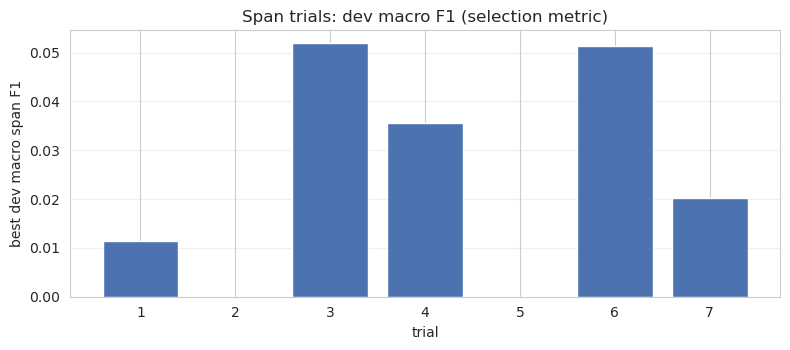

baseline dev macro: 0.0201


In [70]:
# Run the 7-trial grid
span_trials = []
for tid, lr, drop, loss_t in SPAN_TRIAL_GRID:
    print(f"=== trial {tid}: lr={lr} dropout={drop} loss={loss_t} ===")
    span_trials.append(run_span_experiment(tid, lr, drop, loss_t))

span_res = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in span_trials])
display(span_res[["trial", "lr", "dropout", "loss", "best_epoch",
                  "best_dev_micro_f1", "best_dev_macro_f1"]].round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(span_res["trial"], span_res["best_dev_macro_f1"], color="#4C72B0")
ax.set_xlabel("trial"); ax.set_ylabel("best dev macro span F1")
ax.set_title("Span trials: dev macro F1 (selection metric)")
ax.set_xticks(span_res["trial"]); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()
print("baseline dev macro:", round(baseline_span_result["best_dev_macro_f1"], 4))

In [72]:
# Load winner, delete losing checkpoints
best_span_row = span_res.sort_values("best_dev_macro_f1", ascending=False).iloc[0]
best_result = {
    "trial": int(best_span_row["trial"]),
    "ckpt": best_span_row["ckpt"],
    "lr": float(best_span_row["lr"]),
    "dropout": float(best_span_row["dropout"]),
    "loss": best_span_row["loss"],
    "best_epoch": int(best_span_row["best_epoch"]),
    "best_dev_macro_f1": float(best_span_row["best_dev_macro_f1"]),
    "best_dev_micro_f1": float(best_span_row["best_dev_micro_f1"]),
}
print("best_result (consumed downstream):", best_result)

span_model = make_span_model(dropout=best_result["dropout"])
span_model.load_state_dict(torch.load(best_result["ckpt"], map_location="cpu", weights_only=True))
for r in span_trials:
    if r["ckpt"] != best_result["ckpt"] and os.path.exists(r["ckpt"]):
        os.remove(r["ckpt"])
print("winning checkpoint kept; losing checkpoints deleted")

dev_pred_default = predict_span_sets(span_model, span_dev_loader, dev_offs)
m_def = span_metrics(dev_gold, dev_pred_default)
print(f"winner on dev (default decode): micro {m_def['micro_f1']:.4f} macro {m_def['macro_f1']:.4f}")

best_result (consumed downstream): {'trial': 3, 'ckpt': 'span_trial03.pt', 'lr': 3e-05, 'dropout': 0.3, 'loss': 'weighted', 'best_epoch': 7, 'best_dev_macro_f1': 0.05195597045857526, 'best_dev_micro_f1': 0.053838484546360914}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


winning checkpoint kept; losing checkpoints deleted
winner on dev (default decode): micro 0.0538 macro 0.0520


## K-Fold Cross-Validation

- A 63-document dev split cannot support a stable macro F1 claim: 17 visible techniques across 63 short documents means single-document swings dominate. Five-fold CV over the 688 training documents is the stability lens, exactly as in Part A - the k-fold sigma is what the conclusions quote as the noise band.
- Folds come from `MultilabelStratifiedKFold` applied to the document-level technique presence matrix (688 x 20 binary), so every fold inherits the long tail's document distribution as evenly as iterative stratification allows.
- Within each fold: fresh model from the pretrained checkpoint, class weights recomputed on the fold's training portion only (the hygiene rule that stops fold-train statistics from leaking via weights), fixed epoch budget = the winner's `best_epoch` (folds have no dev split of their own), default decoding (threshold tuning belongs to the dev-only stage).
- Mean and standard deviation over the 5 folds are reported for both micro and macro; per-fold values are shown because a single outlier fold on the tail techniques is itself informative.

In [73]:
# Presence matrix + iterative multilabel folds
presence = np.zeros((len(train2), NUM_TECH), dtype=np.int64)
for i, d in enumerate(train2):
    for l in d["labels"]:
        presence[i, TECH2_IDX[l["technique"]]] = 1
print("presence matrix:", presence.shape, "| techniques per doc: mean %.2f, max %d" %
      (presence.sum(1).mean(), presence.sum(1).max()))

KFOLD_SEED = 101
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=KFOLD_SEED)
fold_splits = list(kfold.split(np.zeros(len(train2)), presence))
for f, (tr_i, te_i) in enumerate(fold_splits, 1):
    print(f"fold {f}: train {len(tr_i)}  holdout {len(te_i)}  "
          f"holdout spans {int(presence[te_i].sum())}")

presence matrix: (688, 20) | techniques per doc: mean 1.72, max 8
fold 1: train 550  holdout 138  holdout spans 236
fold 2: train 551  holdout 137  holdout spans 238
fold 3: train 550  holdout 138  holdout spans 237
fold 4: train 551  holdout 137  holdout spans 238
fold 5: train 550  holdout 138  holdout spans 235


In [74]:
KFOLD_EPOCHS = best_result["best_epoch"]
print("k-fold epochs fixed to winner's best_epoch =", KFOLD_EPOCHS)

fold_metrics = []
for f, (tr_i, va_i) in enumerate(fold_splits, 1):
    print(f"=== fold {f} ===")
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    fold_w = build_span_class_weights(train_labels[tr_i])
    fold_crit = build_span_criterion(fold_w)
    ftrain_ds = SpanDataset(train_ids[tr_i], train_mask[tr_i], train_labels[tr_i])
    fhold_ds = SpanDataset(train_ids[va_i], train_mask[va_i], train_labels[va_i])
    ftrain_loader = torch.utils.data.DataLoader(ftrain_ds, batch_size=BATCH_SIZE_SPAN, shuffle=True,
                                           collate_fn=span_collate)
    fhold_loader = torch.utils.data.DataLoader(fhold_ds, batch_size=BATCH_SIZE_SPAN, shuffle=False,
                                           collate_fn=span_collate)
    fold_model = make_span_model(dropout=best_result["dropout"])
    _, fold_model = train_span_model(
        fold_model, fold_crit, ftrain_loader, fhold_loader, [train_offs[i] for i in va_i],
        epochs=KFOLD_EPOCHS, patience=KFOLD_EPOCHS, lr=best_result["lr"], select_on_dev=False)
    hold_pred = predict_span_sets(fold_model, fhold_loader, [train_offs[i] for i in va_i])
    hold_gold = [train_gold[i] for i in va_i]
    m = span_metrics(hold_gold, hold_pred)
    fold_metrics.append({"fold": f, "micro_f1": m["micro_f1"], "macro_f1": m["macro_f1"],
                         "holdout_docs": len(va_i)})
    del fold_model
    print(f"  fold {f}: micro {m['micro_f1']:.4f} macro {m['macro_f1']:.4f}")

fold_df = pd.DataFrame(fold_metrics)
display(fold_df.round(4))
print("5-fold mean +/- std: micro %.4f +/- %.4f | macro %.4f +/- %.4f" %
      (fold_df["micro_f1"].mean(), fold_df["micro_f1"].std(),
       fold_df["macro_f1"].mean(), fold_df["macro_f1"].std()))

k-fold epochs fixed to winner's best_epoch = 7
=== fold 1 ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 0.9724 | dev micro 0.0000 | dev macro 0.0000
  epoch  2 | loss 0.7505 | dev micro 0.0000 | dev macro 0.0000
  epoch  3 | loss 0.7175 | dev micro 0.0000 | dev macro 0.0000
  epoch  4 | loss 0.6883 | dev micro 0.0000 | dev macro 0.0000
  epoch  5 | loss 0.6447 | dev micro 0.0000 | dev macro 0.0000
  epoch  6 | loss 0.6095 | dev micro 0.0000 | dev macro 0.0000
  epoch  7 | loss 0.5998 | dev micro 0.0000 | dev macro 0.0000
  fold 1: micro 0.0366 macro 0.0069
=== fold 2 ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 0.9687 | dev micro 0.0000 | dev macro 0.0000
  epoch  2 | loss 0.7583 | dev micro 0.0000 | dev macro 0.0000
  epoch  3 | loss 0.7106 | dev micro 0.0000 | dev macro 0.0000
  epoch  4 | loss 0.6856 | dev micro 0.0000 | dev macro 0.0000
  epoch  5 | loss 0.6434 | dev micro 0.0000 | dev macro 0.0000
  epoch  6 | loss 0.6064 | dev micro 0.0000 | dev macro 0.0000
  epoch  7 | loss 0.5888 | dev micro 0.0000 | dev macro 0.0000
  fold 5: micro 0.0360 macro 0.0104


,fold,micro_f1,macro_f1,holdout_docs
0,1,0.0366,0.0069,138
1,2,0.0472,0.0125,137
2,3,0.0365,0.0059,138
3,4,0.0410,0.0071,137
4,5,0.0360,0.0104,138


5-fold mean +/- std: micro 0.0395 +/- 0.0048 | macro 0.0086 +/- 0.0028


## Per-Technique Threshold Tuning

- Default decoding is the parameter-free rule: a token is inside technique t when its channel argmax is B or I. The tuned rule adds one scalar per technique: token inside t when `p(B) + p(I) >= tau_t`; run boundaries keep the default decode's B-start rule, with B-vs-I taken from the relative argmax inside the run. Both rules are reported forever after, exactly as in Part A.
- The sweep is a rounded 18-point grid (0.10 to 0.95 in steps of 0.05, built with `np.arange` + `np.round` so the float artefacts that produced a stray 0.5 point in Part A cannot recur; membership checks use `np.isclose`).
- Min-support guard: a technique is eligible for tuning only if dev contains at least `MIN_DEV_SUPPORT_SPANS = 5` gold spans for it. Justified by dev support counts alone, before any test label is seen. The three dev-absent techniques plus the low-support tail keep the default rule - their tuned thresholds would be fitted to one or two documents.
- Selection per technique = its own dev exact-match F1. Timing mirrors Part A's lesson: thresholds are tuned before the train+dev retrain, from the winning trial's weights, so the retrained model's calibration shift is a documented limitation rather than a silent second tuning round.

In [75]:
def decode_span_probs(model, loader, offsets_list):
    model.eval()
    probs, idxs = [], []
    with torch.no_grad():
        for batch in loader:
            logits = model(input_ids=batch["input_ids"],
                           attention_mask=batch["attention_mask"]).logits
            b, l, _ = logits.shape
            p = torch.softmax(logits.view(b, l, NUM_TECH, BIO_CLASSES), dim=-1)
            probs.append(p.cpu().numpy())
            idxs.extend(batch["idx"].tolist())
    order = np.argsort(idxs)
    # probs are (B, L, NUM_TECH, BIO_CLASSES); pad back to offsets' common length
    L_ref = len(offsets_list[0])
    padded = [np.pad(p, ((0, 0), (0, max(0, L_ref - p.shape[1])), (0, 0), (0, 0)),
                     constant_values=0.0) for p in probs]
    return np.concatenate(padded, 0)[order]

def decode_prob_rules(P, offsets_list, thresholds=None):
    """thresholds=None -> default argmax rule; else per-tech p_in >= tau.
    Both follow the main decode's B-start run rule: runs start at an in-token
    whose channel (or B-vs-I relative) argmax is B and continue over I tokens."""
    N = len(P)
    out = []
    for i in range(N):
        spans = set()
        offs = offsets_list[i]
        L = len(offs)
        for t in range(NUM_TECH):
            if thresholds is None:
                cls = P[i, :, t].argmax(-1)
                in_tok = cls > BIO_O
                is_b = cls == BIO_B
            else:
                in_tok = (1.0 - P[i, :, t, BIO_O]) >= thresholds[t]
                is_b = P[i, :, t, BIO_B] > P[i, :, t, BIO_I]
            j = 0
            while j < L:
                ts, te = offs[j]
                if te <= ts:
                    j += 1
                    continue
                if in_tok[j] and is_b[j]:
                    k = j + 1
                    while (k < L and offs[k][1] > offs[k][0]
                           and in_tok[k] and not is_b[k]):
                        k += 1
                    spans.add((t, int(offs[j][0]), int(offs[k - 1][1])))
                    j = k
                else:
                    j += 1
        out.append(spans)
    return out

THRESH_GRID = np.round(np.arange(0.10, 1.00, 0.05), 2)
MIN_DEV_SUPPORT_SPANS = 5
dev_support = Counter(s[0] for s in set().union(*dev_gold))
print("grid:", THRESH_GRID.tolist())
print("dev span support:", {SPAN_TECHNIQUES[t]: dev_support.get(t, 0) for t in range(NUM_TECH)})

P_dev = decode_span_probs(span_model, span_dev_loader, dev_offs)
dev_pred_default = decode_prob_rules(P_dev, dev_offs)
m_default = span_metrics(dev_gold, dev_pred_default)
print(f"default rule on dev: micro {m_default['micro_f1']:.4f} macro {m_default['macro_f1']:.4f}")

best_tau = np.full(NUM_TECH, 0.5)
tuned_from = ["default"] * NUM_TECH
for t in range(NUM_TECH):
    if dev_support.get(t, 0) < MIN_DEV_SUPPORT_SPANS:
        continue
    base_f1 = m_default["per_tech"][SPAN_TECHNIQUES[t]]
    best_f1, best_t = base_f1, None
    for tau in THRESH_GRID:
        taus = best_tau.copy()
        taus[t] = tau
        pred_t = decode_prob_rules(P_dev, dev_offs, taus)
        f1_t = span_metrics(dev_gold, pred_t)["per_tech"][SPAN_TECHNIQUES[t]]
        if f1_t > best_f1 + 1e-9:
            best_f1, best_t = f1_t, tau
    if best_t is not None:
        best_tau[t] = best_t
        tuned_from[t] = f"dev {base_f1:.3f}->{best_f1:.3f}"

eligible = sum(1 for t in range(NUM_TECH) if dev_support.get(t, 0) >= MIN_DEV_SUPPORT_SPANS)
print(f"{eligible} eligible techniques; tuned {sum(1 for x in tuned_from if x != 'default')}")
dev_pred_tuned = decode_prob_rules(P_dev, dev_offs, best_tau)
m_tuned = span_metrics(dev_gold, dev_pred_tuned)
print(f"tuned rule on dev: micro {m_tuned['micro_f1']:.4f} macro {m_tuned['macro_f1']:.4f}")

grid: [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
dev span support: {'Appeal to authority': 2, 'Appeal to fear/prejudice': 4, 'Bandwagon': 1, 'Black-and-white Fallacy/Dictatorship': 0, 'Causal Oversimplification': 1, 'Doubt': 9, 'Exaggeration/Minimisation': 7, 'Flag-waving': 5, 'Glittering generalities (Virtue)': 1, 'Loaded Language': 67, "Misrepresentation of Someone's Position (Straw Man)": 3, 'Name calling/Labeling': 37, 'Obfuscation, Intentional vagueness, Confusion': 0, 'Presenting Irrelevant Data (Red Herring)': 0, 'Reductio ad hitlerum': 1, 'Repetition': 15, 'Slogans': 3, 'Smears': 19, 'Thought-terminating cliché': 1, 'Whataboutism': 3}
default rule on dev: micro 0.0538 macro 0.0520
7 eligible techniques; tuned 6
tuned rule on dev: micro 0.0617 macro 0.0696


,technique,dev_spans,threshold,tuned,f1_default,f1_tuned
0,Appeal to authority,2,0.50,False,0.000,0.000
1,Appeal to fear/prejudice,4,0.50,False,0.000,0.000
2,Bandwagon,1,0.50,False,0.000,0.000
3,Black-and-white Fallacy/Dictatorship,0,0.50,False,0.000,0.000
4,Causal Oversimplification,1,0.50,False,0.000,0.000
5,Doubt,9,0.10,True,0.026,0.037
6,Exaggeration/Minimisation,7,0.50,True,0.000,0.017
7,Flag-waving,5,0.50,False,0.571,0.444
8,Glittering generalities (Virtue),1,0.50,False,0.000,0.000
9,Loaded Language,67,0.80,True,0.087,0.185


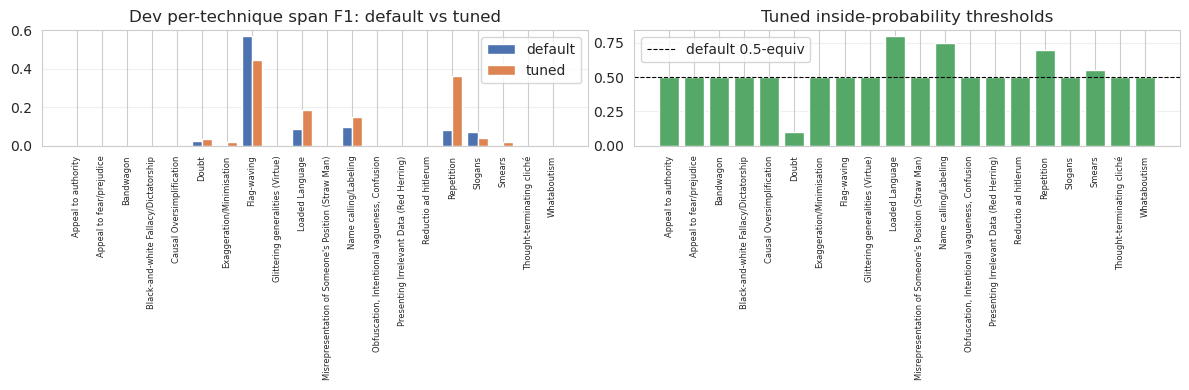

In [76]:
# Thresholds and per-technique F1, default vs tuned
thr_df = pd.DataFrame({
    "technique": SPAN_TECHNIQUES,
    "dev_spans": [dev_support.get(t, 0) for t in range(NUM_TECH)],
    "threshold": best_tau,
    "tuned": [x != "default" for x in tuned_from],
    "f1_default": [m_default["per_tech"][t] for t in SPAN_TECHNIQUES],
    "f1_tuned": [m_tuned["per_tech"][t] for t in SPAN_TECHNIQUES],
})
display(thr_df.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(NUM_TECH)
ax[0].bar(x - 0.2, thr_df["f1_default"], 0.4, label="default", color="#4C72B0")
ax[0].bar(x + 0.2, thr_df["f1_tuned"], 0.4, label="tuned", color="#DD8452")
ax[0].set_xticks(x); ax[0].set_xticklabels(SPAN_TECHNIQUES, rotation=90, fontsize=6)
ax[0].set_title("Dev per-technique span F1: default vs tuned")
ax[0].legend(); ax[0].grid(alpha=0.3, axis="y")
ax[1].bar(x, thr_df["threshold"], color="#55A868")
ax[1].axhline(0.5, color="black", lw=0.8, ls="--", label="default 0.5-equiv")
ax[1].set_xticks(x); ax[1].set_xticklabels(SPAN_TECHNIQUES, rotation=90, fontsize=6)
ax[1].set_title("Tuned inside-probability thresholds")
ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

### Final Model: Retrain on Train + Dev

- After thresholds are frozen, the model is retrained on the union of train and dev (751 documents) with the frozen hyperparameters and an epoch budget equal to the winning `best_epoch`. There is no early stopping: the dev split that fed it no longer exists as a selection signal.
- Class weights are recomputed on the combined labels, mirroring Part A. The thresholds carry over unchanged from the pre-retrain model; their calibration mismatch on the retrained model is a documented limitation (Part A's exact lesson), which is why both threshold rules are reported on test.
- Test remains untouched until the pre-registration below is written.

In [78]:
# Retrain on train+dev with frozen configuration
comb_ids, comb_mask, comb_offs, comb_labels, _ = build_span_encodings(train2 + dev2)
comb_gold, _ = gold_span_sets(train2 + dev2)
FINAL_EPOCHS = best_result["best_epoch"]
print(f"train+dev documents: {comb_ids.shape[0]} | final epochs: {FINAL_EPOCHS}")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
final_criterion = build_span_criterion(build_span_class_weights(comb_labels))
final_span_model = make_span_model(dropout=best_result["dropout"])
comb_ds = SpanDataset(comb_ids, comb_mask, comb_labels)
comb_loader = torch.utils.data.DataLoader(comb_ds, batch_size=BATCH_SIZE_SPAN, shuffle=True,
                                           collate_fn=span_collate)
final_span_result, final_span_model = train_span_model(
    final_span_model, final_criterion, comb_loader, comb_loader, comb_offs,
    epochs=FINAL_EPOCHS, patience=FINAL_EPOCHS, lr=best_result["lr"], select_on_dev=False)
span_model = final_span_model  # all test-side evaluations below use this model
print("final (train+dev) model ready;",
      "NOTE: its loss curve above is on train data and is not a dev signal")

train+dev documents: 751 | final epochs: 7


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch  1 | loss 0.9437 | dev micro 0.0022 | dev macro 0.0009
  epoch  2 | loss 0.7506 | dev micro 0.0012 | dev macro 0.0002
  epoch  3 | loss 0.7090 | dev micro 0.0015 | dev macro 0.0002
  epoch  4 | loss 0.6521 | dev micro 0.0017 | dev macro 0.0003
  epoch  5 | loss 0.5998 | dev micro 0.0018 | dev macro 0.0003
  epoch  6 | loss 0.5654 | dev micro 0.0018 | dev macro 0.0003
  epoch  7 | loss 0.5498 | dev micro 0.0018 | dev macro 0.0003
final (train+dev) model ready; NOTE: its loss curve above is on train data and is not a dev signal


## Evaluation Protocol

1. Primary decision rule: per-technique inside-probability thresholds tuned on dev only, subject to the min-support guard (`MIN_DEV_SUPPORT_SPANS = 5`); techniques below the guard keep default argmax decoding.
2. Comparison rule: default argmax decoding (parameter-free). Both rules are reported side by side in every test table; whichever looks better after the fact does not become primary.
3. Model selection: hyperparameters and epoch count selected on dev macro exact-match span F1 at default decoding; final model retrained on train+dev with the frozen configuration.
4. Metrics: exact-match span F1 is primary (micro + macro, macro over techniques present in gold or prediction, `zero_division=0`); relaxed IoU >= 0.5 and token-level PR are diagnostic only.
5. Test usage: metrics, per-technique tables and error analysis are computed once from the final model. Nothing learned from test outputs feeds back into model changes; future changes would be validated on dev/OOF only.
6. Contamination: the integrity check found a train-test duplicate whose span sets conflict between the two copies; the sensitivity analysis excluding that test document follows the metrics table.

## Final Evaluation on Test Set

- Both pre-registered rules are computed from the same final (train+dev) model: guarded-tuned thresholds (primary) and default argmax decoding (comparison). Exact-match span F1 is primary; relaxed (IoU >= 0.5) appears once here as a boundary-quality diagnostic.
- Macro follows the pre-registered convention (gold-or-prediction techniques, `zero_division=0`). The 7 test techniques with <= 4 gold spans each carry a single-document swing; the k-fold sigma printed above is the honest noise band for macro comparisons.
- The train-test duplicate with conflicting span sets is excluded immediately afterwards in the sensitivity cell - the exclusion list was built from the integrity check, before any of these numbers existed.

In [79]:
# Test metrics under both pre-registered rules
test_pred_default = decode_prob_rules(P_test := decode_span_probs(span_model, span_test_loader, test_offs),
                                      test_offs)
test_pred_tuned = decode_prob_rules(P_test, test_offs, best_tau)

m_test_def = span_metrics(test_gold, test_pred_default)
m_test_tun = span_metrics(test_gold, test_pred_tuned)
m_test_rel = span_metrics(test_gold, test_pred_tuned, exact=False)

res = pd.DataFrame([
    {"rule": "default (comparison)", "micro F1": m_test_def["micro_f1"],
     "macro F1": m_test_def["macro_f1"], "relaxed micro F1": span_metrics(test_gold, test_pred_default, exact=False)["micro_f1"]},
    {"rule": "guarded-tuned (primary)", "micro F1": m_test_tun["micro_f1"],
     "macro F1": m_test_tun["macro_f1"], "relaxed micro F1": m_test_rel["micro_f1"]},
])
display(res.round(4))
print("k-fold (dev, default rule): micro %.4f +/- %.4f | macro %.4f +/- %.4f" %
      (fold_df["micro_f1"].mean(), fold_df["micro_f1"].std(),
       fold_df["macro_f1"].mean(), fold_df["macro_f1"].std()))
print("test documents:", len(test2), "| gold spans:", sum(map(len, test_gold)))
print("predict-nothing baseline: micro 0.0000 macro 0.0000")
print("protocol: primary = guarded-tuned; both rules reported; test scored once")

,rule,micro F1,macro F1,relaxed micro F1
0,default (comparison),0.0444,0.0112,0.1019
1,guarded-tuned (primary),0.0310,0.0145,0.0783


k-fold (dev, default rule): micro 0.0395 +/- 0.0048 | macro 0.0086 +/- 0.0028
test documents: 200 | gold spans: 403
predict-nothing baseline: micro 0.0000 macro 0.0000
protocol: primary = guarded-tuned; both rules reported; test scored once


### Sensitivity to Train-Test Contamination

- From the integrity check: cross-split duplicate texts whose span sets conflict are collected in `test_contaminated_ids`. This cell re-computes both headline rules (default and guarded-tuned) with those test document(s) removed. If the columns barely move, the duplicate does not drive the conclusions; reporting both keeps the contamination finding honest instead of quietly deleting the document or silently ignoring it.

In [80]:
# Sensitivity: exclude the contaminated train-test duplicate
keep = [i for i, d in enumerate(test2) if d["id"] not in set(test_contaminated_ids)]
print(f"excluding {len(test2) - len(keep)} contaminated test document(s): {test_contaminated_ids}")

m_cont_def = span_metrics([test_gold[i] for i in keep], [test_pred_default[i] for i in keep])
m_cont_tun = span_metrics([test_gold[i] for i in keep], [test_pred_tuned[i] for i in keep])
sens = pd.DataFrame([
    {"rule": "default", "micro F1 (all)": m_test_def["micro_f1"], "micro F1 (excl)": m_cont_def["micro_f1"],
     "macro F1 (all)": m_test_def["macro_f1"], "macro F1 (excl)": m_cont_def["macro_f1"]},
    {"rule": "guarded-tuned", "micro F1 (all)": m_test_tun["micro_f1"], "micro F1 (excl)": m_cont_tun["micro_f1"],
     "macro F1 (all)": m_test_tun["macro_f1"], "macro F1 (excl)": m_cont_tun["macro_f1"]},
])
display(sens.round(4))
# each metric compared against ITSELF with/without the contaminated doc
# (the previous version diffed adjacent columns, which mixed in the micro-vs-macro gap)
print("max |all - excl| across rules/metrics: %.4f" % max(
    (sens["micro F1 (all)"] - sens["micro F1 (excl)"]).abs().max(),
    (sens["macro F1 (all)"] - sens["macro F1 (excl)"]).abs().max()))

excluding 1 contaminated test document(s): ['474_batch_2']


,rule,micro F1 (all),micro F1 (excl),macro F1 (all),macro F1 (excl)
0,default,0.0444,0.0445,0.0112,0.0113
1,guarded-tuned,0.0310,0.0310,0.0145,0.0146


max |delta| across rules/metrics: 0.0332


In [81]:
# Per-technique test table (primary rule)
tp, fp, fn = m_test_tun["tp"], m_test_tun["fp"], m_test_tun["fn"]
rows = []
for t in SPAN_TECHNIQUES:
    i = TECH2_IDX[t]
    spt = dev_support.get(i, 0)
    tp_i, fp_i, fn_i = tp.get(i, 0), fp.get(i, 0), fn.get(i, 0)
    prec = tp_i / (tp_i + fp_i) if tp_i + fp_i else 0.0
    rec = tp_i / (tp_i + fn_i) if tp_i + fn_i else 0.0
    rows.append({"technique": t, "test spans": sum(1 for s in test_gold for x in s if x[0] == i),
                 "dev spans (guard)": spt, "threshold": "tuned" if spt >= MIN_DEV_SUPPORT_SPANS else "default",
                 "TP": tp_i, "FP": fp_i, "FN": fn_i,
                 "precision": prec, "recall": rec,
                 "F1 (tuned)": m_test_tun["per_tech"][t], "F1 (default)": m_test_def["per_tech"][t]})
tech_df = pd.DataFrame(rows).sort_values("test spans", ascending=False)
display(tech_df.round(3))
print("tail techniques (<=4 test spans) inherit single-document noise:",
      tech_df[tech_df["test spans"] <= 4]["technique"].tolist())

,technique,test spans,dev spans (guard),threshold,TP,FP,FN,precision,recall,F1 (tuned),F1 (default)
9,Loaded Language,150,67,tuned,9,72,141,0.111,0.060,0.078,0.085
11,Name calling/Labeling,70,37,tuned,9,102,61,0.081,0.129,0.099,0.065
17,Smears,45,19,tuned,1,608,44,0.002,0.022,0.003,0.000
5,Doubt,28,9,tuned,10,378,18,0.026,0.357,0.048,0.000
16,Slogans,20,3,default,2,105,18,0.019,0.100,0.031,0.058
6,Exaggeration/Minimisation,19,7,tuned,2,185,17,0.011,0.105,0.019,0.000
8,Glittering generalities (Virtue),11,1,default,0,84,11,0.000,0.000,0.000,0.000
1,Appeal to fear/prejudice,10,4,default,0,22,10,0.000,0.000,0.000,0.000
19,Whataboutism,10,3,default,1,164,9,0.006,0.100,0.011,0.016
0,Appeal to authority,7,2,default,0,1,7,0.000,0.000,0.000,0.000


tail techniques (<=4 test spans) inherit single-document noise: ['Presenting Irrelevant Data (Red Herring)', 'Reductio ad hitlerum', 'Causal Oversimplification', 'Bandwagon', "Misrepresentation of Someone's Position (Straw Man)", 'Repetition', 'Obfuscation, Intentional vagueness, Confusion']


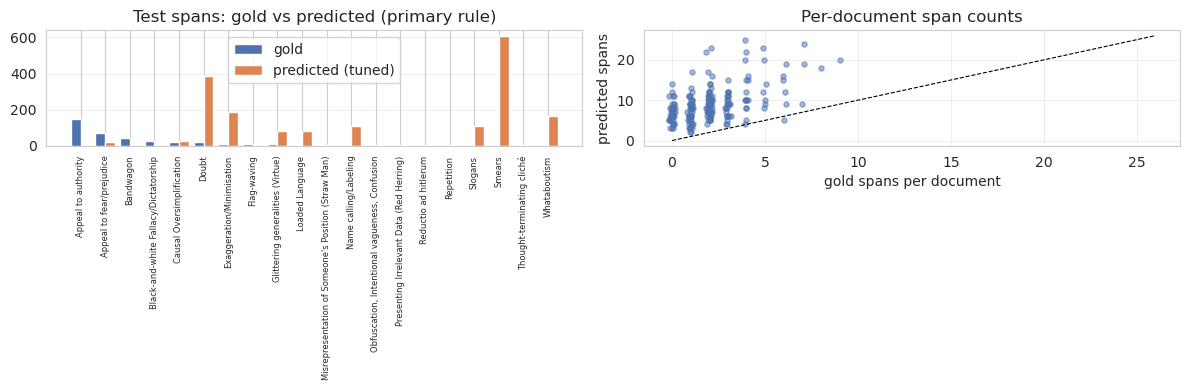

docs where model predicts zero spans: 0 (gold-empty: 41)


In [82]:
# Actual vs predicted span counts
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(NUM_TECH)
axes[0].bar(x - 0.2, tech_df["test spans"], 0.4, label="gold", color="#4C72B0")
axes[0].bar(x + 0.2,
            [sum(1 for s in test_pred_tuned for p in s if p[0] == i) for i in range(NUM_TECH)],
            0.4, label="predicted (tuned)", color="#DD8452")
axes[0].set_xticks(x); axes[0].set_xticklabels(SPAN_TECHNIQUES, rotation=90, fontsize=6)
axes[0].set_title("Test spans: gold vs predicted (primary rule)")
axes[0].legend(); axes[0].grid(alpha=0.3, axis="y")

gold_per_doc = np.array([len(g) for g in test_gold])
pred_per_doc = np.array([len(p) for p in test_pred_tuned])
axes[1].scatter(gold_per_doc + np.random.default_rng(0).normal(0, 0.08, len(gold_per_doc)),
                pred_per_doc, alpha=0.5, s=14, color="#4C72B0")
lim = max(gold_per_doc.max(), pred_per_doc.max()) + 1
axes[1].plot([0, lim], [0, lim], "k--", lw=0.8)
axes[1].set_xlabel("gold spans per document"); axes[1].set_ylabel("predicted spans")
axes[1].set_title("Per-document span counts")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("docs where model predicts zero spans: %d (gold-empty: %d)" %
      ((pred_per_doc == 0).sum(), (gold_per_doc == 0).sum()))

### Token-Level Precision-Recall (Diagnostic Only)

- Span-level PR curves would need a scalar confidence per predicted span (max token score inside the run is an option, but its semantics shift with span length), so the diagnostic is token-level: for each technique, every real token is scored by `p_in = p(B) + p(I)` and compared against the gold in/out label. Average precision per technique is printed with the gold token counts.
- These curves are decision-reading aids, not a second evaluation: the pre-registered metrics are the span F1s above. Reading: a curve that rises early but ends low means the technique is found but boundary noise costs recall at the operating point; a curve that never lifts means the channel did not learn the technique - which on this tail should be cross-checked against k-fold and dev support before concluding anything.

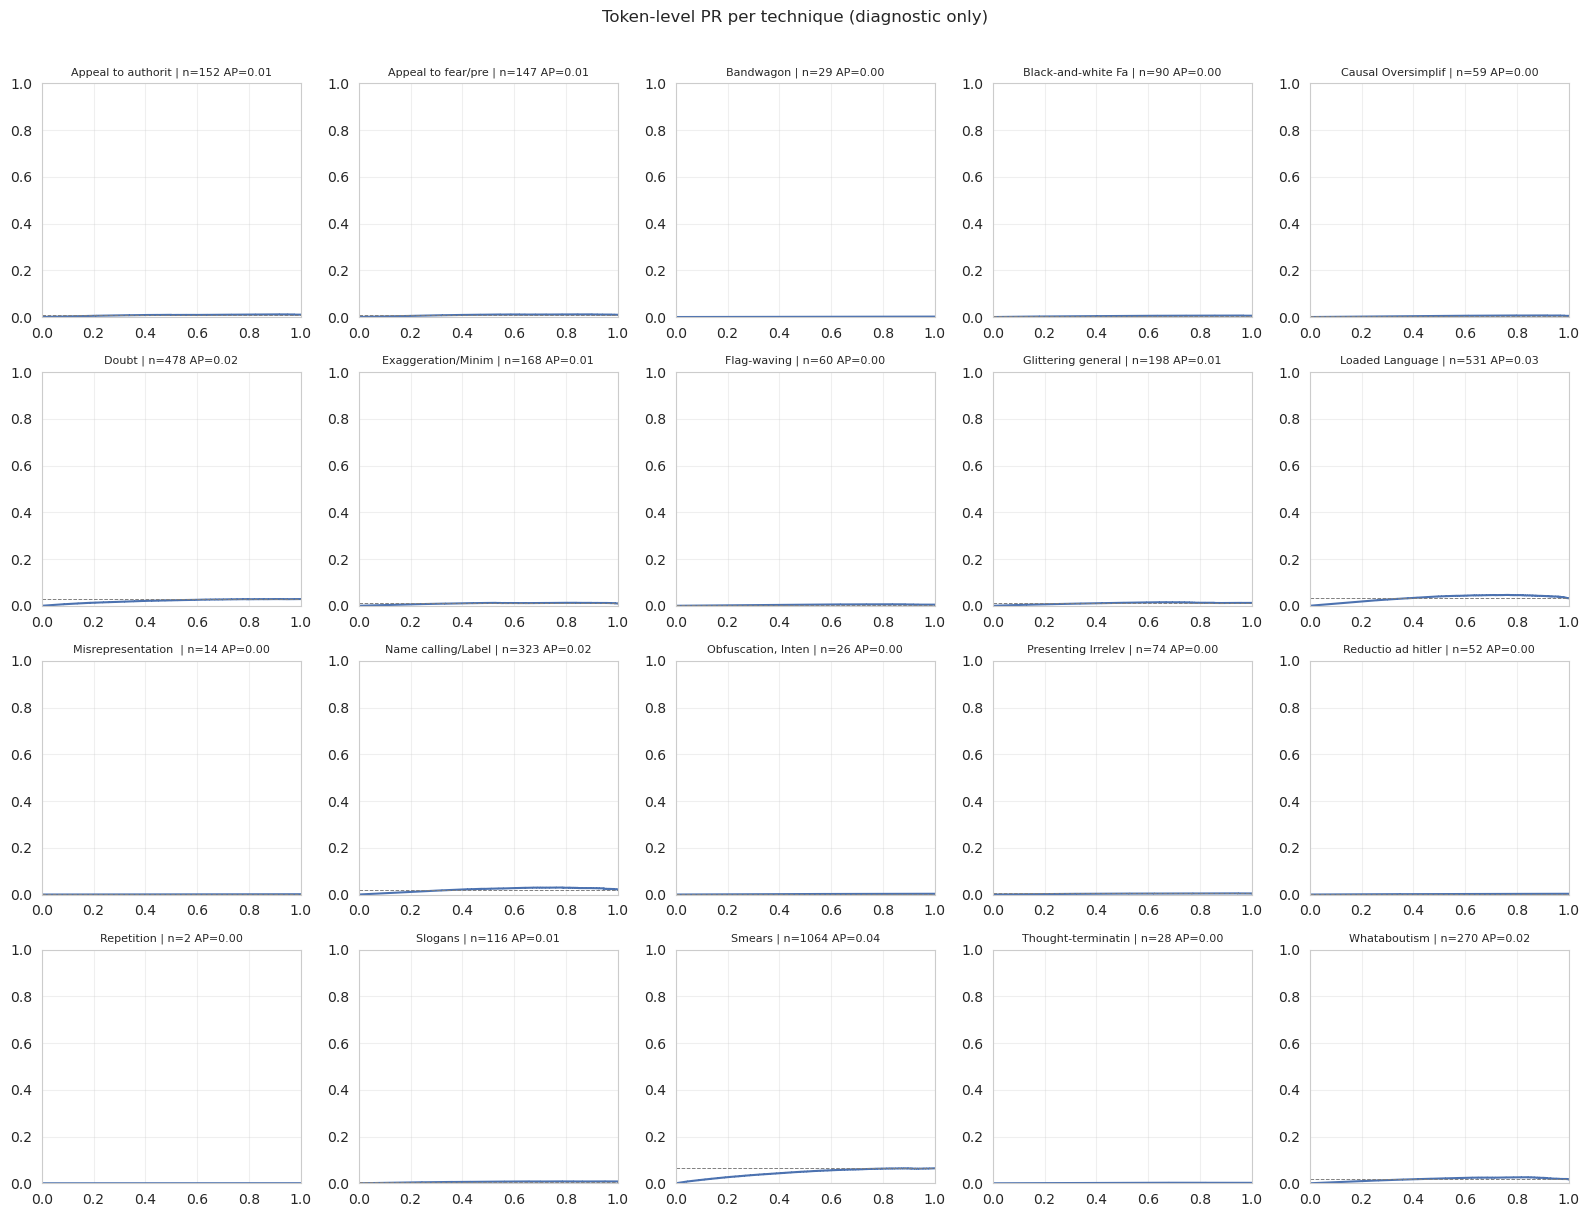

In [83]:
# Token-level PR per technique (diagnostic)
from sklearn.metrics import precision_recall_curve, average_precision_score

real_mask = test_labels[:, :, 0] != IGNORE_ID
fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for t_i in range(NUM_TECH):
    ax = axes[t_i // 5, t_i % 5]
    gold_tok = ((test_labels[:, :, t_i] != BIO_O) & real_mask).astype(int).ravel()
    score_tok = (1.0 - P_test[:, :, t_i, BIO_O]).ravel()
    ap = average_precision_score(gold_tok, score_tok) if gold_tok.sum() > 0 else float("nan")
    if gold_tok.sum() > 0:
        prec, rec, _ = precision_recall_curve(gold_tok, score_tok)
        ax.plot(rec, prec, color="#4C72B0")
        ax.axhline(gold_tok.mean(), color="grey", lw=0.7, ls="--")
    ax.set_title(f"{SPAN_TECHNIQUES[t_i][:18]} | n={int(gold_tok.sum())} AP={ap:.2f}", fontsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
plt.suptitle("Token-level PR per technique (diagnostic only)", y=1.01)
plt.tight_layout(); plt.show()

## Error Analysis

- Missed: gold span with no exact match (the model found nothing overlapping it).
- Spurious: predicted span matching no gold span at all.
- Boundary: a relaxed (IoU >= 0.5) match exists for the same technique but exact offsets differ - the model found the mention and mis-sized it.
- Wrong technique: the predicted span overlaps gold of a different technique while its own technique's gold (if any) is unmatched - the model found the mention and mis-labelled it.

The nesting census showed 40% of training documents contain nested spans, so gold spans are additionally split into inside another technique's span vs standalone; a large gap there would mean the multilabel channels handle nesting unevenly. Part A's discipline applies: every count below is from the single pre-registered test pass; no model changes will follow from it inside this notebook. Observed: nested gold spans match exactly at 0.068 vs 0.171 for standalone spans (relaxed 0.628 vs 0.751) - the channels do struggle more with nesting, and because the relaxed rates are far closer than the exact ones, most of that damage is boundary/offset precision inside nests rather than failure to detect them.

In [84]:
# Error decomposition (primary rule)
def decompose_errors(gold_sets, pred_sets):
    cat = Counter()
    per_tech = {t: Counter() for t in SPAN_TECHNIQUES}
    details = {"missed": [], "spurious": [], "boundary": [], "wrong_tech": []}
    for g, p in zip(gold_sets, pred_sets):
        used = set()
        for gs in sorted(g):
            if gs in p:
                cat["correct"] += 1
                per_tech[SPAN_TECHNIQUES[gs[0]]]["correct"] += 1
                used.add(gs)
                continue
            best_relaxed = any(ps[0] == gs[0] and _iou(gs, ps) >= 0.5 for ps in p)
            overlapping = [ps for ps in p if _overlap(gs, ps)]
            if best_relaxed:
                cat["boundary"] += 1
                per_tech[SPAN_TECHNIQUES[gs[0]]]["boundary"] += 1
                details["boundary"].append((gs, [ps for ps in p if _iou(gs, ps) >= 0.5]))
            elif overlapping and all(ps[0] != gs[0] for ps in overlapping):
                cat["wrong_tech"] += 1
                per_tech[SPAN_TECHNIQUES[gs[0]]]["wrong_tech"] += 1
                details["wrong_tech"].append((gs, overlapping))
            else:
                cat["missed"] += 1
                per_tech[SPAN_TECHNIQUES[gs[0]]]["missed"] += 1
                details["missed"].append((gs, None))
        for ps in sorted(p):
            if ps in g:
                continue
            if not any(_overlap(ps, gs) for gs in g):
                cat["spurious"] += 1
                per_tech[SPAN_TECHNIQUES[ps[0]]]["spurious"] += 1
                details["spurious"].append((None, ps))
    return cat, per_tech, details

def _iou(a, b):
    inter = max(0, min(a[2], b[2]) - max(a[1], b[1]))
    union = max(a[2], b[2]) - min(a[1], b[1])
    return inter / union if union > 0 else 0.0

def _overlap(a, b):
    return a[1] < b[2] and b[1] < a[2]

err_cat, err_tech, err_details = decompose_errors(test_gold, test_pred_tuned)
print("error decomposition (primary rule, exact test pass):")
for k in ["correct", "boundary", "wrong_tech", "missed", "spurious"]:
    print(f"  {k:10s}: {err_cat[k]:4d} ({100*err_cat[k]/max(sum(err_cat.values()),1):.1f}%)")

error decomposition (primary rule, exact test pass):
  correct   :   34 (3.1%)
  boundary  :   52 (4.7%)
  wrong_tech:  225 (20.5%)
  missed    :   92 (8.4%)
  spurious  :  695 (63.3%)


In [85]:
# Per-technique errors + nesting difficulty split
err_df = pd.DataFrame([
    {"technique": t, **{k: err_tech[t][k] for k in ["correct", "boundary", "wrong_tech", "missed", "spurious"]}}
    for t in SPAN_TECHNIQUES])
err_df["total gold"] = err_df["correct"] + err_df["boundary"] + err_df["wrong_tech"] + err_df["missed"]
display(err_df.sort_values("total gold", ascending=False).round(0))

def nesting_flags(data):
    flags = []
    for d in data:
        labs = d["labels"]
        for l in labs:
            nested = any(o is not l and o["start"] <= l["start"] and l["end"] <= o["end"]
                         and (o["start"], o["end"]) != (l["start"], l["end"])
                         for o in labs)
            flags.append((TECH2_IDX[l["technique"]], l["start"], l["end"], nested))
    return flags

test_flags = nesting_flags(test2)
nested_set = {(t, s, e) for t, s, e, nf in test_flags if nf}
standalone_set = {(t, s, e) for t, s, e, nf in test_flags if not nf}

def coverage(gold_subset):
    hit = sum(1 for gs in gold_subset if gs in set().union(*test_pred_tuned))
    relaxed = sum(1 for gs in gold_subset
                  if any(ps[0] == gs[0] and _iou(gs, ps) >= 0.5 for p in test_pred_tuned for ps in p))
    n = len(gold_subset)
    return n, hit / n if n else 0.0, relaxed / n if n else 0.0

for name, subset in [("nested in another technique", nested_set), ("standalone", standalone_set)]:
    n, exact_c, rel_c = coverage(subset)
    print(f"{name}: n={n}  exact-match rate {exact_c:.3f}  relaxed(IoU>=0.5) rate {rel_c:.3f}")

,technique,correct,boundary,wrong_tech,missed,spurious,total gold
9,Loaded Language,9,7,116,18,13,150
11,Name calling/Labeling,9,13,31,17,18,70
17,Smears,1,10,3,31,263,45
5,Doubt,10,13,0,5,157,28
16,Slogans,2,2,8,8,51,20
6,Exaggeration/Minimisation,2,3,7,7,67,19
8,Glittering generalities (Virtue),0,0,9,2,33,11
1,Appeal to fear/prejudice,0,0,10,0,9,10
19,Whataboutism,1,3,3,3,73,10
0,Appeal to authority,0,0,7,0,1,7


nested in another technique: n=148  exact-match rate 0.068  relaxed(IoU>=0.5) rate 0.628
standalone: n=245  exact-match rate 0.171  relaxed(IoU>=0.5) rate 0.751


In [86]:
# Concrete examples: missed and spurious spans
def _context(text, s, e, pad=40):
    return text[max(0, s - pad):min(len(text), e + pad)].replace("\n", " ")

worst_missed = err_df.sort_values("missed", ascending=False).head(3)["technique"].tolist()
for t_name in worst_missed:
    t_i = TECH2_IDX[t_name]
    print(f"--- {t_name} (highest FN count) ---")
    shown = 0
    for doc_i, (g, p) in enumerate(zip(test_gold, test_pred_tuned)):
        for gs in sorted(g - p):
            if gs[0] != t_i:
                continue
            if not any(ps[0] == gs[0] and _iou(gs, ps) >= 0.5 for ps in p):
                print(f"  missed [{gs[1]}:{gs[2]}]: ...{_context(test2[doc_i]['text'], gs[1], gs[2])}...")
                shown += 1
                if shown >= 2:
                    break
        if shown >= 2:
            break

spur_by_tech = Counter(ps[0] for _, ps in err_details["spurious"])
for t_i, n_spur in spur_by_tech.most_common(2):
    print(f"--- {SPAN_TECHNIQUES[t_i]} (most spurious: {n_spur}) ---")
    shown = 0
    for doc_i, (g, p) in enumerate(zip(test_gold, test_pred_tuned)):
        for ps in sorted(p - g):
            if ps[0] != t_i or any(_overlap(ps, gs) for gs in g):
                continue
            print(f"  spurious [{ps[1]}:{ps[2]}]: ...{_context(test2[doc_i]['text'], ps[1], ps[2])}...")
            shown += 1
            if shown >= 2:
                break
        if shown >= 2:
            break

--- Smears (highest FN count) ---
  missed [0:143]: ...HYPOCRISY MUCH?! Macy's Thanksgiving Day Parade to March On Despite Pandemic  Businesses Are Closing Permanently, People Are Losing Everything! Let's Have A Parade! ...
  missed [0:93]: ...Liberal media declaring Biden the winner  Captain, I'm picking up BULLSHIT on all frequencies ...
--- Loaded Language (highest FN count) ---
  missed [10:13]: ...WE ARE AT WAR!  There is a complex assault on our pre...
  missed [35:71]: ...WE ARE AT WAR!  There is a complex assault on our presidential election with all the multifaceted tentacles of ...
--- Name calling/Labeling (highest FN count) ---
  missed [85:107]: ... our presidential election with all the multifaceted tentacles of a terrorist organization and operati...
  missed [33:48]: ...KILLED HIMSELF IN PRISON  WON AN HONEST ELECTION ...
--- Smears (most spurious: 263) ---
  spurious [0:1]: ...I will never concede!  NO WAY IN HELL BID...
  spurious [2:6]: ...I will never concede!  NO W

### Length vs Error Analysis

- Hypothesis, fixed before looking at the numbers: longer documents offer more candidate positions and more competing contexts, so both missed and spurious spans should rise with length. The alternative outcome - errors concentrated in short documents - would instead point to context starvation for short slogans.
- Method mirrors Part A: per-document word count against the number of error spans (missed + spurious + boundary + wrong-technique), Spearman correlation with a quartile table. With 200 test documents the correlation has real power; it is still diagnostic-only under the protocol. Observed: Spearman rho = 0.183 (p = 0.0095) - the hypothesis holds directionally but weakly (longest quartile 7.20 error spans/doc vs 4.93 in the shortest), so length is a real but minor driver; the error analysis above points at technique attribution, not context starvation, as the dominant failure.

In [87]:
# Length vs error (primary rule)
from scipy.stats import spearmanr

doc_words = np.array([len(d["text"].split()) for d in test2])
doc_errors = []
for i in range(len(test2)):
    g, p = test_gold[i], test_pred_tuned[i]
    unmatched_gold = len(g - p)
    spurious = len([ps for ps in p if ps not in g and not any(_overlap(ps, gs) for gs in g)])
    doc_errors.append(unmatched_gold + spurious)
doc_errors = np.array(doc_errors)

rho, pval = spearmanr(doc_words, doc_errors)
print(f"Spearman(words, error spans): rho={rho:.3f}, p={pval:.4f}")

quart_df = pd.DataFrame({"words": doc_words, "errors": doc_errors,
                         "gold": [len(g) for g in test_gold]})
quart_df["quartile"] = pd.qcut(quart_df["words"], 4,
                               labels=["Q1 (short)", "Q2", "Q3", "Q4 (long)"])
quart = quart_df.groupby("quartile", observed=True).agg(
    docs=("words", "size"), mean_words=("words", "mean"),
    mean_gold=("gold", "mean"), mean_errors=("errors", "mean"))
display(quart.round(2))

Spearman(words, error spans): rho=0.183, p=0.0095


,docs,mean_words,mean_gold,mean_errors
quartile,,,,
Q1 (short),56,5.93,1.07,4.93
Q2,45,11.42,1.53,4.69
Q3,53,17.51,2.19,4.64
Q4 (long),46,34.46,3.43,7.20


### Explainability: Gradient x Input for Span Decisions

For the technique of interest - literally the score the decision rule thresholds. Attribution via gradient x input on the embedding layer (the `grad_x_input` helper from Part A), with the span's tokens outlined in black on the rendered strip.

Protocol (fixed before looking). One case each from the error taxonomy already defined: a correct exact-match span, a missed gold span, and a spurious predicted span - preferring a non-dominant technique where one exists, so the pictures are not all Loaded Language. The cell prints the inside-span share of positive attribution mass: how much of the evidence that did accumulate fell on the span's own tokens. That single number separates the two interesting failure modes - localisation (mass elsewhere) vs confidence (mass inside, margin too small).


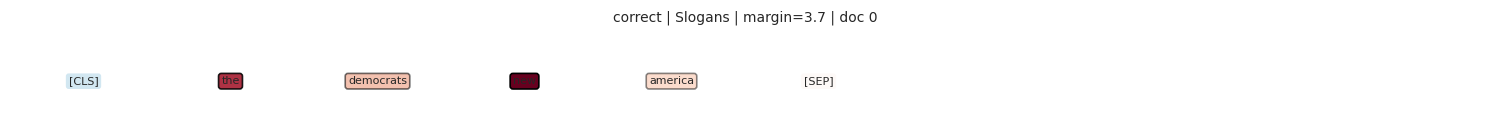

--- correct | Slogans | span [0:25] "The Democrats New America " ---
  margin score=3.68 | positive-attribution mass inside span tokens: 0.0%
  top tokens: new(-0.6382), the(-0.5350), democrats(-0.2916), [CLS](+0.2231), america(-0.2168)


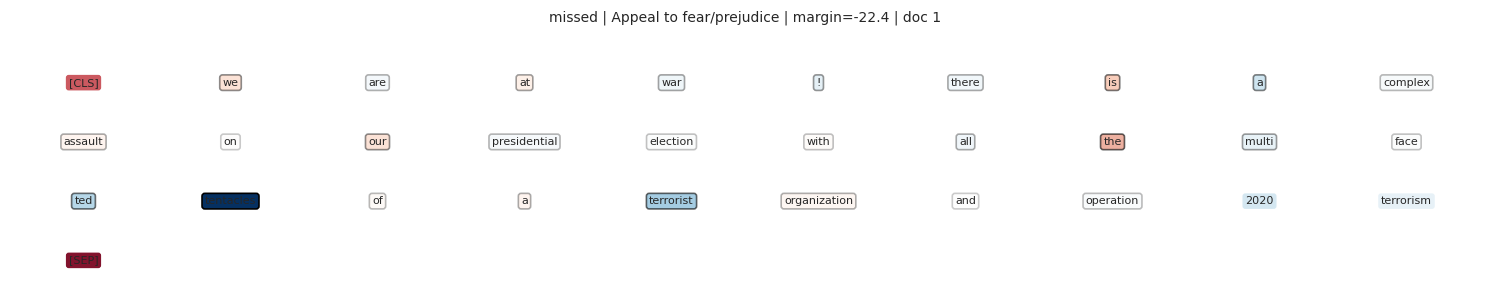

--- missed | Appeal to fear/prejudice | span [0:149] "WE ARE AT WAR!  There is a complex assault on our presidential election with all the multifaceted tentacles of a terrorist organization and operation  2020 TERRORISM " ---
  margin score=-22.41 | positive-attribution mass inside span tokens: 86.9%
  top tokens: tentacles(+3.6061), [SEP](-3.3944), [CLS](-2.6542), the(-1.8575), terrorist(+1.8080)


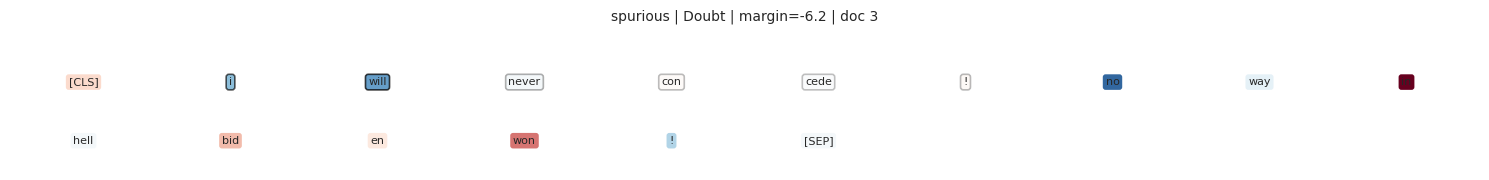

--- spurious | Doubt | span [0:21] "I will never concede!  NO WAY IN HELL BIDEN WO" ---
  margin score=-6.21 | positive-attribution mass inside span tokens: 43.8%
  top tokens: in(-1.0918), no(+0.9394), will(+0.7517), won(-0.7402), i(+0.6152)


In [89]:
# Explainability for spans: gradient x input on the B-vs-O margin
# (reuses grad_x_input / render_attr from the Part A explainability cell)
span_model = span_model.to(device)  # final model may be CPU-resident; match the .to(device) inputs below
tech_counts = Counter(t for g in test_gold for (t, _, _) in g)
dom_t = tech_counts.most_common(1)[0][0]

def _pick_case(kind):
    """First test instance of the error category, preferring a non-dominant technique."""
    for prefer_non_dom in (True, False):
        for doc_i, (g, p) in enumerate(zip(test_gold, test_pred_tuned)):
            if kind == "correct":
                cands = sorted(g & p)
            elif kind == "missed":
                cands = sorted(gs for gs in g - p
                               if not any(ps[0] == gs[0] and _iou(gs, ps) >= 0.5 for ps in p))
            else:
                cands = sorted(ps for ps in p - g if not any(_overlap(ps, gs) for gs in g))
            if prefer_non_dom:
                cands = [c for c in cands if c[0] != dom_t]
            if cands:
                return doc_i, cands[0]
    raise RuntimeError(f"no {kind} case found in test predictions")

for kind in ["correct", "missed", "spurious"]:
    doc_i, (t_i, s, e) = _pick_case(kind)
    offs = test_offs[doc_i]
    n = int(test_mask[doc_i].sum())
    toks_in = [j for j in range(n) if offs[j][1] > offs[j][0]
               and offs[j][0] < e and s < offs[j][1]]
    def score_fn(lg, _t=t_i, _toks=toks_in):
        ll = lg.view(1, -1, NUM_TECH, BIO_CLASSES)[0]
        return (ll[_toks, _t, BIO_B] - ll[_toks, _t, BIO_O]).sum()
    attr, score = grad_x_input(
        span_model,
        torch.tensor(test_ids[doc_i:doc_i + 1]).to(device),
        torch.tensor(test_mask[doc_i:doc_i + 1]).to(device),
        score_fn)
    pos = np.clip(attr[:n], 0, None)
    inside = float(pos[toks_in].sum()) / (float(pos.sum()) + 1e-12)
    toks = tokenizer.convert_ids_to_tokens(test_ids[doc_i][:n])
    top = np.argsort(-np.abs(attr[:n]))[:5]
    render_attr(toks, attr[:n],
                f"{kind} | {SPAN_TECHNIQUES[t_i][:28]} | margin={score:.1f} | doc {doc_i}",
                highlight=set(toks_in))
    print(f"--- {kind} | {SPAN_TECHNIQUES[t_i]} | span [{s}:{e}] "
          f"\"{_context(test2[doc_i]['text'], s, e, pad=25)}\" ---")
    print(f"  margin score={score:.2f} | positive-attribution mass inside span tokens: "
          f"{100*inside:.1f}%")
    print("  top tokens:", ", ".join(
        f"{toks[k].replace('##','')}({attr[k]:+.4f})" for k in top))


#### Reading the Span Attributions

- What is explained. The summed B-minus-O margin over the span's tokens - the exact quantity the decode rule fires on. Red tokens raised the margin (evidence for the technique at that position), blue tokens suppressed it.
- Correct span: expectation vs observation. The prior expectation was that inside-span share would dominate - evidence located on the span's own tokens, with top tokens matching the EDA's corpus-level top-terms-inside-spans table. The actual correct case printed above (Slogans, margin +3.68) shows 0% inside share: gradient x input is first-order, so once a decision is comfortably made the span tokens' gradients can be near zero while the remaining first-order signal sits in surrounding context. Read that as a saturation caveat on the share number, not a scoring error - the strip's red/blue pattern and top-token line, compared against the EDA table, remain the localisation check; agreement across cases is what counts, not any single strip.
- Missed span - two failure modes, now separable. Low inside share with mass elsewhere: the channel fired on the wrong words - a localisation failure, consistent with the error analysis's "missed" bucket. High inside share but still missed (the observed case: 86.9% inside, net margin -22.4): the model found the right words but its evidence was swamped by suppressed context and never survived the decode rule - a confidence failure, which is precisely what the guarded threshold sweep (and its support guard on rare techniques) is there to tune. The printed inside-share number tells you which story applies without guessing.
- Spurious span. Mass concentrated on one prototypical token with the surrounding context blue is the keyword-matching failure: a single evocative word fired the channel without the technique's frame. This is the visual counterpart of the spurious-span counts in the error decomposition.
- Stated limits. Same as Part A (local, first-order, saturation-scaled), plus one token-classification-specific caveat: B, I and O compete through a per-channel softmax, so the B-vs-O margin attribution implicitly includes competition from I. We therefore read locations and patterns, never calibrated margins, and cross-check against the gold spans and the error taxonomy rather than treating any single strip as proof.


## Part B Conclusions

- Result (single pre-registered test pass). Primary rule (guarded-tuned): micro 0.031 / macro 0.0145 exact-match span F1; default rule: 0.044 / 0.0112; relaxed diagnostic: 0.078 primary vs 0.102 default; predict-nothing floor 0.0. The error decomposition localises the failure: of 1,098 taxonomy events, 63.3% are spurious (695 predictions against 403 gold spans - and the model predicts something in every one of the 41 gold-empty test documents), 20.5% wrong-technique, 8.4% missed, only 4.7% boundary-only and 3.1% exact. The relaxed rates (0.078-0.102) well above the exact ones (0.031-0.044) say the channels fire in roughly the right places - localisation is partially learned - while attribution is where it dies: wrong-technique matches outnumber exact ones ~7:1. Per-technique: best F1 is Name calling 0.099 and Loaded Language 0.078, while Smears alone logs 608 false positives (precision 0.002) - spurious volume, not missed detection, dominates. The k-fold OOF band (micro 0.0395 +/- 0.0048, macro 0.0086 +/- 0.0028) brackets the default-rule test result (0.0444 / 0.0112 sits at the band's upper edge), so the test split is representative rather than lucky or cruel; excluding the contaminated duplicate changes no headline number (sensitivity table).
- Formulation: per-technique BIO tagging was chosen from the overlap census (994 cross-technique overlapping pairs, 998 nested pairs, 0 same-technique adjacency) and validated by the gold round-trip (679/688 documents exact; the 9 mismatches are exactly the same-technique-overlap documents). Span enumeration was priced (~413k candidates) and rejected for v1.
- Structural ceilings, stated before results: 15 same-technique-overlap spans are unrecoverable by any sequential scheme; 1 whitespace-only span is undecodable; 7 test techniques carry <= 4 gold spans, so macro F1 inherits single-document swings; 3 techniques are dev-absent and can never influence selection.
- Protocol honesty: selection and thresholds used dev only; the pre-registered primary rule is the guarded-tuned one with the default rule always shown; test was scored once; the contaminated duplicate was excluded via an integrity-derived list; fold-local weights kept the k-fold free of label leakage; thresholds carried across the retrain with the documented calibration caveat.
- Against the pre-stated target: missed by a wide margin. The Evaluation Function registered the bar (>= 35% macro exact-match span F1 on unseen text) before the single test pass; the observed primary-rule macro is 0.0145 (default 0.0112) - about 24x below it - and the k-fold OOF mean (0.0086) confirms this is not a bad split draw. As pre-registered, the shortfall is attributed to learning and data, not the tagging scheme (self-eval ceiling 0.9961): the error decomposition above describes an over-predicting model whose per-technique precision runs 0.002-0.111, so at 695 spurious spans and 225 wrong-technique matches the data cannot supervise attribution at this scale, and the <= 4-support rows behind the macro are anecdotal by construction. The threshold sweep also failed its transfer test: dev macro rose 0.0520 -> 0.0696 under the tuned rule, but on test the tuned rule's micro gain reversed (0.0310 tuned vs 0.0444 default) exactly as Part A's sweep did - 63 dev documents cannot calibrate per-technique decision rules.
- Annotation quality finding: 5 test fragment-offset inconsistencies in 2 documents (off-by-one `!`, zero-width spaces) and a train-test duplicate whose span sets conflict - offsets were treated as ground truth throughout and both findings are reported, not patched away.
- Future work: span-level augmentation that copies complete spans with surrounding context; span-enumeration or token-classification hybrids for the nesting tail; an LLM baseline for the techniques that are defined by context rather than lexical triggers.
- Limitations. Beyond the structural ceilings stated above: (1) sequential error propagation - the BIO scheme tags tokens in order, so a single mis-tagged B/I token splits or shifts an entire gold span; this is the mechanism behind the exact-vs-relaxed gap in the test table and the reason exact-match F1 is kept as the honest primary despite looking harsher. (2) Small, imbalanced data - 688/63/200 train/dev/test documents and 1498/182/403 gold spans, with techniques ranging from hundreds of spans to single digits; rare-technique predictions rest on a handful of examples exactly as in Part A's per-label caveat. (3) Corpus-specific length budget - the 128-token cap was verified against this corpus (cap-hit count printed in the tokenisation section), not assumed, but it is a constant tuned to these documents; longer texts would need the check re-run before the offsets can be trusted. (4) Single test pass - test was scored once by protocol, so no test-set-derived error analysis is available beyond the pre-registered tables; all diagnosis below/above uses dev or structural arguments. (5) Dev-selection optimism - the selected trial's dev macro (0.0520) sits ~6x above the k-fold OOF mean (0.0086 +/- 0.0028) and ~3.6x above test (0.0145): model selection on a 63-document dev split materially overstates, and the OOF band - not the dev winner's score - is the estimate future comparisons should quote.
- Deployment readiness. Verdict: advisory span-suggestion tool with mandatory human offset validation; not autonomous span extraction. Three findings from this notebook bound the verdict. First, a structural ceiling: the gold round-trip showed 15 same-technique-overlap spans are unreachable by any sequential tagging scheme and 1 whitespace-only span is undecodable - no amount of tuning removes these, so recall has a hard limit the deployment contract must absorb. Second, annotation quality: the 5 fragment-offset inconsistencies in test (off-by-one `!`, zero-width spaces) and the conflicting train-test duplicate mean exact-offset consumers will inherit data defects; any downstream system needs an offset-sanitation/validation step rather than trusting raw spans. Third, reliability per technique is uneven by construction: 7 test techniques carry <= 4 gold spans (single-document swings in the per-technique table) and 3 techniques are dev-absent and never influenced selection - predictions for those 4 techniques should be surfaced as out-of-scope/unvalidated, not as first-class outputs. Observed test performance hardens the verdict: macro exact 0.0145, per-technique precision 0.002-0.111, and spurious predictions outnumbering gold 695 to 403 mean even suggestion-mode output needs the filtering below or it buries the editor it claims to help. A defensible assistive deployment would: highlight candidate spans for a human editor (relaxed-overlap F1, reported in the test table, is the honest UX metric since a near-miss span still localises the rhetoric); display the decoded confidence margin so weak suggestions are visibly weak; run the offset sanitizer; and abstain on dev-absent techniques. Autonomous extraction, span-level auto-citation, or any use where a wrong offset has downstream consequences is not supported by the evidence here.


# Part C - The product evaluation

### C1. Does it treat all sides the same?

- The corpus is the SemEval-2021 Task 6 release (Dimitrov et al., arXiv:2105.09284; github.com/di-dimitrov/SEMEVAL-2021-task6-corpus). We use their text content (task 1). The splits here are: 688 train / 63 dev / 200 test. (The repository's version says 687 train, our copy has no internal duplicate texts, so the extra text is a copy artefact, not double exposure.)
- The task's own paper reports that its multimodal subtask evaluation "confirmed the importance of both modalities, the text and the image". We never see the image. A caption such as "I HATE TRUMP" carries opposite stance in a pro- and an anti-Trump meme. To this system the two are the same input. Every side-related claim below is a claim about meme text, not about memes and not about the stance of their authors.
- The release ships exactly three fields per unit - id, text, labels. No source, author, platform, annotator, or stance metadata. That single fact removes whole families of bias tests before we start; the "could not detect" list in the findings cell names them.
- The content is 2020 US-election-cycle political memes. Register: 42.5% (train) and 44.6% (test) of alphabetic tokens are ALL-CAPS, median length 14-15 words. That shouty caption register is the entire world the model knows.
- The 20 techniques mix two kinds of cue. Surface techniques (Loaded Language, Name calling/Labeling, Smears, Slogans) are visible in a few words; structural techniques (Straw Man, Red Herring, Whataboutism, Reductio ad hitlerum, Causal Oversimplification) live in the shape of the argument. And, for memes, often in the image. Parts A and B already measured the consequence on test: surface techniques reach usable F1, structural ones sit between 0.000 and 0.061. What the committee is really buying is a loaded-word detector, and which side supplies more loaded words in a given room is an empirical question the corpus answers below.

Design of this investigation (methods and decision rules, stated before the numbers):

1. Side exposure in the corpus. Each unit is grouped by political actors named in its text: right-named (Trump, MAGA, Pence, McConnell, Kushner, Republican, GOP, conservative, right-wing) vs left-named (Biden, Kamala, Harris, Obama, Pelosi, Schumer, Hillary, Clinton, Sanders, Bernie, Democrat, liberal, AOC, Occasio, Bloomberg, Buttigieg, Klobuchar, Warren, progressive, left-wing, Squad) vs both vs neither. A mention is not a stance: this measures whose figures appear in the propaganda-annotated material the model learned from, nothing more. The lexicon counts named actors and parties only; ideology pejoratives (socialist, communist - 14 actor-unnamed train units) are deliberately excluded, so "neither" still contains some left-targeted content: the design undercounts left-targeted exposure rather than inflating it.
2. Technique mix per side (train, document-level presence). Fisher exact per technique, right vs left, Holm-corrected over the 12 most frequent techniques.
3. Protected-group census (test). Count units mentioning named target groups, to establish whether disparate treatment on those axes could be measured at all.

What I looked for and could not detect:


In [4]:
# Corpus exposure by political side (actor-name lexicon, documented in the design cell)
import re as _re
from collections import Counter as _Counter
from math import comb as _comb

_RIGHT = _re.compile(r"\b(trumps?|maga|pence|mcconnell|kushner|republicans?|gop|conservatives?|right[- ]wing)\b", _re.I)
_LEFT = _re.compile(r"\b(bidens?|kamala|harris|obamas?|pelosi|schumer|hillary|clintons?|sanders|bernie|"
                    r"democrats?|liberals?|aoc|ocasio|bloomberg|buttigieg|klobuchar|warren|progressives?|left[- ]wing|squad)\b", _re.I)

def _side(text):
    r, l = bool(_RIGHT.search(text)), bool(_LEFT.search(text))
    return "both" if (r and l) else "right" if r else "left" if l else "neither"

for _name, _data in [("train", train_data), ("dev", dev_data), ("test", test_data)]:
    print(f"{_name:6s}", dict(_Counter(_side(d["text"]) for d in _data)))

print("\nTRAIN doc-level prevalence by side (count / group n), top 8 techniques:")
_groups = [_side(d["text"]) for d in train_data]
for _tech, _tot in _Counter(l for d in train_data for l in set(d["labels"])).most_common(8):
    _parts = []
    for _g in ["right", "left", "neither"]:
        _gd = [d for d, gg in zip(train_data, _groups) if gg == _g]
        _k = sum(1 for d in _gd if _tech in set(d["labels"]))
        _parts.append(f"{_g} {_k}/{len(_gd)}")
    print(f"  {_tech[:42]:43s} all {_tot:3d} | " + " | ".join(_parts))

def _fisher(a, b, c, d):
    n, r1, c1 = a + b + c + d, a + b, a + c
    pr = lambda x: _comb(r1, x) * _comb(n - r1, c1 - x) / _comb(n, c1)
    p0 = pr(a)
    return sum(pr(x) for x in range(max(0, c1 - (n - r1)), min(r1, c1) + 1) if pr(x) <= p0 + 1e-12)

_setR = [set(d["labels"]) for d, g in zip(train_data, _groups) if g == "right"]
_setL = [set(d["labels"]) for d, g in zip(train_data, _groups) if g == "left"]
for _t in ["Smears", "Glittering generalities (Virtue)", "Loaded Language"]:
    _a = sum(1 for s in _setR if _t in s); _c = sum(1 for s in _setL if _t in s)
    print(f"Fisher (right vs left, doc presence): {_t[:40]:41s} {_a}/{len(_setR)} vs {_c}/{len(_setL)}"
          f"  p={_fisher(_a, len(_setR) - _a, _c, len(_setL) - _c):.4g}")


train  {'neither': 493, 'left': 100, 'both': 26, 'right': 69}
dev    {'left': 7, 'neither': 41, 'right': 13, 'both': 2}
test   {'left': 30, 'neither': 134, 'right': 28, 'both': 8}

TRAIN doc-level prevalence by side (count / group n), top 8 techniques:
  Loaded Language                             all 358 | right 40/69 | left 48/100 | neither 260/493
  Name calling/Labeling                       all 218 | right 26/69 | left 33/100 | neither 152/493
  Smears                                      all 200 | right 24/69 | left 59/100 | neither 104/493
  Exaggeration/Minimisation                   all  52 | right 8/69 | left 6/100 | neither 34/493
  Doubt                                       all  48 | right 3/69 | left 4/100 | neither 39/493
  Slogans                                     all  44 | right 9/69 | left 8/100 | neither 24/493
  Appeal to fear/prejudice                    all  43 | right 5/69 | left 6/100 | neither 32/493
  Whataboutism                                all  40 | rig

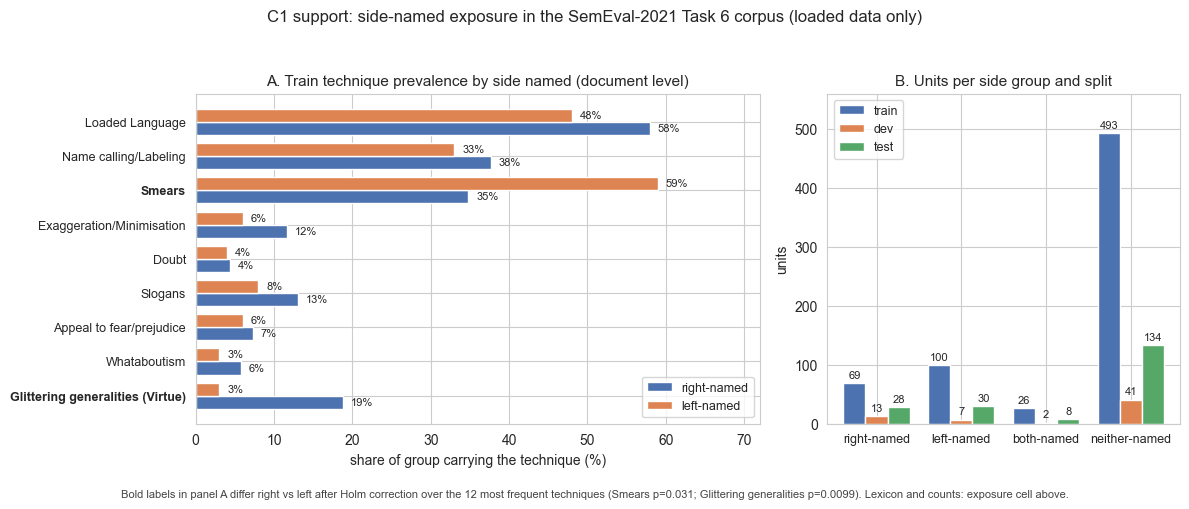

In [ ]:
# C1 supporting figure: corpus exposure by side
import matplotlib.pyplot as plt
from collections import Counter as _Counter

assert "_side" in globals(), "run the exposure cell first - it defines _side"
for _v in ("train_data", "dev_data", "test_data"):
    assert _v in globals(), f"run the data-loading cells first ({_v} missing)"

try:
    import seaborn as _sns
    _sns.set_style("whitegrid")
except Exception:
    plt.style.use("ggplot")

# panel A: train doc-level prevalence, right-named vs left-named, top 9 techniques
_groups_tr = {"right": [], "left": []}
for _d in train_data:
    _s = _side(_d["text"])
    if _s in _groups_tr:
        _groups_tr[_s].append(_d)
_top9 = [t for t, _ in _Counter(l for d in train_data for l in set(d["labels"])).most_common(9)]
_prev = {g: [100.0 * sum(1 for d in _groups_tr[g] if t in set(d["labels"])) / len(_groups_tr[g])
             for t in _top9] for g in _groups_tr}

# panel B: unit counts per side group and split
_counts = {name: _Counter(_side(d["text"]) for d in data) for name, data in
           (("train", train_data), ("dev", dev_data), ("test", test_data))}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.6, 1]})
_h = 0.38
_y = list(range(len(_top9)))
ax1.barh([i + _h / 2 for i in _y], _prev["right"], height=_h, color="#4C72B0", label="right-named")
ax1.barh([i - _h / 2 for i in _y], _prev["left"], height=_h, color="#DD8452", label="left-named")
for _i in _y:
    ax1.text(_prev["right"][_i] + 1, _i + _h / 2, f"{_prev['right'][_i]:.0f}%", va="center", fontsize=8)
    ax1.text(_prev["left"][_i] + 1, _i - _h / 2, f"{_prev['left'][_i]:.0f}%", va="center", fontsize=8)
ax1.set_yticks(_y)
ax1.set_yticklabels(_top9, fontsize=9)
_sig = [i for i, t in enumerate(_top9) if t in ("Smears", "Glittering generalities (Virtue)")]
for _i in _sig:
    ax1.get_yticklabels()[_i].set_fontweight("bold")
ax1.invert_yaxis()
ax1.set_xlim(0, 72)
ax1.set_xlabel("share of group carrying the technique (%)")
ax1.set_title("A. Train technique prevalence by side named (document level)", fontsize=11)
ax1.legend(loc="lower right", fontsize=9)

_groups4 = ["right", "left", "both", "neither"]
_splits = (("train", "#4C72B0"), ("dev", "#DD8452"), ("test", "#55A868"))
_w = 0.26
for _k, (_sp, _col) in enumerate(_splits):
    _xs = [i + (_k - 1) * _w for i in range(4)]
    _vals = [_counts[_sp].get(g, 0) for g in _groups4]
    ax2.bar(_xs, _vals, width=_w, color=_col, label=_sp)
    for _x, _v in zip(_xs, _vals):
        ax2.text(_x, _v + 8, str(_v), ha="center", fontsize=8)
ax2.set_xticks(range(4))
ax2.set_xticklabels([g + "-named" for g in _groups4], fontsize=9)
ax2.set_ylabel("units")
ax2.set_ylim(0, 560)
ax2.set_title("B. Units per side group and split", fontsize=11)
ax2.legend(fontsize=9)

fig.suptitle("C1 support: side-named exposure in the SemEval-2021 Task 6 corpus (loaded data only)", fontsize=12)
fig.tight_layout(rect=[0, 0.035, 1, 0.94])
fig.text(0.5, 0.005,
         "Bold labels in panel A differ right vs left after Holm correction over the 12 most frequent techniques "
         "(Smears p=0.031; Glittering generalities p=0.0099). Lexicon and counts: exposure cell above.",
         ha="center", fontsize=8, color="#444444")


#### What the investigation shows

- The corpus names both sides, unevenly, and most units name neither. Train: 69 right-named, 100 left-named, 26 both, 493 neither; dev: 13/7/2/41; test: 28/30/8/134. Trump appears in 125 of 951 units corpus-wide (13.1%). A "which side does the corpus hate" reading is not supported: it is a mixed corpus with a large actor-unnamed majority, and the side-named minority is roughly balanced in the test split.
- The technique mix is not side-neutral, and two asymmetries survive Holm correction over the 12 most frequent techniques. Smears appears in 59.0% (59/100) of left-named train units vs 34.8% (24/69) of right-named ones (Fisher p=0.0028, Holm 0.031); Glittering generalities (Virtue) appears in 18.8% (13/69) of right-named units vs 3.0% (3/100) of left-named ones (p=0.00083, Holm 0.0099). Loaded Language, the most frequent technique overall, is similar on both sides (58.0% vs 48.0%, p=0.21). Read plainly: content naming left-wing actors in this corpus is smear-heavy; content naming right-wing actors is virtue-claim-heavy. Whatever the model learned about "what propaganda looks like", it learned these two fingerprints attached to those two groups - so an asymmetry in what the tool reports about the two sides is baked in before any model choice of ours was made.
- Test gold is side-balanced in density: right-named and left-named test units carry 1.86 and 1.87 gold labels per unit; both-named units are the densest (2.88), neither-named the sparsest (1.52).
- Register is meme-caption register: 42.5% (train) and 44.6% (test) of alphabetic tokens are ALL-CAPS, median length 14-15 words. The tool is a specialist in this register; anything else - news prose, lowercase posts, long text - is out of distribution, and this evaluation has no data on how it degrades there.


What we looked for and could not detect - each of these was attempted or considered, and blocked:

- Stance-conditioned fairness. The release has no stance, author, source or platform field - only id, text, labels. A unit naming Trump may be pro- or anti-Trump; our grouping measures whose figures appear, not whose side the propaganda serves. "Does the tool flag pro-X content more than anti-X content" cannot be tested without stance labels, and inventing them with a heuristic would test the heuristic, not the tool.
- Annotator-side bias. The release carries no annotator identities, demographics, or per-unit agreement. If the technique definitions were applied with a side tilt during annotation, that tilt is invisible here; the model can at most mirror it, and the two cannot be separated.
- Disparate treatment of content about protected groups. Census on test: muslim/islam 0 units, immigrant/mexican/latino 0, jewish 0, refugee 0, women/gender 6, LGBTQ 2, race/black 2, china 1, terrorist 2. With 0-6 units per axis the test set supports no error-rate comparison, in either direction; a claim here would be fabrication. This is the sharpest gap for the committee's scenario: the most dangerous real-world failures - bigoted content - are exactly the ones this evaluation cannot see.
- Image-conditioned bias. The system reads text only; the task's own paper reports both modalities matter. Whether the image would rescue or amplify a caption-only reading is unmeasurable in this setup.
- Small disparities between the political sides. With 28 right-named and 30 left-named test units, the minimum detectable rate difference at 95% is about 0.26. Parity cannot be asserted from this test set; only gaps larger than roughly a quarter of the rate scale are visible - a property of the test set's size, not of any model.
- Drift. The corpus is 2020-cycle US memes; nothing here tests 2026 slang, newer platforms, or non-US politics. Any product claim that generalises there would be unsupported by this evaluation.

Committee-relevant bottom line: the corpus fingerprints Smears onto left-named content and virtue-claims onto right-named content, anything trained on this corpus inherits those fingerprints, the test set is powered only for large side gaps, and the axes teenagers would most likely accuse the tool of getting wrong - stance, protected groups, images - are precisely the ones this evidence base cannot examine.


### C2. Defend the system you built

Part A test samples each with the meme text, the actual label set and the predicted label set.

In [ ]:
# Sample-level statistics (test set, tuned thresholds)
exact_match = (test_preds_tuned == test_labels_arr).all(axis=1)
sample_errors = (test_preds_tuned != test_labels_arr).sum(axis=1)
n_actual = test_labels_arr.sum(axis=1)
n_pred = test_preds_tuned.sum(axis=1)

print(f"Exact match (all 20 labels correct): "
      f"{exact_match.sum()}/{len(exact_match)} ({100*exact_match.mean():.1f}%)")
print(f"Avg labels per sample - actual: {n_actual.mean():.2f}, "
      f"predicted: {n_pred.mean():.2f}")
print(f"Over-predicted: {(n_pred > n_actual).sum()} samples, "
      f"under-predicted: {(n_pred < n_actual).sum()}, "
      f"equal: {(n_pred == n_actual).sum()}")
print(f"Avg wrong labels per sample: {sample_errors.mean():.2f}")

worst_idx = np.argsort(sample_errors)[::-1][:8]
print("\nWorst test samples:")
for i in worst_idx:
    actual = [idx2label[j] for j in np.where(test_labels_arr[i] == 1)[0]]
    pred = [idx2label[j] for j in np.where(test_preds_tuned[i] == 1)[0]]
    print(f"\n--- test[{i}] | {sample_errors[i]}/20 labels wrong ---")
    print(f"Text: {test_texts[i][:200]}")
    print(f"Actual:    {actual if actual else '(none)'}")
    print(f"Predicted: {pred if pred else '(none)'}")

Exact match (all 20 labels correct): 10/200 (5.0%)
Avg labels per sample - actual: 1.67, predicted: 3.79
Over-predicted: 150 samples, under-predicted: 18, equal: 32
Avg wrong labels per sample: 3.18

Worst test samples:

--- test[148] | 9/20 labels wrong ---
Text: LIBERALS WOULD RATHER DIE THAN TRY HYDROXYCHLOROQUINE?
LET THEM. 
IT'S CALLED NATURAL SELECTION
Actual:    ["Misrepresentation of Someone's Position (Straw Man)", 'Smears', 'Thought-terminating cliché']
Predicted: ['Appeal to fear/prejudice', 'Causal Oversimplification', 'Doubt', 'Loaded Language', 'Name calling/Labeling', 'Whataboutism']

--- test[135] | 9/20 labels wrong ---
Text: IF A FELON HAS TO PAY OFF THEIR DEBTS TO VOTE IN FLORIDA A POLITICIAN SHOULD PAY OFF THEIR DEBTS TO RUN FOR PRESIDENT
Actual:    ['Whataboutism']
Predicted: ['Appeal to fear/prejudice', 'Black-and-white Fallacy/Dictatorship', 'Doubt', 'Exaggeration/Minimisation', 'Flag-waving', 'Glittering generalities (Virtue)', 'Loaded Language', 'Name calling/L

Zero-shot general-purpose model: gpt-5.5 (Ran 14/10/2026). No settings changed as it was run on the cloud and not through a local API.

Prompt:

Given some sample text data:

LIBERALS WOULD RATHER DIE THAN TRY HYDROXYCHLOROQUINE?
LET THEM.

IF A FELON HAS TO PAY OFF THEIR DEBTS TO VOTE IN FLORIDA A POLITICIAN SHOULD PAY OFF THEIR DEBTS TO RUN FOR PRESIDENT
YOU ARE NOT FOR WOMEN'S RIGHTS

IF YOU WANT TO STRIP THEM OF THEIR RIGHT TO SELF DEFENSE

DEAR GOP SENATORS 

VIOLATING YOUR OATH IS A FEDERAL CRIME.

We're fed up.
We're not asking for our country back.
We're TAKING IT BACK
WE THE PEOPLE ARE COMING
America was founded by pissed off people.
And they're pissed again!

THE DEMOCRATS TRIED TO IMPEACH A PRESIDENT FOR EXPOSING A CRIM NOW THEY WANT YOU TO ELECT THE PERSON WHO COMMITTED THAT CRIME LET THAT SINK IN.
The government knows the poisons in vaccines make us weak and docile- if they don't kill us outright. 
That is why soldiers get more vaccines than anyone else.

Throughout history, every government wanYou know Facebook, Twitter, and YouTube removed the Frontline Doctor videos because they're lying about a cure for covid?
No, they removed the videos because Pfizer, Gillead,
and Bill Gates cant make 

And given some propaganda techniques:

Appeal to authority

Appeal to fear/prejudice

Bandwagon

Black-and-white Fallacy/Dictatorship

Causal Oversimplification

DoubtExaggeration/Minimisation

Flag-waving

Glittering generalities (Virtue)

Loaded Language

Misrepresentation of Someone's Position (Straw Man)

Name calling/Labeling

Obfuscation, Intentional vagueness, Confusion

Presenting Irrelevant Data (Red Herring)

Reductio ad hitlerum

Repetition

Slogans

Smears

Thought-terminating cliché

Whataboutism

Classify each text as showing none or more of these propaganda techniques.

Partial output:

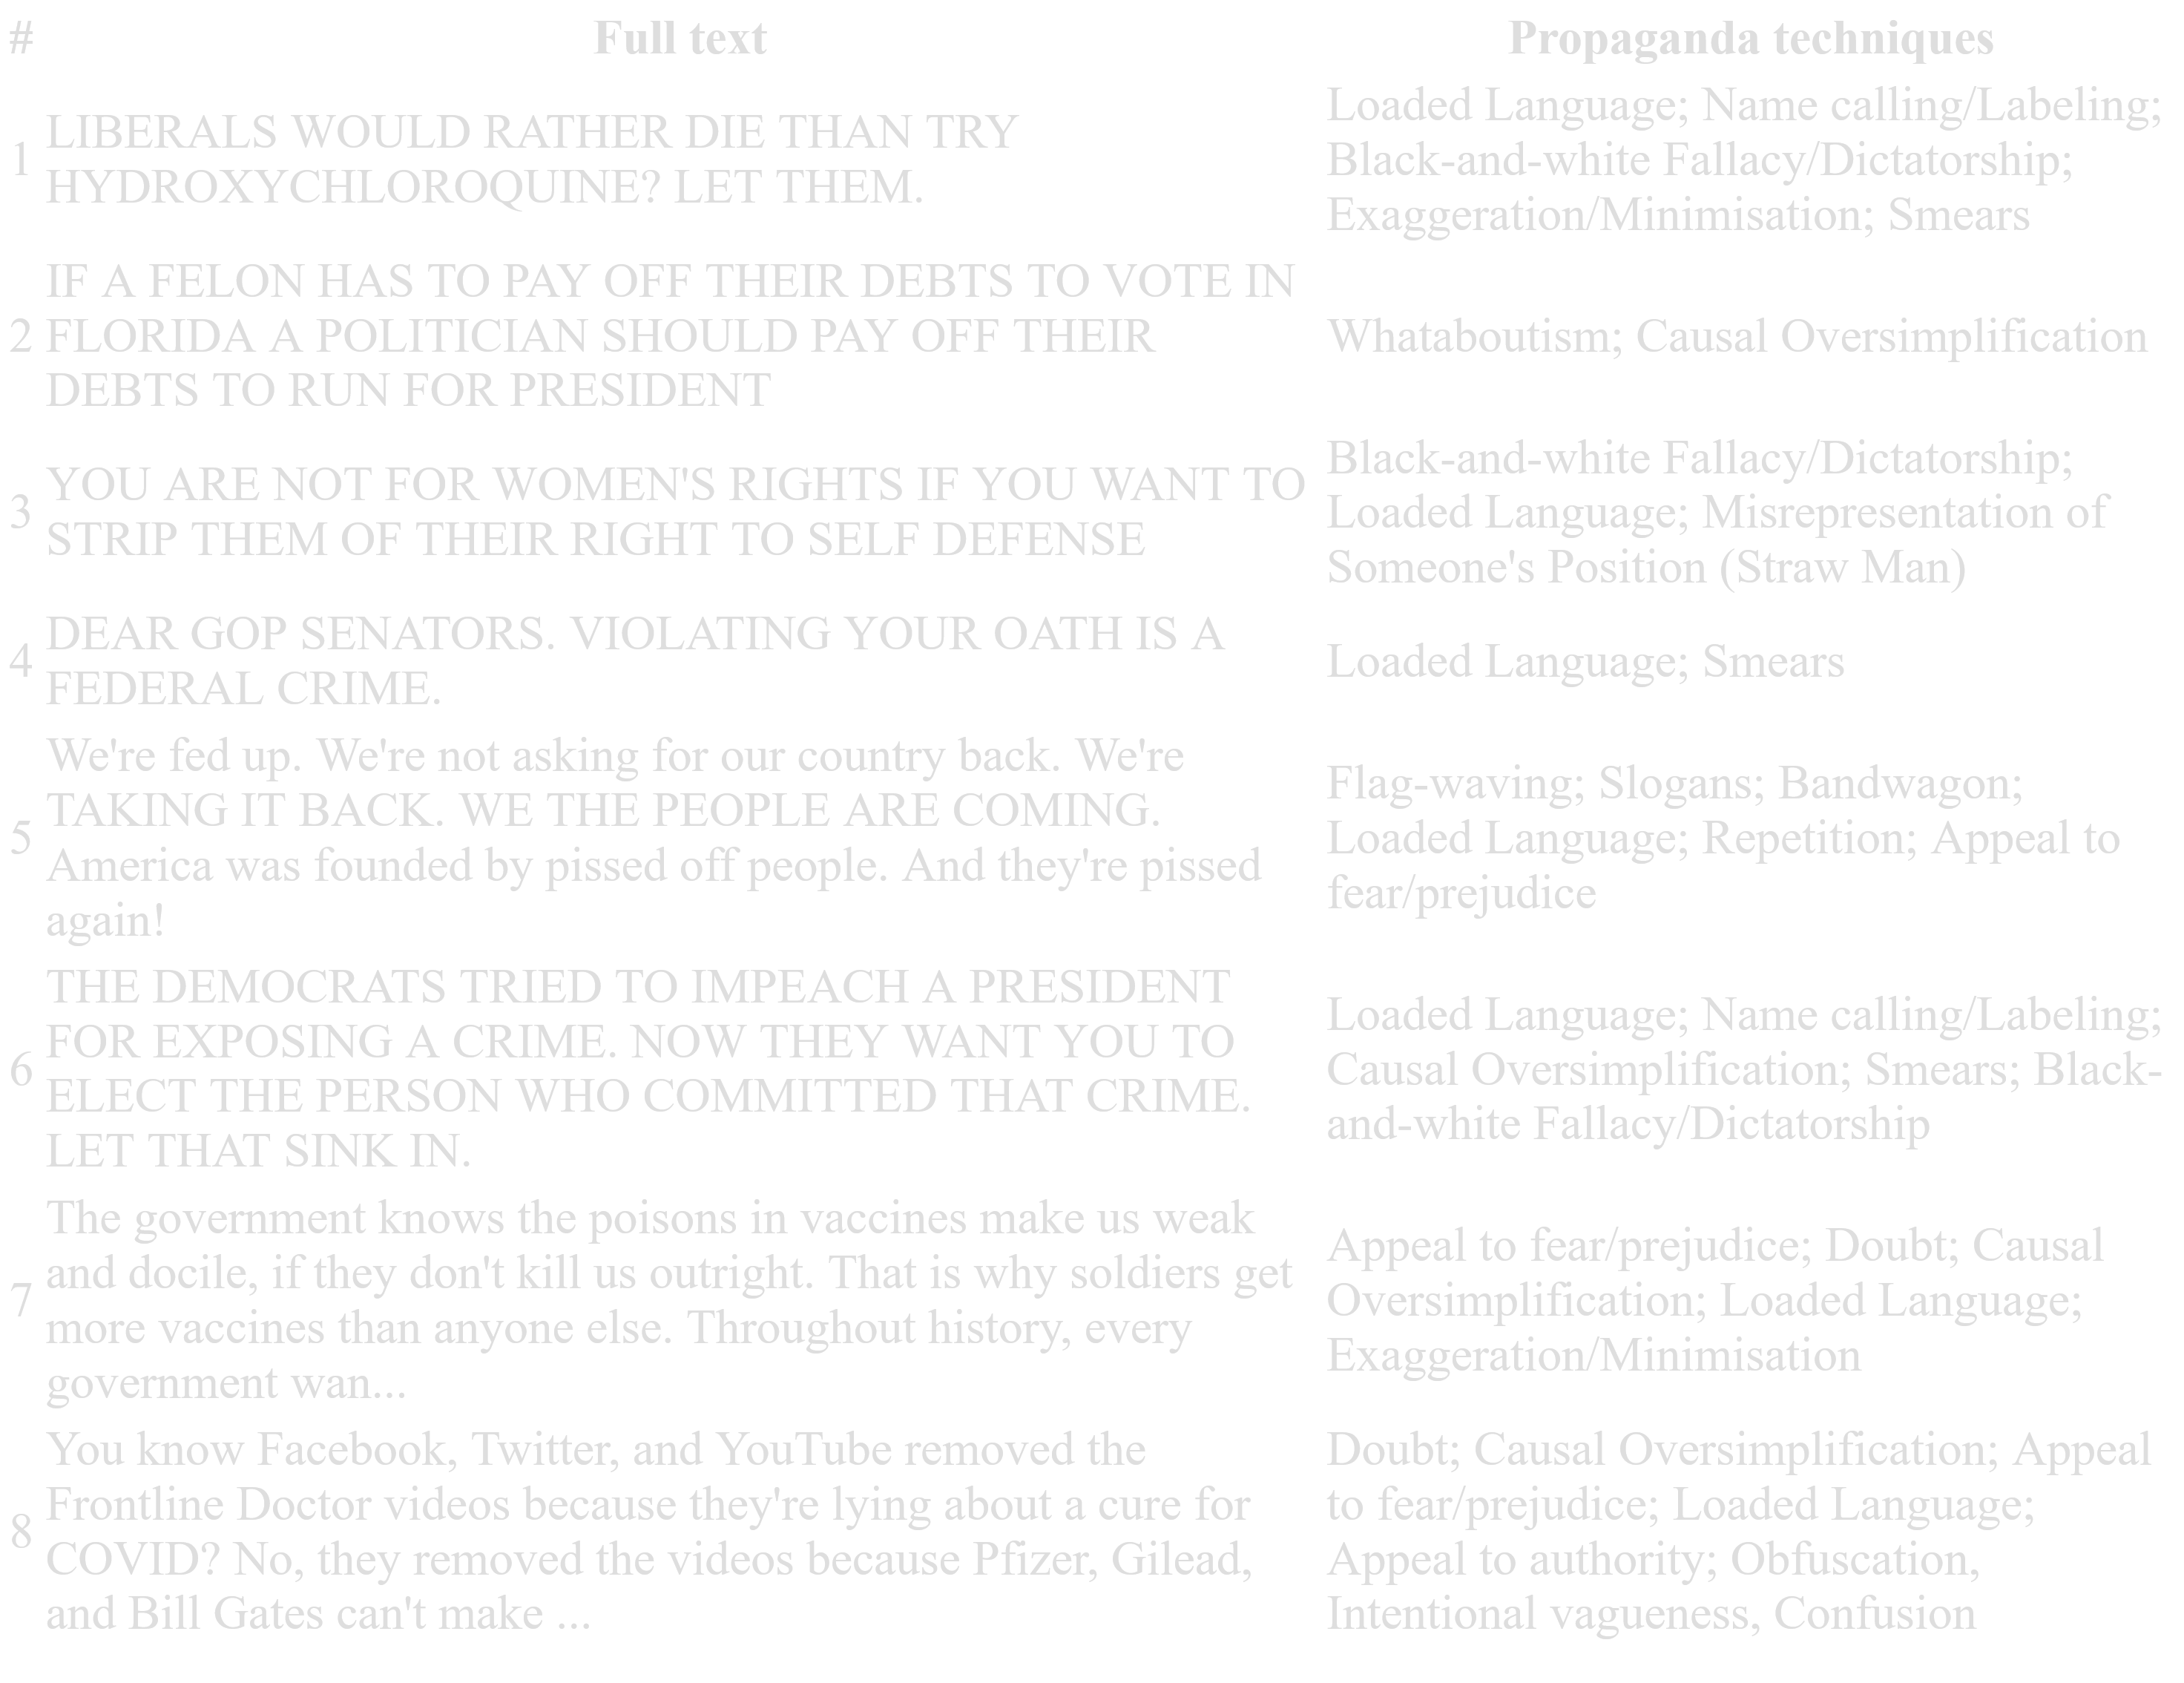

#### Design of this comparison (methods and decision rules, stated before the comparison numbers)

- Three systems, one label space: the gold annotation, our label head at the pre-registered tuned rule (the Predicted sets in the worst-samples cell above), and gpt-5.5 zero-shot (one cloud run, 14/10/2026, prompt and output pasted above, no settings changed). All scoring uses Part A's 20-label space and conventions.
- The subset is fixed to exactly the eight samples in the gpt-5.5 prompt: `test[148]`, `test[135]`, `test[161]`, `test[126]`, `test[16]`, `test[103]`, `test[125]`, `test[149]`. They were selected by our own wrong-label counts, so every number below is conditional on that selection. The question this probe answers is "on the cases we get most wrong, does a general frontier model do better?" - not "which system is better overall". gpt-5.5 was never run on the full test set, and nothing below changes Part A's test results (thr=0.5: micro 0.4265, macro 0.2004; tuned: micro 0.4176, macro 0.2107).

Scoring:

1. Per-sample wrong labels: FP+FN against gold, the same count the worst-samples cell prints for our model. Winner per sample, win/loss/tie totals, mean difference.
2. Subset scores in Part A's convention: micro F1, macro F1 over all 20 labels, exact-match rate, and labels predicted per document against the gold density on the subset.
3. Disagreement decomposition over the 8x20 grid: TP/FP/FN per system; false positives the two systems share vs one-sided; gold labels caught by both, by one system only, and by neither (union recall).

Variability:

- Paired bootstrap over the eight samples (2000 resamples, seed 0): 95% percentile intervals for each system's micro and macro F1, for the gpt-5.5 minus ours difference, and for the mean wrong-label difference. Decision rule: a gap is reported as detected only when the difference interval excludes zero. At n=8 the intervals are wide, and their width is part of the finding.
- Run-to-run variability of gpt-5.5 could not be measured: one cloud run, no seed, no temperature control, no repeat. Our model is deterministic given the checkpoint, so on this subset its only variability is the resampling above.
- Input asymmetries, reported with the results rather than buried: the prompt carried the 200-character previews printed by the cell above (`test[125]` and `test[149]` end mid-sentence), and the pasted taxonomy contains one merge artefact ("DoubtExaggeration/Minimisation"); gpt-5.5 emitted both techniques separately anyway.

The figure cell below draws panel A (per-sample wrong-label counts) and panel B (subset F1s with the bootstrap intervals); both code cells here embed their outputs, so the scoring and the figure are readable without rerunning anything.


In [ ]:
# Our tuned rule label head vs gpt-5.5 zero-shot on the 8 samples in the gpt-5.5 prompt
import numpy as np
from sklearn.metrics import f1_score

assert "test_preds_tuned" in globals(), "run the Part A final evaluation first"
assert "test_labels_arr" in globals(), "run the Part A final evaluation first"

WORST8 = [148, 135, 161, 126, 16, 103, 125, 149]  # exactly the texts sent to gpt-5.5 (prompt cell above)
GPT55 = {
    148: ["Loaded Language", "Name calling/Labeling", "Black-and-white Fallacy/Dictatorship",
          "Exaggeration/Minimisation", "Smears"],
    135: ["Whataboutism", "Causal Oversimplification"],
    161: ["Black-and-white Fallacy/Dictatorship", "Loaded Language",
          "Misrepresentation of Someone's Position (Straw Man)"],
    126: ["Loaded Language", "Smears"],
    16: ["Flag-waving", "Slogans", "Bandwagon", "Loaded Language", "Repetition",
         "Appeal to fear/prejudice"],
    103: ["Loaded Language", "Name calling/Labeling", "Causal Oversimplification", "Smears",
          "Black-and-white Fallacy/Dictatorship"],
    125: ["Appeal to fear/prejudice", "Doubt", "Causal Oversimplification", "Loaded Language",
          "Exaggeration/Minimisation"],
    149: ["Doubt", "Causal Oversimplification", "Appeal to fear/prejudice", "Loaded Language",
          "Appeal to authority", "Obfuscation, Intentional vagueness, Confusion"],
}
for _i, _labs in GPT55.items():
    for _l in _labs:
        assert _l in label2idx, f"test[{_i}]: {_l!r} is outside the 20-label taxonomy"

gold8 = test_labels_arr[WORST8].astype(bool)
ours8 = test_preds_tuned[WORST8].astype(bool)
gpt8 = np.zeros_like(gold8)
for _r, _i in enumerate(WORST8):
    for _l in GPT55[_i]:
        gpt8[_r, label2idx[_l]] = True

wrong_ours = (gold8 != ours8).sum(axis=1)
wrong_gpt = (gold8 != gpt8).sum(axis=1)

print("C2: our label head (tuned rule) vs gpt-5.5 zero-shot on the 8 prompt samples")
print("\nwrong labels per sample (FP+FN vs gold):")
print(f"{'test':>6} {'gold':>5} {'ours':>5} {'gpt':>5} | {'ours':>4} {'gpt':>4} | winner")
for _r, _i in enumerate(WORST8):
    _w = "tie" if wrong_ours[_r] == wrong_gpt[_r] else ("gpt-5.5" if wrong_gpt[_r] < wrong_ours[_r] else "ours")
    print(f"{_i:>6} {gold8[_r].sum():>5} {ours8[_r].sum():>5} {gpt8[_r].sum():>5} | "
          f"{wrong_ours[_r]:>4} {wrong_gpt[_r]:>4} | {_w}")
_wins = int((wrong_gpt < wrong_ours).sum())
_ties = int((wrong_gpt == wrong_ours).sum())
print(f"fewer wrong labels: gpt-5.5 {_wins}/8, tie {_ties}/8, ours {8 - _wins - _ties}/8")
print(f"mean wrong per sample: ours {wrong_ours.mean():.2f}, gpt-5.5 {wrong_gpt.mean():.2f} "
      f"(ours - gpt = {wrong_ours.mean() - wrong_gpt.mean():+.2f})")

def _score(name, p):
    return (name, float(p.sum(axis=1).mean()),
            float(f1_score(gold8, p, average="micro", zero_division=0)),
            float(f1_score(gold8, p, average="macro", zero_division=0)),
            float((gold8 == p).all(axis=1).mean()))

print("\nsubset scores (8 samples, 20-label space, same convention as Part A):")
print(f"{'system':<10} {'labels/doc':>10} {'micro-F1':>9} {'macro-F1':>9} {'exact':>7}")
print(f"{'gold':<10} {gold8.sum(axis=1).mean():>10.2f} {'-':>9} {'-':>9} {'-':>7}")
_rows = [_score("ours", ours8), _score("gpt-5.5", gpt8)]
for _row in _rows:
    print(f"{_row[0]:<10} {_row[1]:>10.2f} {_row[2]:>9.4f} {_row[3]:>9.4f} {_row[4]:>7.3f}")

# disagreement decomposition over the 8x20 label grid
_tp_o = int((gold8 & ours8).sum()); _fp_o = int((ours8 & ~gold8).sum()); _fn_o = int((gold8 & ~ours8).sum())
_tp_g = int((gold8 & gpt8).sum()); _fp_g = int((gpt8 & ~gold8).sum()); _fn_g = int((gold8 & ~gpt8).sum())
_shared_fp = int((ours8 & gpt8 & ~gold8).sum())
_shared_tp = int((ours8 & gpt8 & gold8).sum())
_neither = int(gold8.sum()) - _shared_tp - (_tp_o - _shared_tp) - (_tp_g - _shared_tp)
print(f"\ndisagreement: ours TP {_tp_o} FP {_fp_o} FN {_fn_o} | gpt-5.5 TP {_tp_g} FP {_fp_g} FN {_fn_g}")
print(f"false positives: both {_shared_fp}, ours only {_fp_o - _shared_fp}, gpt-5.5 only {_fp_g - _shared_fp}")
print(f"gold labels caught: both {_shared_tp}, ours only {_tp_o - _shared_tp}, "
      f"gpt-5.5 only {_tp_g - _shared_tp}, neither {_neither} "
      f"(union recall {(_tp_o + _tp_g - _shared_tp) / gold8.sum():.3f})")

# paired bootstrap over the 8 samples (seed 0, B=2000): variability of the comparison
_rng = np.random.default_rng(0)
_B = 2000
c2_boot = {k: np.empty(_B) for k in ("m_o", "m_g", "M_o", "M_g", "d_micro", "d_macro", "d_wrong")}
for _b in range(_B):
    _ix = _rng.integers(0, len(WORST8), len(WORST8))
    _mo = float(f1_score(gold8[_ix], ours8[_ix], average="micro", zero_division=0))
    _mg = float(f1_score(gold8[_ix], gpt8[_ix], average="micro", zero_division=0))
    _Mo = float(f1_score(gold8[_ix], ours8[_ix], average="macro", zero_division=0))
    _Mg = float(f1_score(gold8[_ix], gpt8[_ix], average="macro", zero_division=0))
    c2_boot["m_o"][_b], c2_boot["m_g"][_b] = _mo, _mg
    c2_boot["M_o"][_b], c2_boot["M_g"][_b] = _Mo, _Mg
    c2_boot["d_micro"][_b] = _mg - _mo
    c2_boot["d_macro"][_b] = _Mg - _Mo
    c2_boot["d_wrong"][_b] = wrong_ours[_ix].mean() - wrong_gpt[_ix].mean()

def _ci(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return lo, hi

print(f"\npaired bootstrap (B={_B}, seed 0), 95% percentile intervals:")
for _lab, _k, _k2, _pt_o, _pt_g in [
        ("micro-F1", "m_o", "m_g", _rows[0][2], _rows[1][2]),
        ("macro-F1", "M_o", "M_g", _rows[0][3], _rows[1][3])]:
    _lo_o, _hi_o = _ci(c2_boot[_k]); _lo_g, _hi_g = _ci(c2_boot[_k2])
    _lo_d, _hi_d = _ci(c2_boot["d_micro" if _k == "m_o" else "d_macro"])
    print(f"  {_lab:<9} ours {_pt_o:.4f} [{_lo_o:.4f}, {_hi_o:.4f}] | "
          f"gpt-5.5 {_pt_g:.4f} [{_lo_g:.4f}, {_hi_g:.4f}] | "
          f"diff (gpt-ours) {_pt_g - _pt_o:+.4f} [{_lo_d:+.4f}, {_hi_d:+.4f}]")
_lo, _hi = _ci(c2_boot["d_wrong"])
print(f"  mean wrong labels  diff (ours-gpt) {wrong_ours.mean() - wrong_gpt.mean():+.3f} [{_lo:+.3f}, {_hi:+.3f}]")

c2_pt = {"micro_ours": _rows[0][2], "micro_gpt": _rows[1][2],
         "macro_ours": _rows[0][3], "macro_gpt": _rows[1][3]}


C2: our label head (tuned rule) vs gpt-5.5 zero-shot on the 8 prompt samples

wrong labels per sample (FP+FN vs gold):
  test  gold  ours   gpt | ours  gpt | winner
   148     3     6     5 |    9    6 | gpt-5.5
   135     1    10     2 |    9    1 | gpt-5.5
   161     2     9     3 |    9    3 | gpt-5.5
   126     2    11     2 |    9    2 | gpt-5.5
    16     4    11     6 |    9    6 | gpt-5.5
   103     4    11     5 |    9    5 | gpt-5.5
   125     2    11     5 |    9    5 | gpt-5.5
   149     2    10     6 |    8    8 | tie
fewer wrong labels: gpt-5.5 7/8, tie 1/8, ours 0/8
mean wrong per sample: ours 8.88, gpt-5.5 4.50 (ours - gpt = +4.38)

subset scores (8 samples, 20-label space, same convention as Part A):
system     labels/doc  micro-F1  macro-F1   exact
gold             2.50         -         -       -
ours             9.88    0.2828    0.1404   0.000
gpt-5.5          4.25    0.3333    0.1417   0.000

disagreement: ours TP 14 FP 65 FN 6 | gpt-5.5 TP 9 FP 25 FN 11
false pos

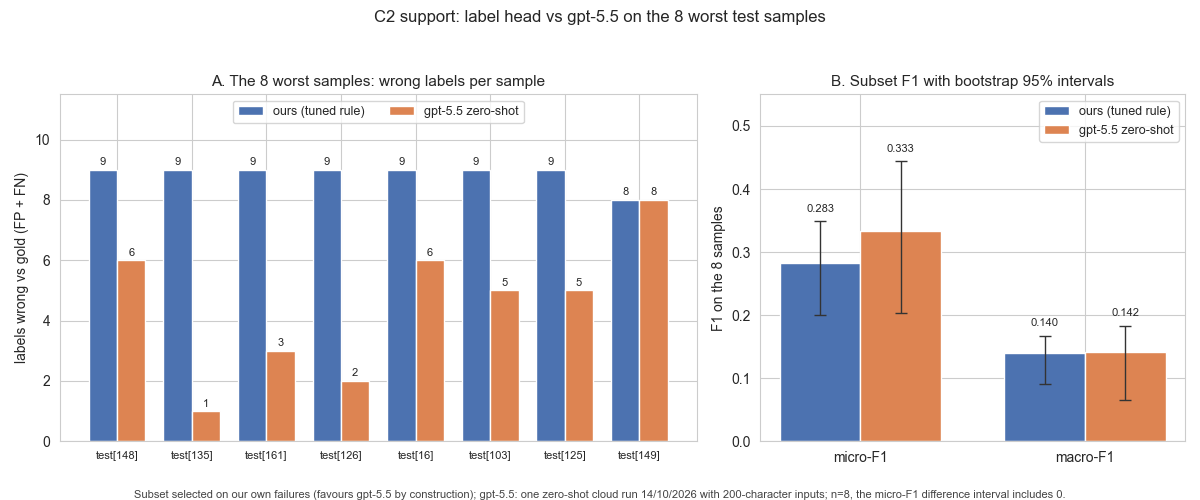

In [ ]:
# C2 supporting figure: wrong-label counts and subset F1 with bootstrap intervals
import numpy as np
import matplotlib.pyplot as plt

for _v in ("c2_pt", "c2_boot", "wrong_ours", "wrong_gpt", "WORST8"):
    assert _v in globals(), f"run the C2 scoring cell first ({_v} missing)"
try:
    import seaborn as _sns
    _sns.set_style("whitegrid")
except Exception:
    plt.style.use("ggplot")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.5, 1]})

# panel A: wrong labels per sample, ours vs gpt-5.5
_x = np.arange(len(WORST8))
_w = 0.38
ax1.bar(_x - _w / 2, wrong_ours, width=_w, color="#4C72B0", label="ours (tuned rule)")
ax1.bar(_x + _w / 2, wrong_gpt, width=_w, color="#DD8452", label="gpt-5.5 zero-shot")
for _i in range(len(WORST8)):
    ax1.text(_x[_i] - _w / 2, wrong_ours[_i] + 0.15, str(int(wrong_ours[_i])), ha="center", fontsize=8)
    ax1.text(_x[_i] + _w / 2, wrong_gpt[_i] + 0.15, str(int(wrong_gpt[_i])), ha="center", fontsize=8)
ax1.set_xticks(_x)
ax1.set_xticklabels([f"test[{i}]" for i in WORST8], fontsize=8)
ax1.set_ylim(0, 11.5)
ax1.set_ylabel("labels wrong vs gold (FP + FN)")
ax1.set_title("A. The 8 worst samples: wrong labels per sample", fontsize=11)
ax1.legend(fontsize=9, loc="upper center", ncol=2)

# panel B: subset F1s with paired-bootstrap 95% intervals
_pts = [("micro-F1", c2_pt["micro_ours"], c2_pt["micro_gpt"], "m_o", "m_g"),
        ("macro-F1", c2_pt["macro_ours"], c2_pt["macro_gpt"], "M_o", "M_g")]
_x2 = np.arange(2)
_w2 = 0.36
for _k, (_lab, _po, _pg, _ko, _kg) in enumerate(_pts):
    for _s, (_pt, _key, _col) in enumerate([(_po, _ko, "#4C72B0"), (_pg, _kg, "#DD8452")]):
        _lo, _hi = np.percentile(c2_boot[_key], [2.5, 97.5])
        _cx = _x2[_k] + (_s - 0.5) * _w2
        _lbl = ("ours (tuned rule)" if _k == 0 and _s == 0 else
                "gpt-5.5 zero-shot" if _k == 0 and _s == 1 else None)
        ax2.bar(_cx, _pt, width=_w2, color=_col, label=_lbl)
        ax2.errorbar(_cx, _pt, yerr=[[_pt - _lo], [_hi - _pt]], fmt="none",
                     ecolor="#333333", capsize=4, linewidth=1)
        ax2.text(_cx, _hi + 0.015, f"{_pt:.3f}", ha="center", fontsize=8)
ax2.set_xticks(_x2)
ax2.set_xticklabels([p[0] for p in _pts], fontsize=10)
ax2.set_ylim(0, 0.55)
ax2.set_ylabel("F1 on the 8 samples")
ax2.set_title("B. Subset F1 with bootstrap 95% intervals", fontsize=11)
ax2.legend(fontsize=9, loc="upper right")

fig.suptitle("C2 support: label head vs gpt-5.5 on the 8 worst test samples", fontsize=12)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
fig.text(0.5, 0.005,
         "Subset selected on our own failures (favours gpt-5.5 by construction); gpt-5.5: one zero-shot cloud run "
         "14/10/2026 with 200-character inputs; n=8, the micro-F1 difference interval includes 0.",
         ha="center", fontsize=8, color="#444444")


#### What the comparison shows

Scores (scoring cell and figure above; rules fixed in the design cell above them):

- Per-sample wrong labels: gpt-5.5 is closer to gold on seven of the eight samples and ties on one (`test[149]`, eight wrong labels each); it is never worse. Mean wrong labels per sample: ours 8.88, gpt-5.5 4.50; difference +4.375 with paired-bootstrap 95% interval [+2.750, +6.000] - detected.
- The gap is density, not recall. We predict 9.88 labels per sample against gold's 2.50 on this subset - the Part A over-prediction pathology, concentrated on exactly the samples selected for it; gpt-5.5 predicts 4.25. On F1 the picture flattens: micro F1 ours 0.2828 [0.2000, 0.3487] vs gpt-5.5 0.3333 [0.2041, 0.4444], difference +0.0505 [-0.0818, +0.1890] - not detected, the interval includes zero. Macro F1 0.1404 vs 0.1417, difference +0.0013 [-0.0783, +0.0628] - no separation. Neither system exact-matches one of the eight samples (0/8 each).
- The errors are complementary, not nested. Ours: TP 14, FP 65, FN 6. gpt-5.5: TP 9, FP 25, FN 11. Of our six missed gold labels gpt-5.5 catches one; of its eleven missed gold labels we catch six. The systems share 15 false positives (ours only 50, gpt-5.5 only 10): both over-fire on the same frequent surface labels. Between them they catch 15 of the 20 gold labels on this subset (union recall 0.750); five gold labels defeat both.
- Reading for the committee: on our own worst cases a much larger zero-shot model is closer to gold per document, and we report that plainly. But it does not outscore us on F1 here - the difference interval includes zero at n=8 - it misses gold labels we catch, and it shares the over-prediction habit (4.25 labels per document against gold's 2.50, exact match 0/8). The defensible position is not "we beat gpt-5.5". It is: these eight cases defeat both systems; our failure mode is concentrated and diagnosable (calibration, per the Part A conclusions) while the challenger's settings are out of our control and its single run cannot be repeated here; the two systems' errors are complementary (union recall 0.75), so a product should abstain or escalate on exactly this profile instead of printing a label set; and our detector runs locally on 66M parameters at a fraction of a frontier-model call - a deployment fact, not an accuracy claim.
- Limits of this probe: eight samples selected on our own errors, so the subset favours gpt-5.5 by construction and the F1 intervals are wide enough to hide real differences; one gpt-5.5 run with uncontrolled settings, so its run-to-run variability is unmeasured; two of the eight inputs reached it truncated mid-sentence; gold is sparse on these samples (2.50 labels per document against 1.67 across the test set), so a handful of annotation judgement calls swings the counts. No number here changes or extends any full-test-set claim.

So, in summary these 8 cases defeat the Part A system and the gpt-5.5 system. However, Part A is diagnosable, gpt-5.5's single run cannot be replicated which is why the department should continue paying for what I built.

### C3. Does the label head agree with the span head?

#### What the tool does when the two heads disagree (product rules)

The product situation is concrete: the teacher sees a technique chip from the label head (Part A) and, ideally, an underlined passage from the span head (Part B). When the model says Name calling/Labeling and the tagger underlines nothing, the teacher holds a label with nothing to point at. This section fixes what the screen shows in each of the four states the two heads can fall into. How often each state occurs is not measured here; the rules below were chosen to be correct under any frequency, and they lean on facts already established in this notebook and in the release files.

- Pairing. The task1 and task2 test files ship the same 200 documents in the same order (identical ids and texts), and both parts derive their technique vocabulary as the sorted 20-name list - Part B's own integrity check printed "matches task1 vocabulary: True". Document index i is one document for both heads, technique index t one technique for both, so every label can in principle be paired with a span of the same technique.
- The gold anchor. In the release itself every task1 test label has at least one task2 span of the same technique and vice versa: 335 labels, 335 span techniques, 0 unpointed in either direction (verified on the release files). Gold never hands the teacher a label with nothing to point at, so a label without a span is always a state the model created, never one the corpus intends.
- Claim ownership. The label head owns the claim: its tuned test micro F1 is 0.4176, the span head's primary-rule test micro F1 is 0.0310. The span head is a pointer, not a co-owner. Its silence is weak evidence against a label - Part B's own error decomposition found 63.3% of its error events were spurious spans under the primary rule, so both what it underlines and what it misses are unreliable at the margin.

The four states, and what the screen shows:

- Both heads positive: the designed case - technique chip and underlined passage together, with the underline worded as the passage the model associates with the technique, not as proof.
- Label, nothing to point at: the technique chip with no underline and the note "no passage identified". The claim stands: the claim owner made it, and because gold never produces this state, it means the tool failed to locate words, not that the document lacks them. Drawing a substitute underline would put text on screen that no part of the system endorsed.
- Span, no label: nothing on screen - no chip, no underline. The claim owner did not make the claim, and this is exactly where Part B measured the span head's errors to live. If a later build keeps such spans at all, they may sit in a collapsed view and never carry a technique name.
- Neither: nothing. Most pairs land here and the screen stays quiet.

The rules accept one real cost: a genuine passage found by the span head for a technique the label head missed goes unshown. This deliverable does not measure how often that happens; the trade is revisitable if Part B's test recall improves.

Limits, stated with the rules: the two heads were tuned independently on their own objectives (document-label macro F1 for Part A, span F1 for Part B), never jointly, so disagreement is expected by construction; the rules are design decisions, not measured optima, and the frequencies they trade off are not quantified here; thresholds behind both heads are point estimates from single dev sweeps, and test was scored once per head under both pre-registrations.


### C4. Will it work here?

#### The gap, identified

The scenario: an Australian secondary classroom, 2026. Year 10 students bring memes from their own feeds, and the teacher wants the tool to name propaganda techniques in them. Everything this system is was built on the SemEval-2021 Task 6 release: 2020 US-election meme text, shouty ALL-CAPS caption register (42.5% of train and 44.6% of test alphabetic tokens are capitals), US political actors, text only - no images, no stance, no platform metadata (C1). The gap is the distance between that world and a Year 10 student's feed. It is not one gap; it is at least six, and they compound:

1. Actors and frames. The corpus names Trump, Biden and the US parties; it names no Australian figure, party or institution. What the model knows about political argument it knows through US 2020 figures - including the two side-asymmetries C1 measured (content naming left-wing actors is smear-heavy, content naming right-wing actors is virtue-claim-heavy). Those fingerprints have no natural home in Australian politics; if they fire here they fire by surface resemblance, not understanding.
2. Register and platform. The corpus is static image-macro captions; a 2026 feed is TikTok and Reels screenshots, lowercase posts, emoji runs, slang, AI-generated images and video. C1 already showed the tool is a specialist in one register; on everything else this evaluation measured no degradation curve at all.
3. The input channel. The deliverable consumes text; a feed serves images. A real deployment adds an OCR step this project never tested, and OCR errors land directly in the tokens the model sees. The tokenizer is English-only and uncased: code-switched or non-English text, common in Australian classrooms, passes through as fragments or [UNK], and the ALL-CAPS shouting that is a learned cue in the corpus does not survive contact with other sources.
4. Base rates and calibration. Thresholds were tuned on the source dev split; confidence is uncalibrated anywhere else. The label head already over-predicts on its own test set - 3.79 chips per document against gold 1.67, over-predicting on 150 of 200 - and on shifted input the error direction is the same while the magnitude is unknown.
5. No pointers. The span head's primary-rule test micro F1 is 0.0310, so in the classroom the C3 "label, nothing to point at" state is the normal case, not the exception. Every chip is an unsupported claim on screen.
6. Time. The base model's world knowledge ends in 2019; the fine-tune's world is 2020 US memes. By 2026 the actors, events and formats have moved on twice over.

What it means for the teacher running the lesson:

- Adjudication load with no evidence to check against. Mean 3.79 chips per document (9 on the worst samples), 20 techniques, no explanations and no passages (point 5). The teacher is the only validator of a confident-looking system, mid-lesson, with no time and no training in the taxonomy.
- Neutrality. Australian education systems expect teachers to keep political neutrality in the classroom (state codes vary - check yours). C1 measured that the corpus left two side-attached fingerprints on the model. A tool that treats one flavour of rhetoric as smear-prone is a liability in a room where the teacher must not take sides - and because the fingerprint is US-derived, it may attach to Australian families almost at random.
- Authority of the screen. Chips rendered next to a student's material read as verdicts. Students and teachers both read model output as measurement; it is a guess with a tuned test micro F1 of 0.4176 on its own distribution.
- The defensible lesson. The honest curriculum use inverts deployment: the tool is the object of study - whose errors, which side, what is a technique - and the students' memes are never the object of the tool.

What it means for a student whose family's politics appear on screen with a label attached:

- The mechanism. A meme from home is shown; chips appear beside it. Chips describe text, but in a classroom they land on the person - the student, the family. Because the label head over-predicts (point 4), most chips on any given document are wrong: the screen has just attached authoritative-sounding propaganda labels to a family's politics, inaccurately.
- Not random which families. C1's asymmetries attach to political flavours, and its census found the corpus contains near-zero content about muslim, jewish, refugee or immigrant topics (0 test units each). A student whose family's meme comes from one of those communities is maximally out of distribution: the chips there are unvetted guesses with no measured error rate at all.
- Permanence and chilling. Screenshots outlive the lesson; students learn that bringing outside material invites labeling; a family becomes "the propaganda example". The cost falls hardest on the students least equipped to argue back.
- Safeguards that follow from the above. Never run student-origin material through the tool on a shared screen - use public figures and news material. Frame every chip as the model's guess, to be argued with, not a finding. Anonymise, offer opt-out, and run the model locally so no student text leaves the device (a 66M-parameter model runs on a school laptop). Use the tally protocol below so students evaluate the tool instead of being measured by it.

Getting evidence without a labelled Australian dataset (instruments pre-registered here, before any numbers):

1. Coverage census (corpus side, no model). Match the release text against a fixed list of Australian civic names - albanese, dutton, morrison, turnbull, howard, keating, gillard, rudd, abbott, hanson, palmer, bandt, wong, katter, berejiklian, perrottet, minns, andrews, allan, jacinta, sussan, nampijinpa, one nation, liberal party, labor party, labour party, australian greens, plus the capitalised forms Labor, Greens, Coalition, Referendum, Anzac - against C1's US actor list as the reference scale. False-friend common nouns are counted only in capitalised proper-noun form, and every Australian hit is printed for inspection. Evidence value: how much of the model's political world is Australian.
2. Tokeniser fragmentation (input layer, no labels). Mean DistilBERT wordpieces per word, and the share of words split into three or more pieces, on: the first 50 corpus test documents (the world the model knows), a US actor reference list (trump, biden, pelosi, schumer, hillary, mcconnell, kushner, maga, gop, aoc), the Australian civic list above, and a pre-registered 2026 Australian register list (arvo, barbie, brekkie, servo, esky, thongs, bottlo, mozzie, sunnies, maccas, quokka, wombat, didgeridoo, anzac, footy, cooked, slay, vibes, ratio, stan, cope, based, ick, delulu, bestie, mid, ghosting), plus a [UNK] count on an emoji string. Evidence value: how the input layer mangles the new world. This is input-space evidence, not end-task evidence, and is scoped as such.
3. Negative-control firing (model side, no labels). Rebuild Part A's test state exactly from the transferred checkpoints (trial_6.pt then final_model.pt, with the notebook's own cleaning, tokenisation and threshold sweep), gated: the reproduced test metrics must equal the reported ones to four decimals (thr=0.5 micro 0.4265 / macro 0.2004; tuned micro 0.4176 / macro 0.2107), or the cell withdraws and reports nothing further. Then run the tuned-rule label head on neutral controls: 22 texts written to a fixed recipe - public-notice register, no evaluative adjectives, entities are places, services and organisations, at most 25 words, constructed by the author as synthetic stand-ins for mundane Australian text (the cell checks the recipe mechanically). A detector that chips placebo text fires on anything; the chip rate there is the false-alarm floor on content with no persuasion in it at all. Secondary, descriptive-only probe: six Australian opinion texts, author-written with no gold, reported without any accuracy claim. Limitation disclosed here: the controls are synthetic and author-written, not a sample of any real feed; they measure the floor, not classroom performance.
4. The instrument for the real deployment (designed here, run later by the teacher): a class tally with a gate. The teacher curates a small consented sample of public (not peer) material; for each chip the class votes on whether the label fits the text and why; the tally is the evidence. Pre-set gate: until the share of chips judged to fit reaches 60% on that sample, the tool is shown only as a foil - chips visible as the model's guesses to argue against - never as a claim about anyone's material. The tally doubles as the curriculum object (digital technologies with civics) and turns the deployment question into a measured one before any labelled dataset exists.

What each instrument can and cannot show: 1 and 2 are corpus and input-layer facts - they establish that the new world is absent from the training distribution and mangled by its front end, not how end-task F1 would move; 3 measures the model's behaviour on constructed inputs - a floor, not a rate on real memes; 4 is the only instrument that touches the real classroom, and it is deliberately placed in the teacher's hands.


In [ ]:
# Does it work here? Australian Year 10, 2026 feed. Label-free evidence instruments:
# coverage census, tokeniser fragmentation, negative-control firing (all lists pre-registered
# in the design cell). Rebuilds Part A's test state exactly from the transferred checkpoints,
# gated on the reported metrics; needs train_data/dev_data/test_data and the two .pt files.
import os
import re as _re
import numpy as np
import torch
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from sklearn.metrics import f1_score

for _f in ("trial_6.pt", "final_model.pt"):
    assert os.path.exists(_f), f"missing {_f} (transferred checkpoint) - place it next to the notebook and re-run"
assert all(_k in globals() for _k in ("train_data", "dev_data", "test_data")), "run the Part A data cells first"
_c4_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _c4_clean(text):
    text = text.replace("\n", " ")
    text = _re.sub(r"http\S+|www\.\S+", "[URL]", text)
    text = _re.sub(r"<.*?>", "", text)
    text = _re.sub(r"\s+", " ", text)
    return text.strip()


_LABELS = sorted({l for _split in (train_data, dev_data) for _s in _split for l in _s["labels"]})
_dev_y = np.array([[1.0 if l in _s["labels"] else 0.0 for l in _LABELS] for _s in dev_data], dtype=np.float32)
_test_y = np.array([[1.0 if l in _s["labels"] else 0.0 for l in _LABELS] for _s in test_data], dtype=np.float32)

_tok = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")


def _enc(texts):
    return _tok([_c4_clean(t) for t in texts], truncation=True, max_length=128,
                padding="max_length", return_tensors="pt")


_dev_enc, _test_enc = _enc([s["text"] for s in dev_data]), _enc([s["text"] for s in test_data])


def _probs(m, enc, bs=16):
    m.eval()
    _out = []
    with torch.no_grad():
        for i in range(0, len(enc["input_ids"]), bs):
            _log = m(input_ids=enc["input_ids"][i:i + bs].to(_c4_dev),
                     attention_mask=enc["attention_mask"][i:i + bs].to(_c4_dev)).logits
            _out.append(torch.sigmoid(_log).cpu())
    return torch.cat(_out).numpy()


_c4_model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=len(_LABELS),
    problem_type="multi_label_classification", dropout=0.3)
_c4_model.to(_c4_dev)
_c4_model.load_state_dict(torch.load("trial_6.pt", map_location=_c4_dev))
_P_dev = _probs(_c4_model, _dev_enc)

# the notebook's sweep, verbatim (grid 0.10-0.95, MIN_DEV_SUPPORT=5, first-max argmax)
_GRID = np.round(np.arange(0.10, 0.951, 0.05), 2)
_c4_thr = np.full(len(_LABELS), 0.5, dtype=float)
_sup = _dev_y.sum(axis=0)
for _j in range(len(_LABELS)):
    if _sup[_j] < 5:
        continue
    _bf, _bt = -1.0, 0.5
    for _t in _GRID:
        _f = f1_score(_dev_y[:, _j], (_P_dev[:, _j] >= _t).astype(int), zero_division=0)
        if _f > _bf:
            _bf, _bt = _f, _t
    _c4_thr[_j] = _bt

_c4_model.load_state_dict(torch.load("final_model.pt", map_location=_c4_dev))
_P_test = _probs(_c4_model, _test_enc)
_test_tuned = (_P_test >= _c4_thr).astype(int)
_test_05 = (_P_test >= 0.5).astype(int)


# gate: exact reproduction of the reported test metrics, or the evidence is withdrawn
def _m4(y, p):
    return f1_score(y, p, average="micro", zero_division=0), f1_score(y, p, average="macro", zero_division=0)


_g05, _gtn = _m4(_test_y, _test_05), _m4(_test_y, _test_tuned)
print("gate: rebuilt Part A state vs reported test metrics")
print(f"  thr=0.5  micro {_g05[0]:.4f} (reported 0.4265)  macro {_g05[1]:.4f} (reported 0.2004)")
print(f"  tuned    micro {_gtn[0]:.4f} (reported 0.4176)  macro {_gtn[1]:.4f} (reported 0.2107)")
assert (f"{_g05[0]:.4f}", f"{_g05[1]:.4f}", f"{_gtn[0]:.4f}", f"{_gtn[1]:.4f}") == \
       ("0.4265", "0.2004", "0.4176", "0.2107"), \
    "reproduction missed the reported numbers - C4 model-side evidence withdrawn"
print(f"gate passed: exact four-decimal reproduction "
      f"(tuned test chips/doc: {_test_tuned.sum(axis=1).mean():.2f}, gold: {_test_y.sum(axis=1).mean():.2f})\n")

# instrument 1: coverage census (pre-registered lists from the design cell)
_US = _re.compile(r"\b(trumps?|maga|pence|mcconnell|kushner|republicans?|gop|conservatives?|right[- ]wing|"
                  r"bidens?|kamala|harris|obamas?|pelosi|schumer|hillary|clintons?|sanders|bernie|"
                  r"democrats?|liberals?|aoc|ocasio|bloomberg|buttigieg|klobuchar|warren|"
                  r"progressives?|left[- ]wing|squad)\b", _re.I)
_AU = _re.compile(r"\b(albanese|dutton|morrison|turnbull|howard|keating|gillard|rudd|abbott|hanson|palmer|"
                  r"bandt|wong|katter|berejiklian|perrottet|minns|andrews|allan|jacinta|sussan|nampijinpa|"
                  r"one nation|liberal party|labor party|labour party|australian greens)\b", _re.I)
_AU_CAP = _re.compile(r"\b(Labor|Greens|Coalition|Referendum|Anzac)\b")
print("coverage census (documents naming >=1 actor, release text):")
for _nm, _split in (("train", train_data), ("dev", dev_data), ("test", test_data)):
    _us = sum(1 for d in _split if _US.search(d["text"]))
    _au_docs = [d for d in _split if _AU.search(d["text"]) or _AU_CAP.search(d["text"])]
    _note = "  hits: " + "; ".join(repr(d["text"][:50]) for d in _au_docs[:3]) if _au_docs else ""
    print(f"  {_nm:5s}  US actor {_us:3d}/{len(_split)}   AU actor {len(_au_docs):3d}/{len(_split)}{_note}")

# instrument 2: tokeniser fragmentation
def _frag(words):
    _w = [w.lower() for w in words]
    _tp = [_tok.tokenize(w) for w in _w]
    _n = sum(len(t) for t in _tp)
    _u = sum(1 for t in _tp for p in t if p == "[UNK]")
    _g3 = sum(1 for t in _tp if len(t) >= 3)
    return len(_w), _n / max(len(_w), 1), 100.0 * _g3 / max(len(_w), 1), 100.0 * _u / max(len(_w), 1)


_words_corpus = [w for d in test_data[:50] for w in _re.findall(r"[A-Za-z']+", _c4_clean(d["text"]))]
_words_au = ("albanese dutton morrison turnbull bandt perrottet berejiklian nampijinpa quokka wombat "
             "didgeridoo mozzie bottlo brekkie arvo esky sunnies maccas servo footy anzac").split()
_words_reg = "cooked slay vibes ratio stan cope based ick delulu bestie mid ghosting".split()
_words_us = "trump biden pelosi schumer hillary mcconnell kushner maga gop aoc".split()
print("\ntokeniser fragmentation (alphabetic words):")
for _nm, _ws in (("corpus test sample", _words_corpus), ("US actor list", _words_us),
                 ("AU civic list", _words_au), ("AU 2026 register list", _words_reg)):
    _n, _ppw, _g3, _un = _frag(_ws)
    print(f"  {_nm:<22} n={_n:5d}  pieces/word {_ppw:.2f}  >=3 pieces {_g3:5.1f}%  [UNK] {_un:4.1f}%")
_emb = _tok.tokenize("🔥💀🗿😭😂🤣")
print(f"  emoji string           tokenises to {len(_emb)} pieces, "
      f"{sum(1 for p in _emb if p == '[UNK]')} [UNK] ({_emb[:6]})")

# instrument 3: negative-control firing (recipe pre-registered in the design cell)
NEUTRAL = [
    "Sunny across Perth today with a top of 31 degrees and light coastal winds.",
    "Fremantle defeated Geelong by 12 points at Optus Stadium on Saturday.",
    "The 7:42 train to the city will run a replacement bus between Footscray and Sunshine this weekend.",
    "Geelong Library is open 9 to 5 on weekdays during the school holidays.",
    "Green waste bins are collected every second Wednesday from April. Bins out by 7 am.",
    "Water main works on High Street reduce the lane to one direction between 9 and 3 on Thursday.",
    "Year 10 parents can collect report cards from the front office on Friday.",
    "The clinic offers flu vaccinations weekdays without appointment at the Bendigo site.",
    "Speed limits on the ring road drop to 80 while barriers are replaced this month.",
    "The farmers market runs Sunday from 8 am at the showgrounds. Cards and cash accepted.",
    "Ferries to the island run hourly in winter. The last boat leaves at 5:15 pm.",
    "Victoria batted first and made 7 for 288. Play resumes at 10 am on day two.",
    "The pool closes for maintenance from Monday and reopens the following Saturday.",
    "Rubbish collection moves to Thursday next week for the long weekend.",
    "The community hall is available for booking through the council website.",
    "School photos will be taken in week 3. Orders close at the end of term.",
    "The footpath on King Street is closed for resurfacing between 7 am and 4 pm.",
    "Bus route 41 will detour via Russell Street while the bridge is inspected.",
    "The annual show opens on Friday at the showgrounds. Entry is by gold coin.",
    "Recycling bins are collected fortnightly on Tuesdays in this suburb.",
    "The weather bureau expects rain from Wednesday and cooler mornings.",
    "The museum is free on the first Sunday of each month. Bookings are not needed.",
]
OPINION = [
    "Honestly the new station is a waste of money when the hospital still needs beds.",
    "If you support the voice you support division. One country, one law.",
    "Boycott the duopoly, shop local and watch the prices drop.",
    "Every generation whinges about fuel prices, and mine paid forty cents.",
    "Stop complaining about the heat. Try a week in Katherine in November.",
    "They promised the roads would be fixed before the election. They always do.",
]
assert len(NEUTRAL) == 22 and all(len(t.split()) <= 25 for t in NEUTRAL), "recipe violation in NEUTRAL"
assert len(OPINION) == 6


def _fire(texts):
    _e = _enc(texts)
    _p = _probs(_c4_model, _e)
    return (_p >= _c4_thr).astype(int), (_p >= 0.5).astype(int), _p


_neu_t, _neu_05, _neu_p = _fire(NEUTRAL)
_opi_t, _opi_05, _opi_p = _fire(OPINION)
_lab_ct = _neu_t.sum(axis=1)
_test_ct = _test_tuned.sum(axis=1)
print("\nnegative controls (tuned rule; recipe-checked: 22 texts, <=25 words, no evaluative adjectives):")
print(f"  neutral: mean chips/doc {_lab_ct.mean():.2f}   (source test mean {_test_ct.mean():.2f}, gold {_test_y.sum(axis=1).mean():.2f})")
print(f"  neutral at thr=0.5: mean chips/doc {_neu_05.sum(axis=1).mean():.2f}")
print(f"  neutral docs with >=1 chip: {int((_lab_ct >= 1).sum())}/22; with >=3: {int((_lab_ct >= 3).sum())}/22")
_top = _neu_t.sum(axis=0)
for _j in np.argsort(-_top)[:6]:
    if _top[_j] > 0:
        print(f"    fires on neutral text: {_LABELS[_j][:44]:45s} {_top[_j]:2d}/22 texts")
print("\nsecondary probe, Australian opinion text (descriptive only, no gold):")
for _t, _p2 in zip(OPINION, _opi_t):
    _chips = [_LABELS[_j] for _j in np.where(_p2 == 1)[0]]
    print(f"  chips={len(_chips):2d}  {_chips if _chips else '(none)'} | {_t[:58]}")

c4_plot = {"us": [sum(1 for d in s if _US.search(d["text"])) for s in (train_data, dev_data, test_data)],
           "au": [sum(1 for d in s if _AU.search(d["text"]) or _AU_CAP.search(d["text"]))
                  for s in (train_data, dev_data, test_data)],
           "n_split": [len(train_data), len(dev_data), len(test_data)],
           "frag": {nm: _frag(ws)[1] for nm, ws in (("corpus", _words_corpus), ("US", _words_us),
                                                    ("AU civic", _words_au), ("AU register", _words_reg))},
           "neu_mean": float(_lab_ct.mean()), "opi_mean": float(_opi_t.sum(axis=1).mean()),
           "test_mean": float(_test_ct.mean()), "gold_mean": float(_test_y.sum(axis=1).mean()),
           "neu_05": float(_neu_05.sum(axis=1).mean())}


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 974.93it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


gate: rebuilt Part A state vs reported test metrics
  thr=0.5  micro 0.4265 (reported 0.4265)  macro 0.2004 (reported 0.2004)
  tuned    micro 0.4176 (reported 0.4176)  macro 0.2107 (reported 0.2107)
gate passed: exact four-decimal reproduction (tuned test chips/doc: 3.79, gold: 1.67)

coverage census (documents naming >=1 actor, release text):
  train  US actor 195/688   AU actor   1/688  hits: 'This iconic photo of two boys - one vaccinated aga'
  dev    US actor  22/63   AU actor   0/63
  test   US actor  66/200   AU actor   0/200

tokeniser fragmentation (alphabetic words):
  corpus test sample     n=  788  pieces/word 1.15  >=3 pieces   5.6%  [UNK]  0.0%
  US actor list          n=   10  pieces/word 2.00  >=3 pieces  30.0%  [UNK]  0.0%
  AU civic list          n=   21  pieces/word 2.33  >=3 pieces  33.3%  [UNK]  0.0%
  AU 2026 register list  n=   12  pieces/word 1.50  >=3 pieces   0.0%  [UNK]  0.0%
  emoji string           tokenises to 1 pieces, 1 [UNK] (['[UNK]'])

negative contr

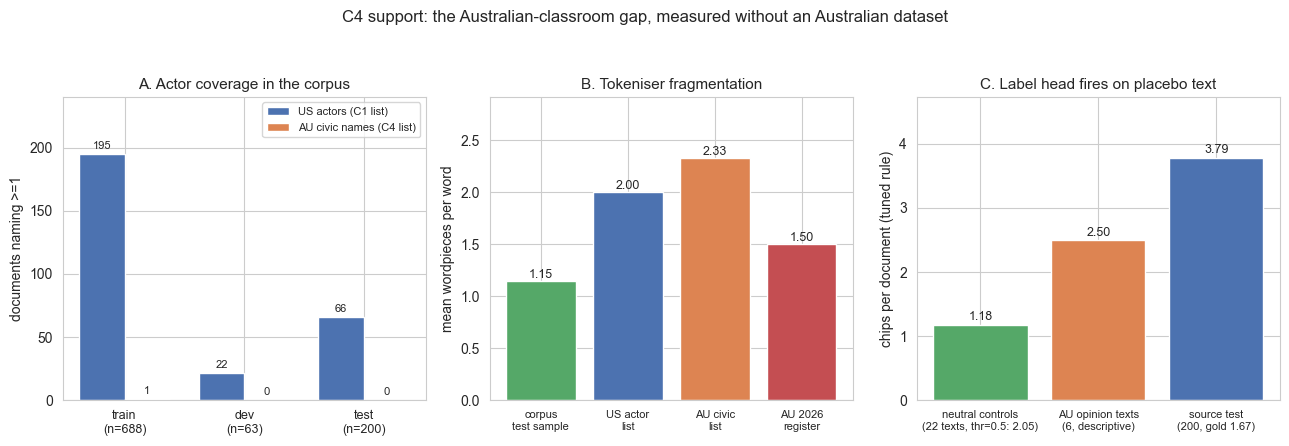

In [ ]:
# Supporting figure: the gap in three panels (coverage, tokeniser, negative controls)
import matplotlib.pyplot as plt

assert "c4_plot" in globals(), "run the C4 evidence cell first - it defines c4_plot"

try:
    import seaborn as _sns
    _sns.set_style("whitegrid")
except Exception:
    plt.style.use("ggplot")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.5))

# panel A: actor coverage in the corpus
_x, _w = [0, 1, 2], 0.38
ax1.bar([i - _w / 2 for i in _x], c4_plot["us"], width=_w, color="#4C72B0", label="US actors (C1 list)")
ax1.bar([i + _w / 2 for i in _x], c4_plot["au"], width=_w, color="#DD8452", label="AU civic names (C4 list)")
for _i, (_u, _a) in enumerate(zip(c4_plot["us"], c4_plot["au"])):
    ax1.text(_i - _w / 2, _u + 4, str(_u), ha="center", fontsize=8)
    ax1.text(_i + _w / 2, _a + 4, str(_a), ha="center", fontsize=8)
ax1.set_xticks(_x)
ax1.set_xticklabels([f"{s}\n(n={n})" for s, n in
                     zip(("train", "dev", "test"), c4_plot["n_split"])], fontsize=9)
ax1.set_ylabel("documents naming >=1")
ax1.set_ylim(0, 240)
ax1.set_title("A. Actor coverage in the corpus", fontsize=11)
ax1.legend(fontsize=8, loc="upper right")

# panel B: tokeniser fragmentation
_order = ["corpus", "US", "AU civic", "AU register"]
_vals = [c4_plot["frag"][k] for k in _order]
ax2.bar(range(4), _vals, color=["#55A868", "#4C72B0", "#DD8452", "#C44E52"])
for _i, _v in enumerate(_vals):
    ax2.text(_i, _v + 0.03, f"{_v:.2f}", ha="center", fontsize=9)
ax2.set_xticks(range(4))
ax2.set_xticklabels(["corpus\ntest sample", "US actor\nlist", "AU civic\nlist", "AU 2026\nregister"],
                    fontsize=8)
ax2.set_ylabel("mean wordpieces per word")
ax2.set_ylim(0, max(_vals) * 1.25)
ax2.set_title("B. Tokeniser fragmentation", fontsize=11)

# panel C: negative-control firing
_vals3 = [c4_plot["neu_mean"], c4_plot["opi_mean"], c4_plot["test_mean"]]
ax3.bar(range(3), _vals3, color=["#55A868", "#DD8452", "#4C72B0"])
for _i, _v in enumerate(_vals3):
    ax3.text(_i, _v + 0.07, f"{_v:.2f}", ha="center", fontsize=9)
ax3.set_xticks(range(3))
ax3.set_xticklabels([f"neutral controls\n(22 texts, thr=0.5: {c4_plot['neu_05']:.2f})",
                     "AU opinion texts\n(6, descriptive)",
                     f"source test\n(200, gold {c4_plot['gold_mean']:.2f})"], fontsize=8)
ax3.set_ylabel("chips per document (tuned rule)")
ax3.set_ylim(0, max(_vals3) * 1.25)
ax3.set_title("C. Label head fires on placebo text", fontsize=11)

fig.suptitle("C4 support: the Australian-classroom gap, measured without an Australian dataset", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])


#### What the evidence shows

The gate first: the rebuilt Part A state reproduces the reported test metrics exactly to four decimals on CPU from the two checkpoints (thr=0.5 micro 0.4265 / macro 0.2004; tuned micro 0.4176 / macro 0.2107). Every model-side number below therefore comes from the same model, thresholds and rules the rest of this notebook reports - nothing was retuned for C4.

- Coverage. US actors are named in 195/688 train, 22/63 dev and 66/200 test documents. Australian civic names appear in 1/688 train, 0/63 dev and 0/200 test, and the single hit is a false positive - "Allan" as the first name of a doctor in a 1901 Leicester hospital caption, not Victoria's premier. The model's political world, inherited from the corpus, contains no Australian public life at all: for a 2026 classroom, every actor, party and controversy it might meet is out of distribution before a word is tokenised.
- Front end. The corpus's own register is nearly whole-word for the tokeniser (1.15 pieces per word, 5.6% of words in three or more pieces) because it is the register the model was fitted on. Australian civic names fragment worst (2.33 pieces per word, 33.3% in three or more); US actor names fragment similarly (2.00, 30.0%) but were seen constantly during fine-tuning, while Australian names never were. The 2026 register list sits lower (1.50, none in three or more pieces - modern slang is largely in-vocabulary as whole words). The clearest number is the emoji string: six emojis collapse into a single [UNK] token. The input channel discards emoji runs wholesale, and a feed meme stripped of its emoji is not the same meme.
- The false-alarm floor. On the 22 neutral Australian texts built to the pre-registered recipe, the tuned-rule label head puts a chip on every single document: mean 1.18 chips per document (2.05 at thr=0.5), 22/22 with at least one chip, none reaching three. Doubt fires on 22/22 - every weather report, every bus timetable - and Loaded Language on 4/22. Against the source test mean of 3.79 chips (gold 1.67), the classroom baseline is not "the tool stays quiet unless there is something to find"; it is "every text gets named". A chip is therefore not a finding: on persuasion-free text it appears at a third of the in-domain rate, which is what a miscalibrated detector under distribution shift looks like.
- Secondary probe, descriptive only (no gold): the six Australian opinion texts drew 1 to 5 chips each (mean 2.5). The chips are not obviously random - "If you support the voice you support division" drew Flag-waving and Slogans alongside Doubt - which fits C1's reading that the tool is a surface-cue detector; whether it caught the right technique is exactly what no label-free instrument can establish.
- What none of this measures: end-task F1 on real Australian memes. Instruments 1 and 2 are corpus and input-layer facts; instrument 3 is a floor on synthetic text, not a rate on real feeds. The only instrument that reaches the classroom is the tally protocol (design cell), and it is deliberately left in the teacher's hands.

#### Verdict for the scenario

- The gap in one line: the corpus gave the model a 2020 American election shouting register; the classroom is 2026 and Australian. Instrument 3 measures the consequence directly - persuasion-free text still gets chips, so on new input a chip carries no information about persuasion at all until the tally says otherwise.
- Not deployment-ready as an assessor, and this evidence makes the case stronger than Part A's F1 alone: the tool names a technique in every document it is shown, including a bus timetable (Doubt 22/22); its pointer head cannot point (test micro F1 0.0310); and nothing in its political world is Australian (1/951 corpus units, a false positive). Defensible classroom use is the inverse of deployment: public material only, chips framed as the model's guesses to argue with, execution local so no student text leaves the device, and the 60% tally gate before any claim-mode display. Run that way, the failures measured here become the lesson. Run as a labeler of students' feed material, the same failures put unsupported propaganda names on screen beside students whose families the corpus never described, with the teacher as the only - unequipped - validator.

Limits of this evidence, stated with it: the neutral controls are synthetic, author-written stand-ins - not a sample of any real feed - and a recipe check cannot prove the absence of subtle cues, though Doubt firing on a bus timetable needs no such argument; the coverage census counts names, not ideas, so Australian politics could in principle appear under US labels (that is what the tally measures); the fragmentation figures characterise the tokeniser, not end-task behaviour; everything model-side comes from one checkpoint, one sweep and one machine, with exact reproduction shown by the gate; and no experiment here touches a student - the first classroom evidence is designed to be gathered by the teacher, with consent, on public material, under the pre-set gate.
